In [48]:
# Imports
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
)

# import tensorflow as tf
# from tensorflow.keras import layers, models as keras_models, callbacks

# Plot style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 6)


In [49]:
#  Load data
# Adjust filename to your actual CSV in the folder:
csv_path = "../data/wesad_features_with_phase_space.csv"

df = pd.read_csv(csv_path)
print("Shape:", df.shape)
display(df.head())

print("\nColumns:", df.columns.tolist())


Shape: (1423, 116)


,Unnamed: 0,EDA_mean,EDA_std,EDA_min,EDA_max,EDA_phasic_mean,EDA_phasic_std,EDA_phasic_min,EDA_phasic_max,EDA_smna_mean,...,Resp_wavelet_energy_low_freq,Resp_wavelet_energy_mid_freq,Resp_wavelet_energy_high_freq,Resp_wavelet_entropy,Resp_wavelet_mean_coeffs,Resp_wavelet_std_coeffs,Resp_wavelet_skew_coeffs,Resp_wavelet_kurt_coeffs,subject,label
0,0,2.951374,0.153235,-309.08,429.27,2.951374,0.084604,-309.08,429.27,2.951374,...,0.0,0.0,18813.100018,6.360669,(-0.0003738574881916235+9.5084501919906e-05j),0.095867,(-36.31166085611055-44.250901951563186j),(-677.6390763712128+3335.2308034761036j),2,1
1,1,2.971346,0.083202,-392.28,554.77,2.971346,0.013430,-392.28,554.77,2.971346,...,0.0,0.0,46499.212841,5.969250,(0.0005900973803959062-3.36396219944322e-05j),0.150717,(41.741791386241346+41.75634763420609j),(-30.078438090306488+3638.965061676656j),2,1
2,2,3.285220,0.096046,-345.19,359.57,3.285220,0.005307,-345.19,359.57,3.285220,...,0.0,0.0,36852.769716,5.809680,(0.0013867477016091259-4.257931578091323e-05j),0.134166,NaN,NaN,2,1
3,3,3.312393,0.094044,-289.26,209.89,3.312393,0.001965,-289.26,209.89,3.312393,...,0.0,0.0,4759.005541,9.286960,(-0.0002522154697395032+0.00011032167031165274j),0.048216,NaN,NaN,2,1
4,4,3.512271,0.070991,-199.01,118.26,3.512271,0.002854,-199.01,118.26,3.512271,...,0.0,0.0,6351.622041,8.424078,(-0.00048462038190719077+0.00011100973844169946j),0.055702,(-33.72692825160861-24.605456683754436j),(369.5933479496858+1817.3315327933244j),2,1



Columns: ['Unnamed: 0', 'EDA_mean', 'EDA_std', 'EDA_min', 'EDA_max', 'EDA_phasic_mean', 'EDA_phasic_std', 'EDA_phasic_min', 'EDA_phasic_max', 'EDA_smna_mean', 'EDA_smna_std', 'EDA_smna_min', 'EDA_smna_max', 'EDA_tonic_mean', 'EDA_tonic_std', 'EDA_tonic_min', 'EDA_tonic_max', 'BVP_mean', 'BVP_std', 'BVP_min', 'BVP_max', 'TEMP_mean', 'TEMP_std', 'TEMP_min', 'TEMP_max', 'ACC_x_mean', 'ACC_x_std', 'ACC_x_min', 'ACC_x_max', 'ACC_y_mean', 'ACC_y_std', 'ACC_y_min', 'ACC_y_max', 'ACC_z_mean', 'ACC_z_std', 'ACC_z_min', 'ACC_z_max', 'Resp_mean', 'Resp_std', 'Resp_min', 'Resp_max', 'net_acc_mean', 'net_acc_std', 'net_acc_min', 'net_acc_max', 'BVP_peak_freq', 'TEMP_slope', 'EDA_poincare_sd1', 'EDA_poincare_sd2', 'EDA_poincare_sd_ratio', 'EDA_poincare_ellipse_area', 'EDA_optimal_tau', 'EDA_lyapunov_exponent', 'EDA_sample_entropy', 'EDA_approx_entropy', 'EDA_dfa_alpha', 'BVP_poincare_sd1', 'BVP_poincare_sd2', 'BVP_poincare_sd_ratio', 'BVP_poincare_ellipse_area', 'BVP_optimal_tau', 'BVP_lyapunov_exp

In [50]:
# Preprocess data

label_col = "label"
subject_col = "subject"

# Keep only label 1 and 2 (binary classification)
df = df[df[label_col].isin([1, 2])].copy()
df.reset_index(drop=True, inplace=True)
print("Shape after filtering labels {1,2}:", df.shape)

# 3.1 – Drop columns that are entirely NaN
nan_cols = df.columns[df.isna().all()].tolist()
print("Columns entirely NaN:", nan_cols)

df = df.drop(columns=nan_cols)
print("Shape after dropping NaN columns:", df.shape)

# 3.2 – Separate label & subject
if subject_col not in df.columns:
    raise ValueError(f"'{subject_col}' column not found in dataframe")

y_raw = df[label_col].values
subjects = df[subject_col].values

# 3.3 – Select numeric feature columns (exclude label & subject)
feature_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in feature_cols if c not in [label_col, subject_col]]

print("Number of numeric feature columns:", len(feature_cols))

X_num = df[feature_cols].copy()

# 3.4 – Fill remaining NaN in rows with column mean
X_num = X_num.fillna(X_num.mean())

# Sanity check
print("Any NaNs left in features?", X_num.isna().any().any())

# Final arrays for modeling
X_raw = X_num.values
y = y_raw.copy()

# (Optional) Map labels {1,2} -> {0,1} for Keras convenience
label_mapping = {1: 0, 2: 1}
y_bin = np.vectorize(label_mapping.get)(y)

print("Label mapping:", label_mapping)
print("Class distribution (mapped):", np.bincount(y_bin))


Shape after filtering labels {1,2}: (1186, 116)
Columns entirely NaN: ['TEMP_wavelet_skew_coeffs', 'TEMP_wavelet_kurt_coeffs']
Shape after dropping NaN columns: (1186, 114)
Number of numeric feature columns: 102
Any NaNs left in features? False
Label mapping: {1: 0, 2: 1}
Class distribution (mapped): [760 426]


In [51]:
# Split subjects into global and personal sets

unique_subjects = np.unique(subjects)
n_subjects = len(unique_subjects)
print("Unique subjects:", unique_subjects)
print("Number of subjects:", n_subjects)

# Choose up to 11 subjects as global (or n_subjects-1 if fewer)
n_global = min(11, n_subjects - 1)
rng = np.random.RandomState(42)
shuffled_subjects = unique_subjects.copy()
rng.shuffle(shuffled_subjects)

global_subjects = shuffled_subjects[:n_global]
personal_subjects = shuffled_subjects[n_global:]

print("Global subjects:", global_subjects)
print("Personal subjects:", personal_subjects)


Unique subjects: [ 2  3  4  5  6  7  8  9 10 11 13 14 15 16 17]
Number of subjects: 15
Global subjects: [11 14  2 16  7 10  4  3 17  6  9]
Personal subjects: [13 15  5  8]


In [52]:
# Helper to fit StandardScaler on train only

def scale_train_test(X_train, X_test):
    """
    Fit StandardScaler on X_train ONLY, then transform both X_train and X_test.
    """
    scaler = StandardScaler().fit(X_train)
    X_train_scaled = scaler.transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    return X_train_scaled, X_test_scaled, scaler


## EDA

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

# Set style for professional plots
sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1.1)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['figure.facecolor'] = 'white'

print("✓ All libraries imported successfully!")

✓ All libraries imported successfully!


In [54]:
# MODIFY THESE VARIABLES FOR YOUR DATA
# Assuming you have:
# - X_num: DataFrame with numeric features
# - y: Series with labels
# - subjects: Series with subject IDs

# Example: Create df_plot
df_plot = X_num.copy()
label_col = 'activity'  # CHANGE THIS to your label column name
subject_col = 'subject'  # CHANGE THIS to your subject column name

df_plot[label_col] = y
df_plot[subject_col] = subjects

print(f"Dataset shape: {df_plot.shape}")
print(f"Columns: {df_plot.columns.tolist()[:5]}... (showing first 5)")


Dataset shape: (1186, 104)
Columns: ['Unnamed: 0', 'EDA_mean', 'EDA_std', 'EDA_min', 'EDA_max']... (showing first 5)


In [55]:
# Extract components
feature_cols = [col for col in df_plot.columns if col not in [label_col, subject_col]]
X = df_plot[feature_cols]
y = df_plot[label_col]
subjects = df_plot[subject_col]

# Get unique classes and subjects
classes = sorted(y.unique())
unique_subjects = sorted(subjects.unique())
n_classes = len(classes)
n_subjects = len(unique_subjects)
n_features = len(feature_cols)

# Define color palette (use correct Seaborn palette name)
palette = sns.color_palette("Set2")
colors_dict = dict(zip(classes, palette))

print("="*80)
print("EXPLORATORY DATA ANALYSIS REPORT")
print("="*80)
print(f"\nDataset Overview:")
print(f"  • Total samples: {len(df_plot):,}")
print(f"  • Number of features: {n_features}")
print(f"  • Number of classes: {n_classes}")
print(f"  • Number of subjects: {n_subjects}")
print(f"  • Classes: {classes}")
print(f"\nClass Distribution:")
for cls in classes:
    count = (y == cls).sum()
    pct = 100 * count / len(y)
    print(f"  • {cls}: {count:,} samples ({pct:.2f}%)")

EXPLORATORY DATA ANALYSIS REPORT

Dataset Overview:
  • Total samples: 1,186
  • Number of features: 102
  • Number of classes: 2
  • Number of subjects: 15
  • Classes: [np.int64(1), np.int64(2)]

Class Distribution:
  • 1: 760 samples (64.08%)
  • 2: 426 samples (35.92%)


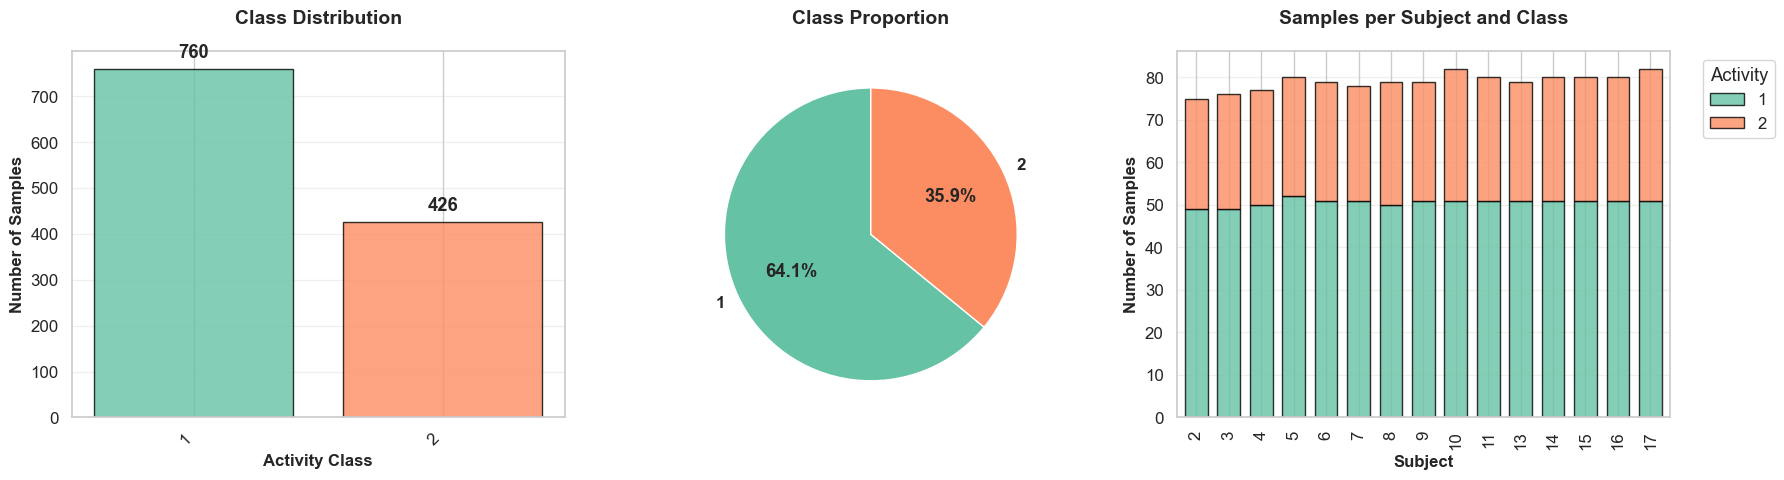

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Bar plot
class_counts = y.value_counts().reindex(classes)
axes[0].bar(range(n_classes), class_counts.values, color=palette, alpha=0.8, edgecolor='black')
axes[0].set_xlabel('Activity Class', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Samples', fontsize=12, fontweight='bold')
axes[0].set_title('Class Distribution', fontsize=14, fontweight='bold', pad=20)
axes[0].set_xticks(range(n_classes))
axes[0].set_xticklabels(classes, rotation=45, ha='right')
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + max(class_counts.values)*0.02, f'{v:,}', 
                ha='center', va='bottom', fontweight='bold')

# Pie chart
axes[1].pie(class_counts.values, labels=classes, autopct='%1.1f%%', 
            colors=palette, startangle=90, textprops={'fontweight': 'bold'})
axes[1].set_title('Class Proportion', fontsize=14, fontweight='bold', pad=20)

# Subjects per class
subject_class_counts = df_plot.groupby([label_col, subject_col]).size().unstack(fill_value=0)
subject_class_counts.T.plot(kind='bar', stacked=True, ax=axes[2], color=palette, 
                            alpha=0.8, edgecolor='black', width=0.7)
axes[2].set_xlabel('Subject', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Number of Samples', fontsize=12, fontweight='bold')
axes[2].set_title('Samples per Subject and Class', fontsize=14, fontweight='bold', pad=20)
axes[2].legend(title='Activity', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

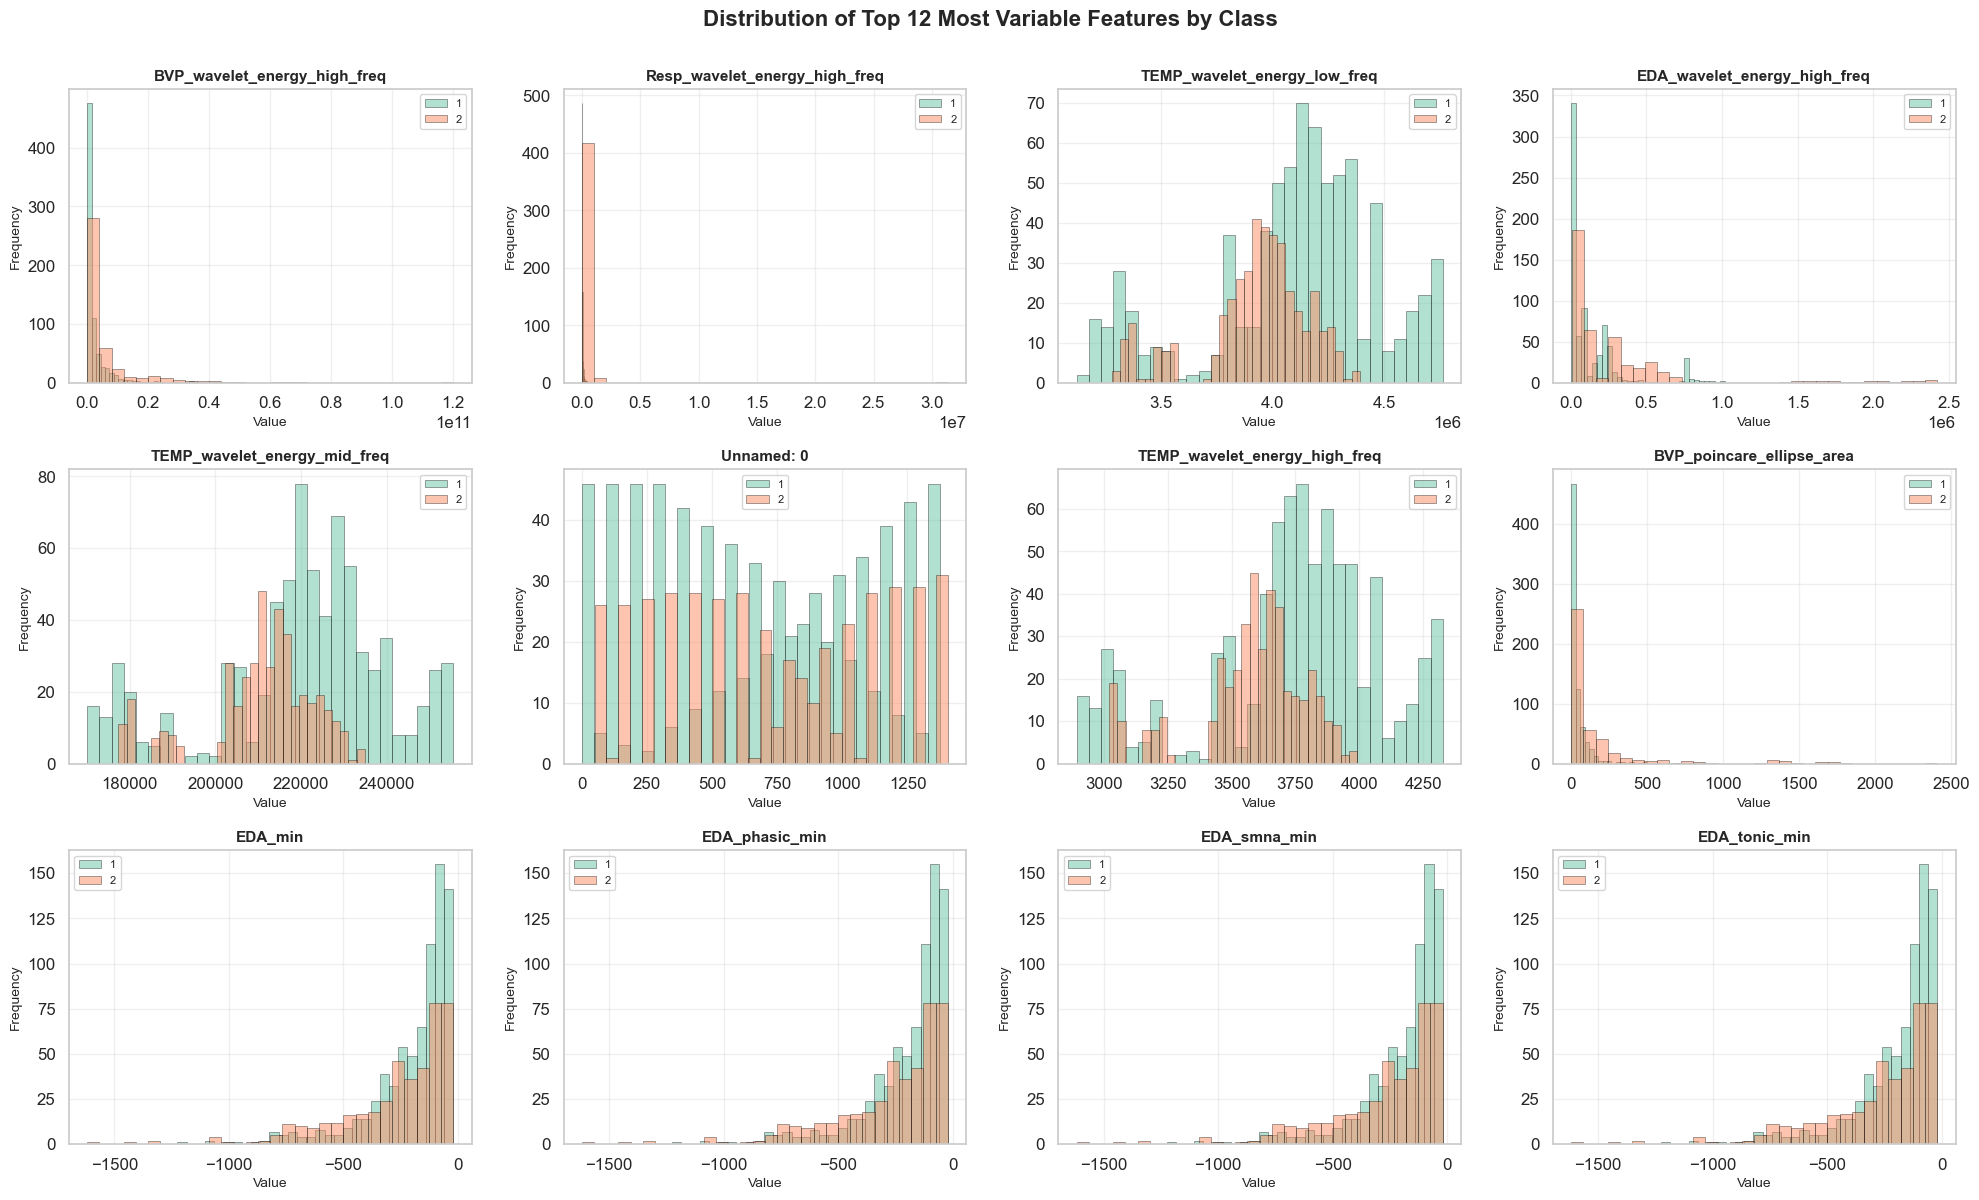

In [57]:
# Select top features with highest variance (use feature-wise std from X)
top_var_features = X.std().nlargest(12).index.tolist()

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

for idx, feature in enumerate(top_var_features):
    for cls in classes:
        data = X.loc[y == cls, feature]
        axes[idx].hist(data, bins=30, alpha=0.5, label=str(cls), 
                      color=colors_dict[cls], edgecolor='black', linewidth=0.5)
    
    axes[idx].set_xlabel('Value', fontsize=10)
    axes[idx].set_ylabel('Frequency', fontsize=10)
    axes[idx].set_title(f'{feature}', fontsize=11, fontweight='bold')
    axes[idx].legend(fontsize=8, frameon=True)
    axes[idx].grid(alpha=0.3)

plt.suptitle('Distribution of Top 12 Most Variable Features by Class', 
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

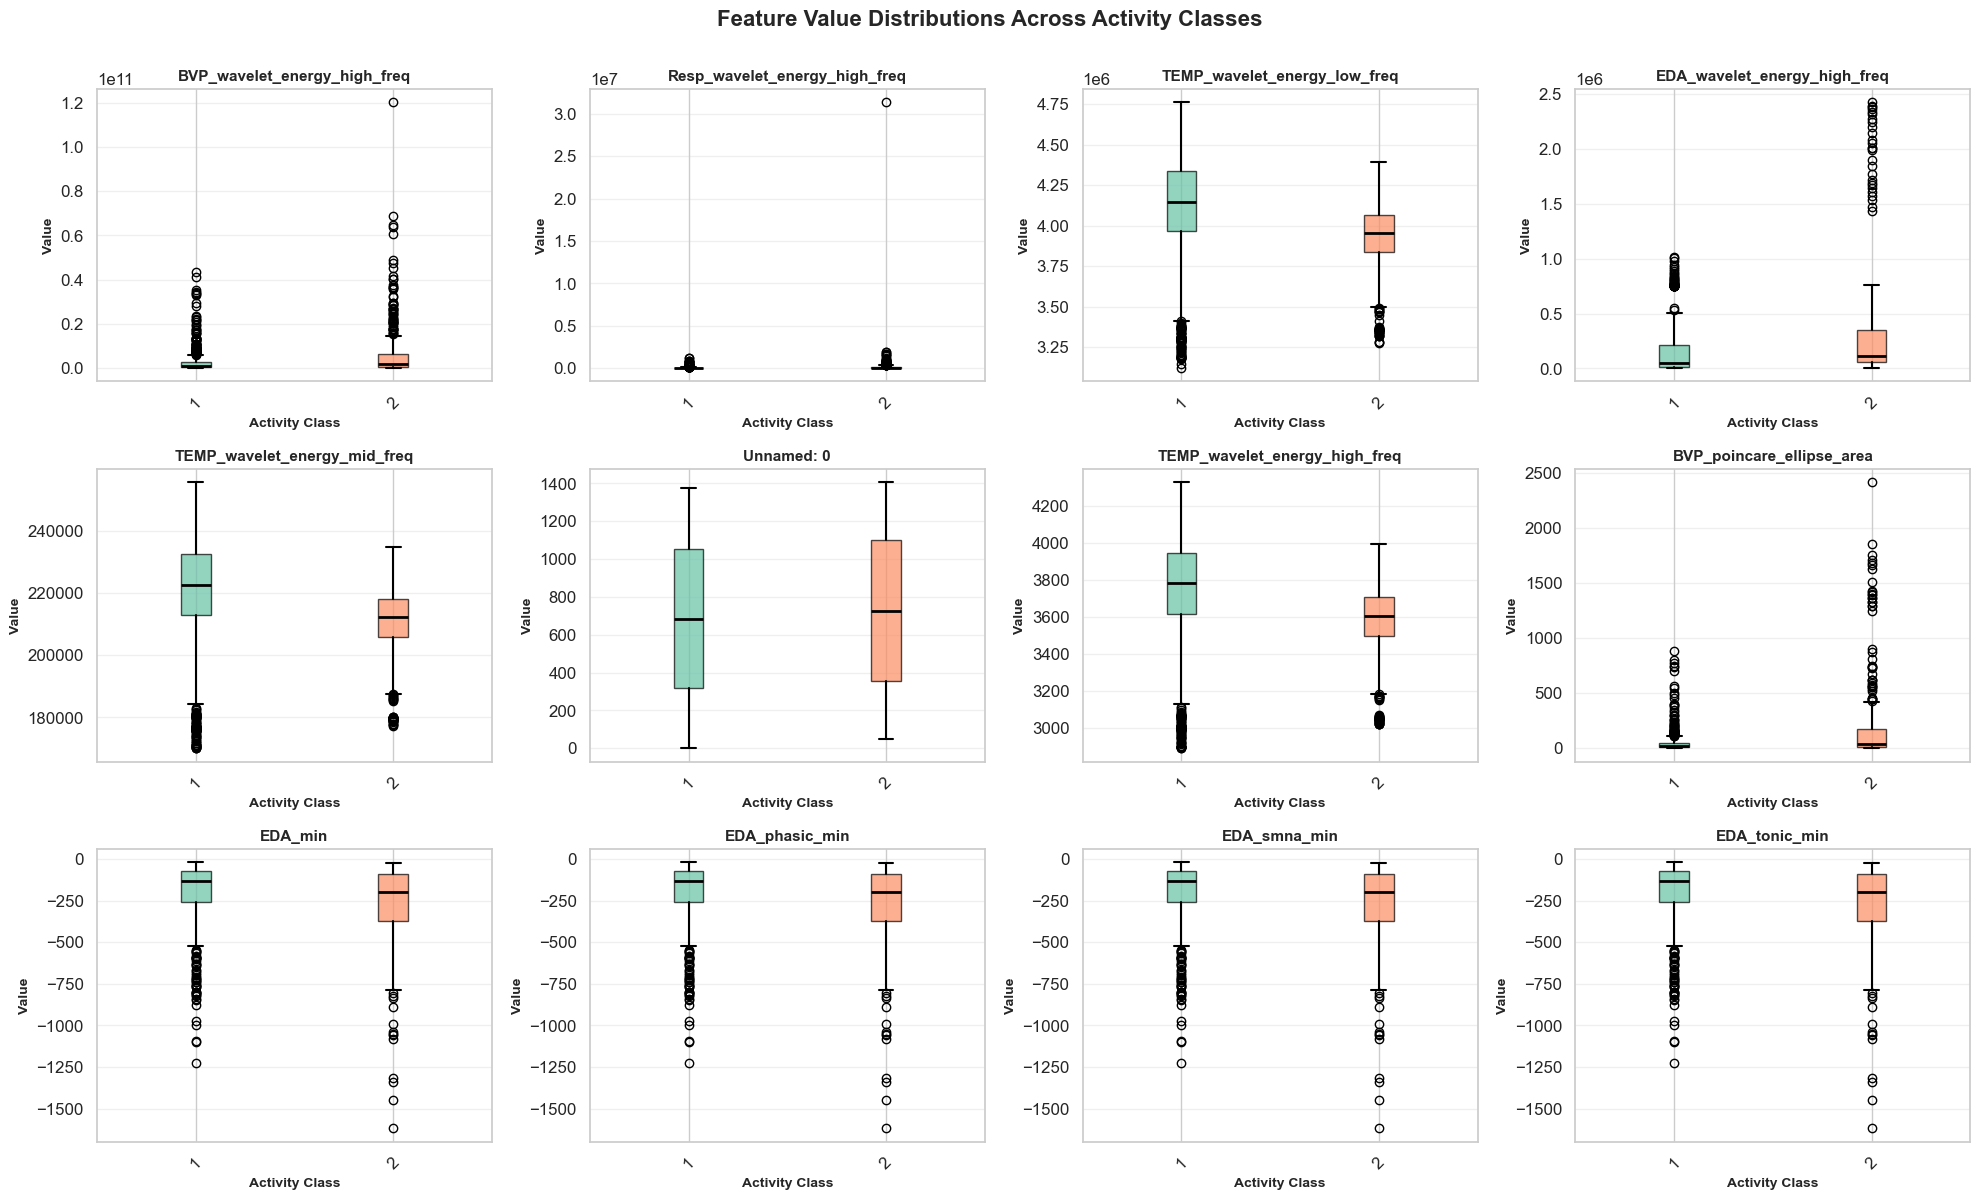

In [58]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

for idx, feature in enumerate(top_var_features):
    data_list = [X.loc[y == cls, feature].values for cls in classes]
    bp = axes[idx].boxplot(data_list, labels=classes, patch_artist=True,
                           medianprops=dict(color='black', linewidth=2),
                           whiskerprops=dict(linewidth=1.5),
                           capprops=dict(linewidth=1.5))
    
    for patch, color in zip(bp['boxes'], palette):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    axes[idx].set_xlabel('Activity Class', fontsize=10, fontweight='bold')
    axes[idx].set_ylabel('Value', fontsize=10, fontweight='bold')
    axes[idx].set_title(f'{feature}', fontsize=11, fontweight='bold')
    axes[idx].grid(axis='y', alpha=0.3)
    axes[idx].tick_params(axis='x', rotation=45)

plt.suptitle('Feature Value Distributions Across Activity Classes', 
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

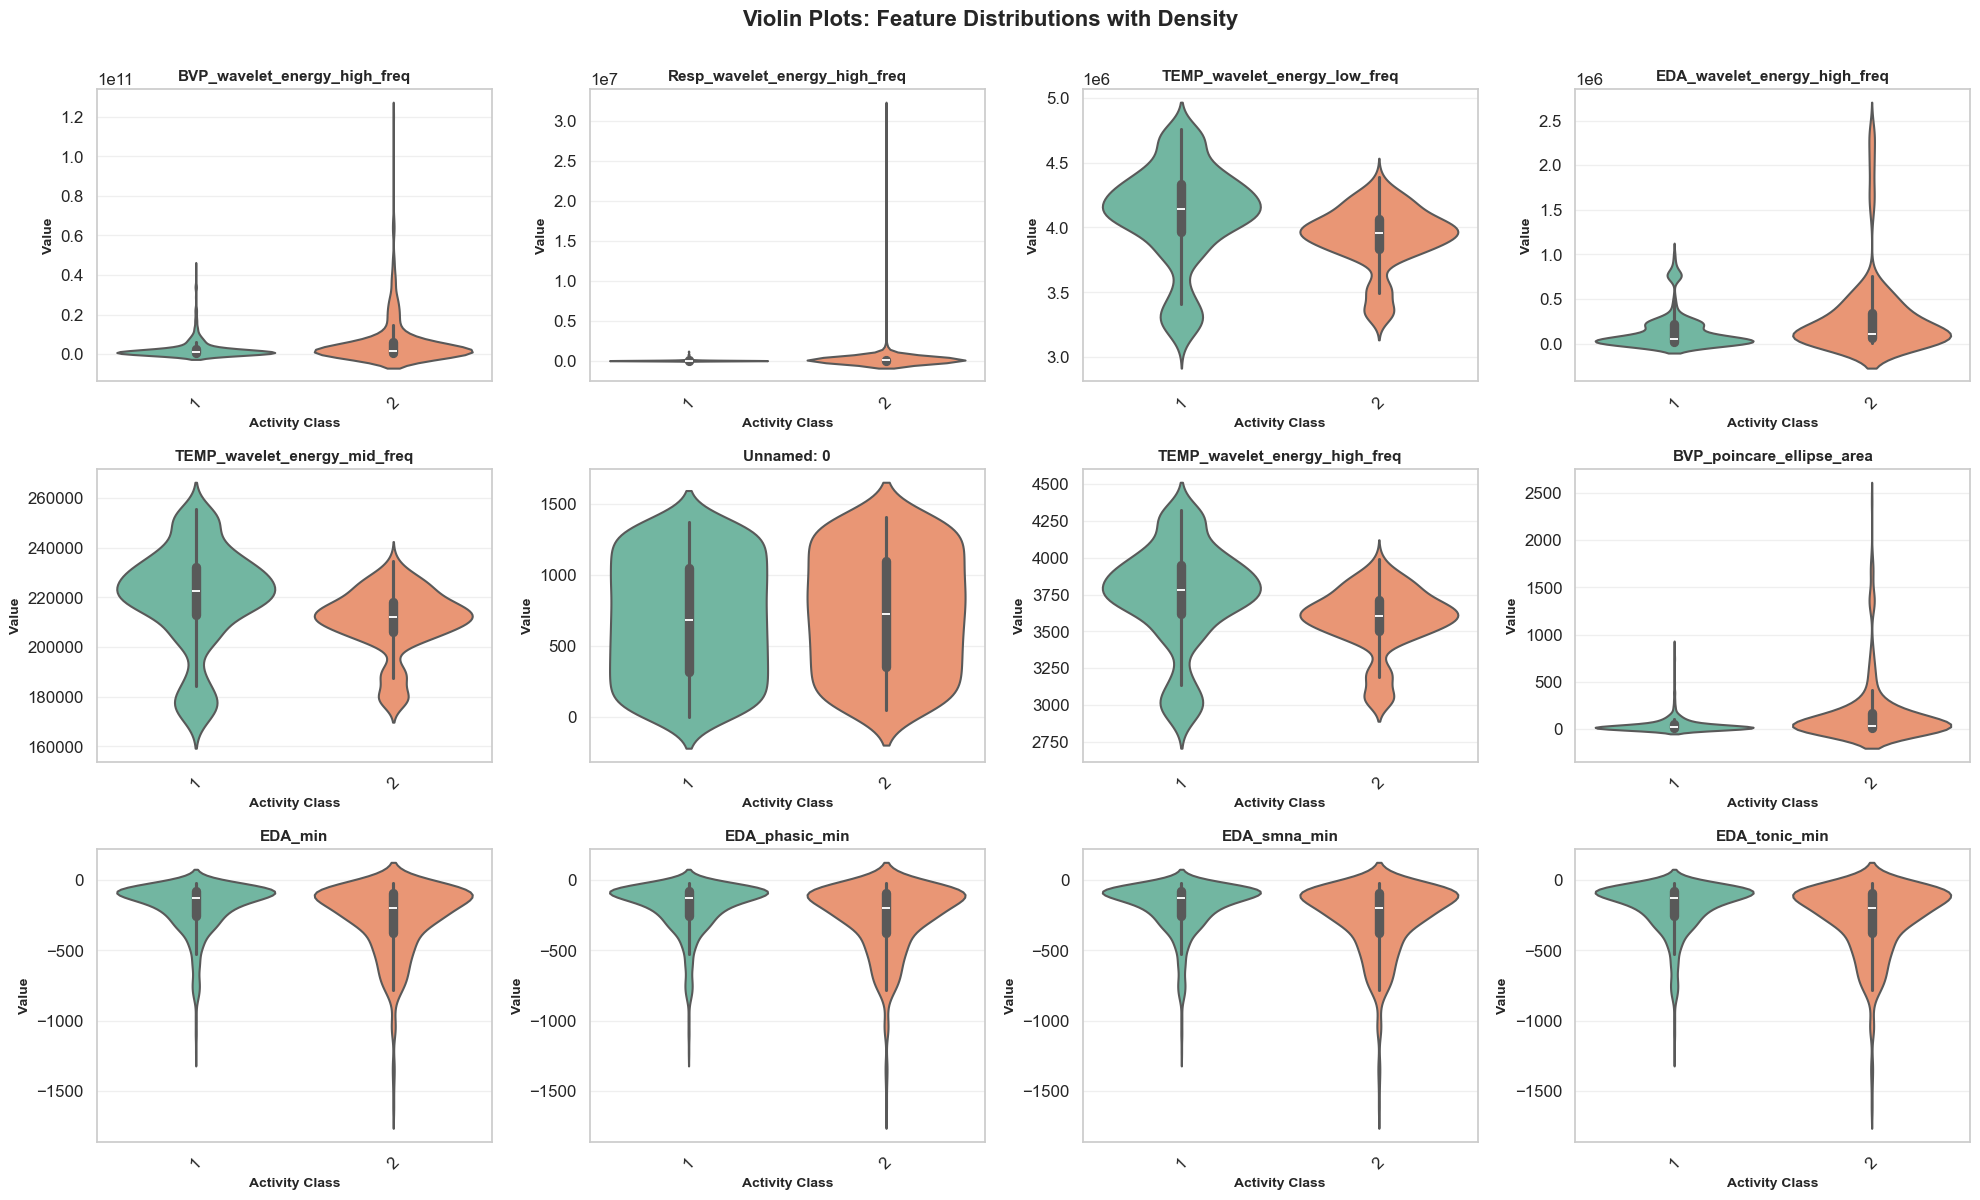

In [59]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

for idx, feature in enumerate(top_var_features):
    plot_df = pd.DataFrame({
        'value': X[feature],
        'class': y
    })
    
    sns.violinplot(data=plot_df, x='class', y='value', ax=axes[idx],
                  palette=palette, inner='box', linewidth=1.5)
    
    axes[idx].set_xlabel('Activity Class', fontsize=10, fontweight='bold')
    axes[idx].set_ylabel('Value', fontsize=10, fontweight='bold')
    axes[idx].set_title(f'{feature}', fontsize=11, fontweight='bold')
    axes[idx].grid(axis='y', alpha=0.3)
    axes[idx].tick_params(axis='x', rotation=45)

plt.suptitle('Violin Plots: Feature Distributions with Density', 
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

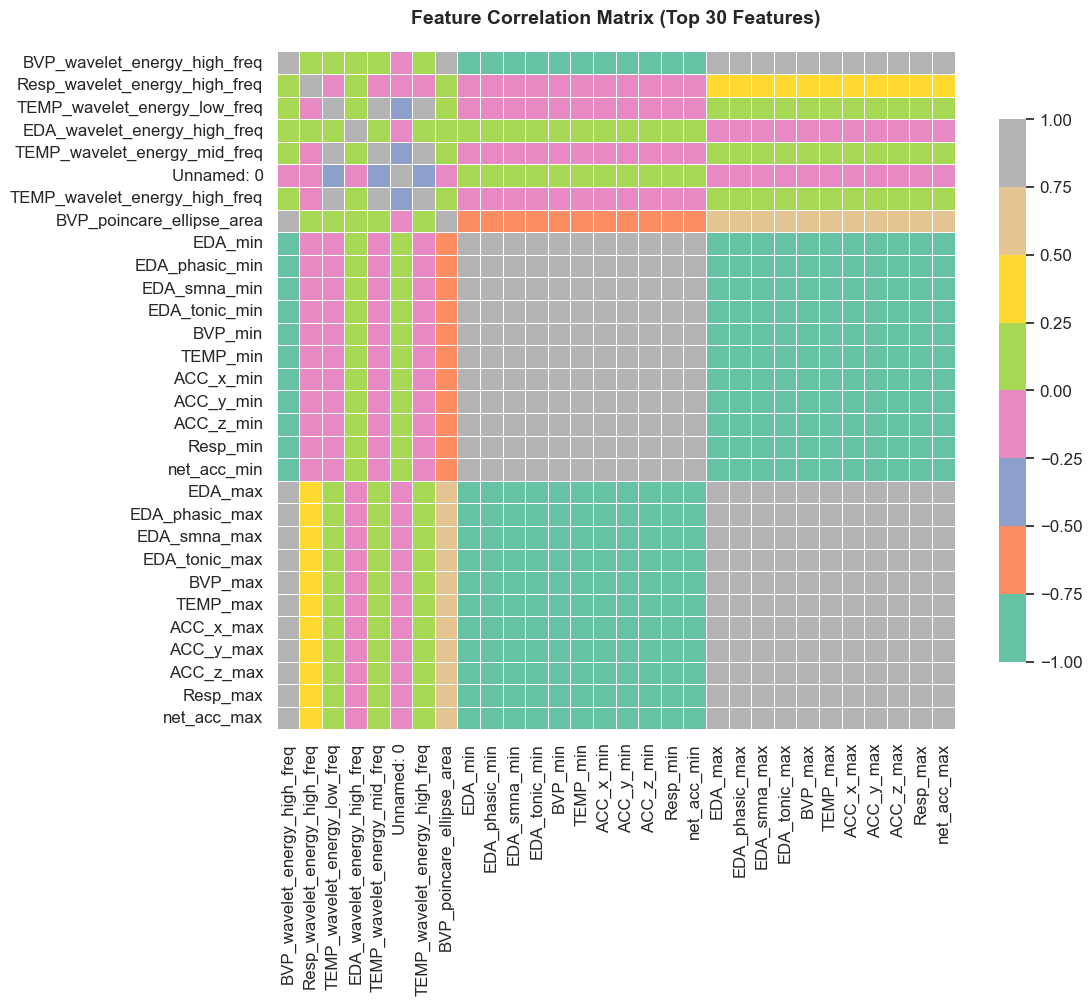

Found 268 highly correlated feature pairs (|r| > 0.7)


In [60]:
# Sample features for correlation
sample_features = X.std().nlargest(30).index.tolist()
corr_matrix = X[sample_features].corr()

# Create single plot
fig, ax = plt.subplots(figsize=(12, 10))

# Full correlation heatmap with Set2 palette
sns.heatmap(corr_matrix, cmap='Set2', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            ax=ax, annot=False)

ax.set_title('Feature Correlation Matrix (Top 30 Features)', 
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

# Optional: Print correlation statistics
high_corr = np.where(np.abs(corr_matrix) > 0.7)
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y], corr_matrix.iloc[x, y])
                   for x, y in zip(*high_corr) if x < y]
print(f"Found {len(high_corr_pairs)} highly correlated feature pairs (|r| > 0.7)")

Performing statistical significance tests...


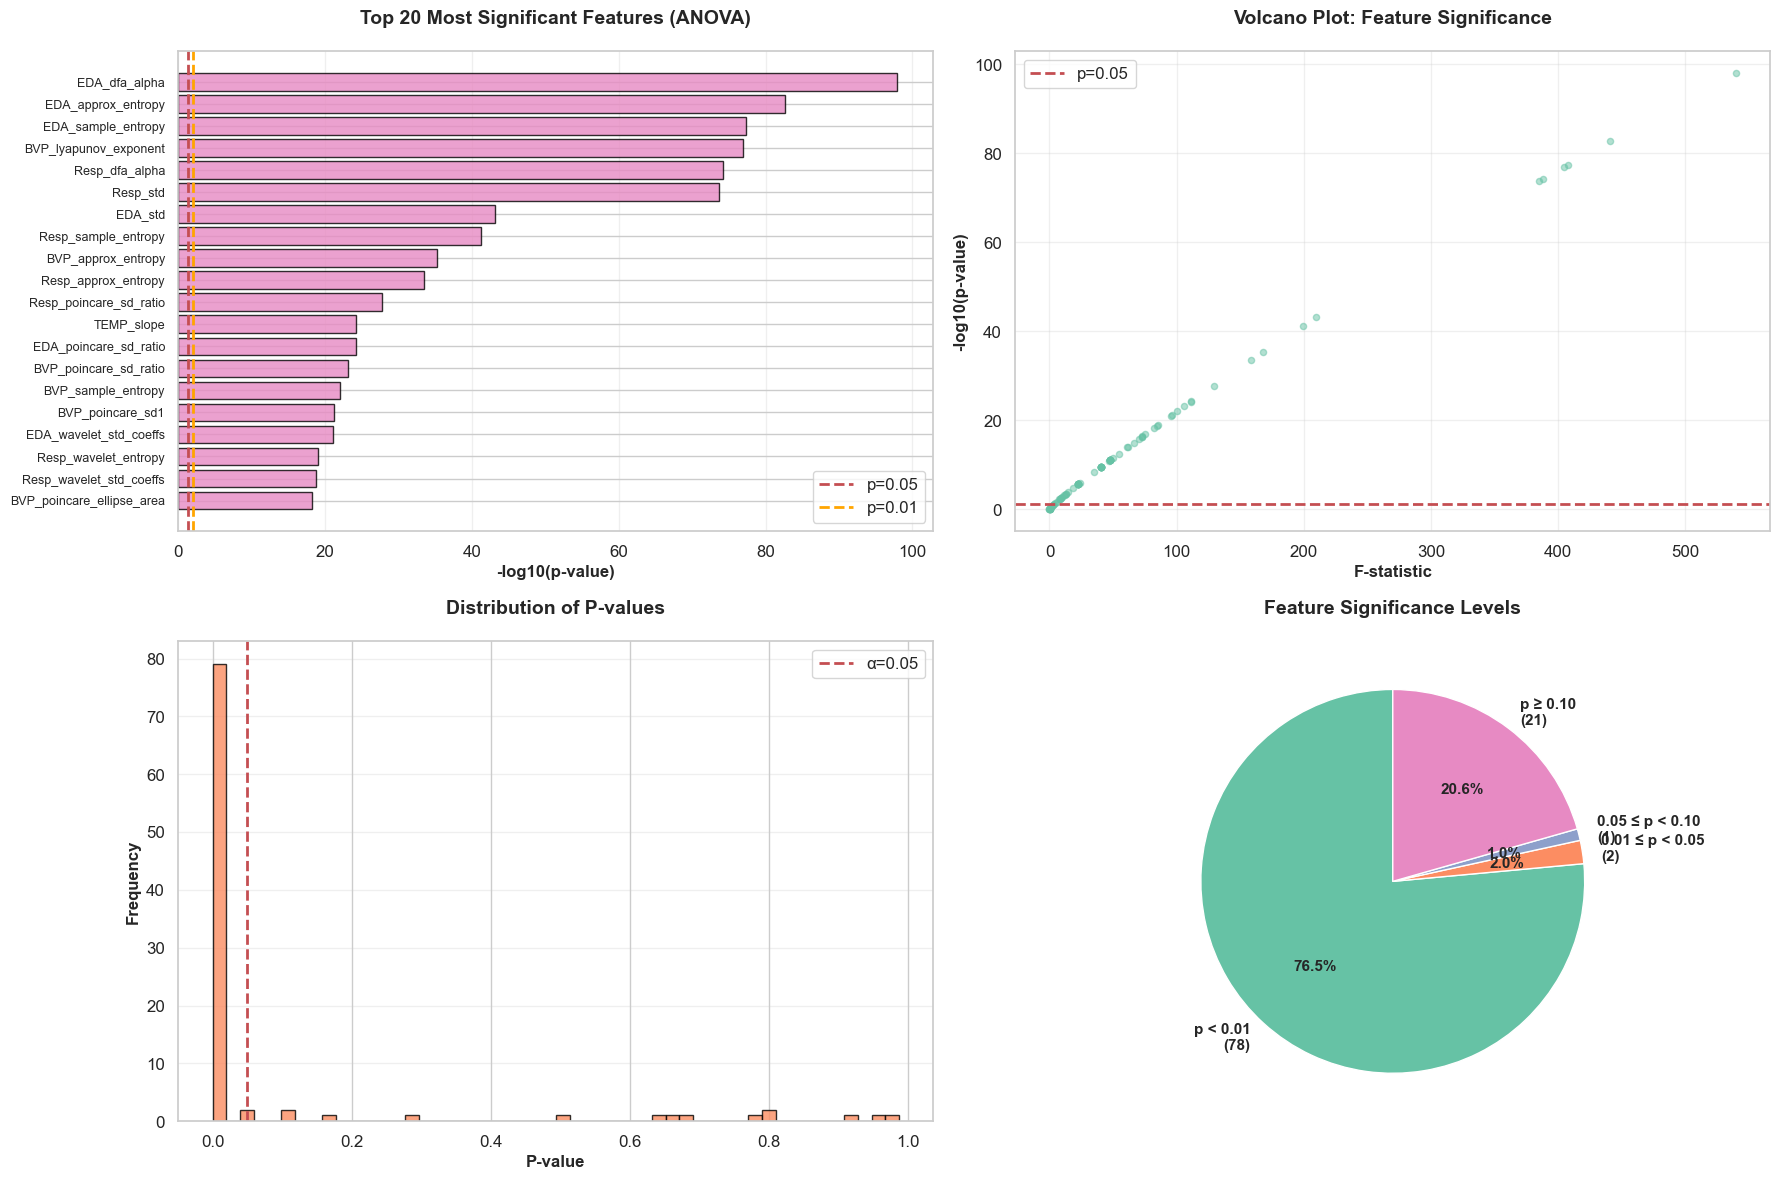

✓ 78 features significant at p < 0.01
✓ 80 features significant at p < 0.05


In [61]:
print("Performing statistical significance tests...")

# Perform ANOVA for each feature
f_stats = []
p_values = []

for feature in feature_cols:
    groups = [X.loc[y == cls, feature].values for cls in classes]
    f_stat, p_val = stats.f_oneway(*groups)
    f_stats.append(f_stat)
    p_values.append(p_val)

# Create significance DataFrame
significance_df = pd.DataFrame({
    'Feature': feature_cols,
    'F-statistic': f_stats,
    'P-value': p_values,
    '-log10(p)': -np.log10(np.array(p_values) + 1e-300)
}).sort_values('-log10(p)', ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Top significant features
top_20_sig = significance_df.head(20)
axes[0, 0].barh(range(len(top_20_sig)), top_20_sig['-log10(p)'].values,
                color=sns.color_palette("Set2")[3], alpha=0.8, edgecolor='black')
axes[0, 0].set_yticks(range(len(top_20_sig)))
axes[0, 0].set_yticklabels(top_20_sig['Feature'].values, fontsize=9)
axes[0, 0].set_xlabel('-log10(p-value)', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Top 20 Most Significant Features (ANOVA)', 
                    fontsize=14, fontweight='bold', pad=20)
axes[0, 0].axvline(x=-np.log10(0.05), color='r', linestyle='--', linewidth=2, label='p=0.05')
axes[0, 0].axvline(x=-np.log10(0.01), color='orange', linestyle='--', linewidth=2, label='p=0.01')
axes[0, 0].legend()
axes[0, 0].grid(axis='x', alpha=0.3)
axes[0, 0].invert_yaxis()

# Volcano plot
axes[0, 1].scatter(significance_df['F-statistic'], significance_df['-log10(p)'],
                  alpha=0.5, s=20, c=sns.color_palette("Set2")[0])
axes[0, 1].axhline(y=-np.log10(0.05), color='r', linestyle='--', linewidth=2, label='p=0.05')
axes[0, 1].set_xlabel('F-statistic', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('-log10(p-value)', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Volcano Plot: Feature Significance', fontsize=14, fontweight='bold', pad=20)
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# P-value distribution
axes[1, 0].hist(p_values, bins=50, color=sns.color_palette("Set2")[1], 
               alpha=0.8, edgecolor='black')
axes[1, 0].axvline(x=0.05, color='r', linestyle='--', linewidth=2, label='α=0.05')
axes[1, 0].set_xlabel('P-value', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Distribution of P-values', fontsize=14, fontweight='bold', pad=20)
axes[1, 0].legend()
axes[1, 0].grid(axis='y', alpha=0.3)

# Significance summary
sig_001 = (significance_df['P-value'] < 0.01).sum()
sig_005 = (significance_df['P-value'] < 0.05).sum()
sig_010 = (significance_df['P-value'] < 0.10).sum()
not_sig = len(significance_df) - sig_010

labels = [f'p < 0.01\n({sig_001})', f'0.01 ≤ p < 0.05\n({sig_005-sig_001})', 
          f'0.05 ≤ p < 0.10\n({sig_010-sig_005})', f'p ≥ 0.10\n({not_sig})']
sizes = [sig_001, sig_005-sig_001, sig_010-sig_005, not_sig]
colors_pie = sns.color_palette("Set2", 4)

axes[1, 1].pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors_pie, 
              startangle=90, textprops={'fontweight': 'bold', 'fontsize': 11})
axes[1, 1].set_title('Feature Significance Levels', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

print(f"✓ {sig_001} features significant at p < 0.01")
print(f"✓ {sig_005} features significant at p < 0.05")

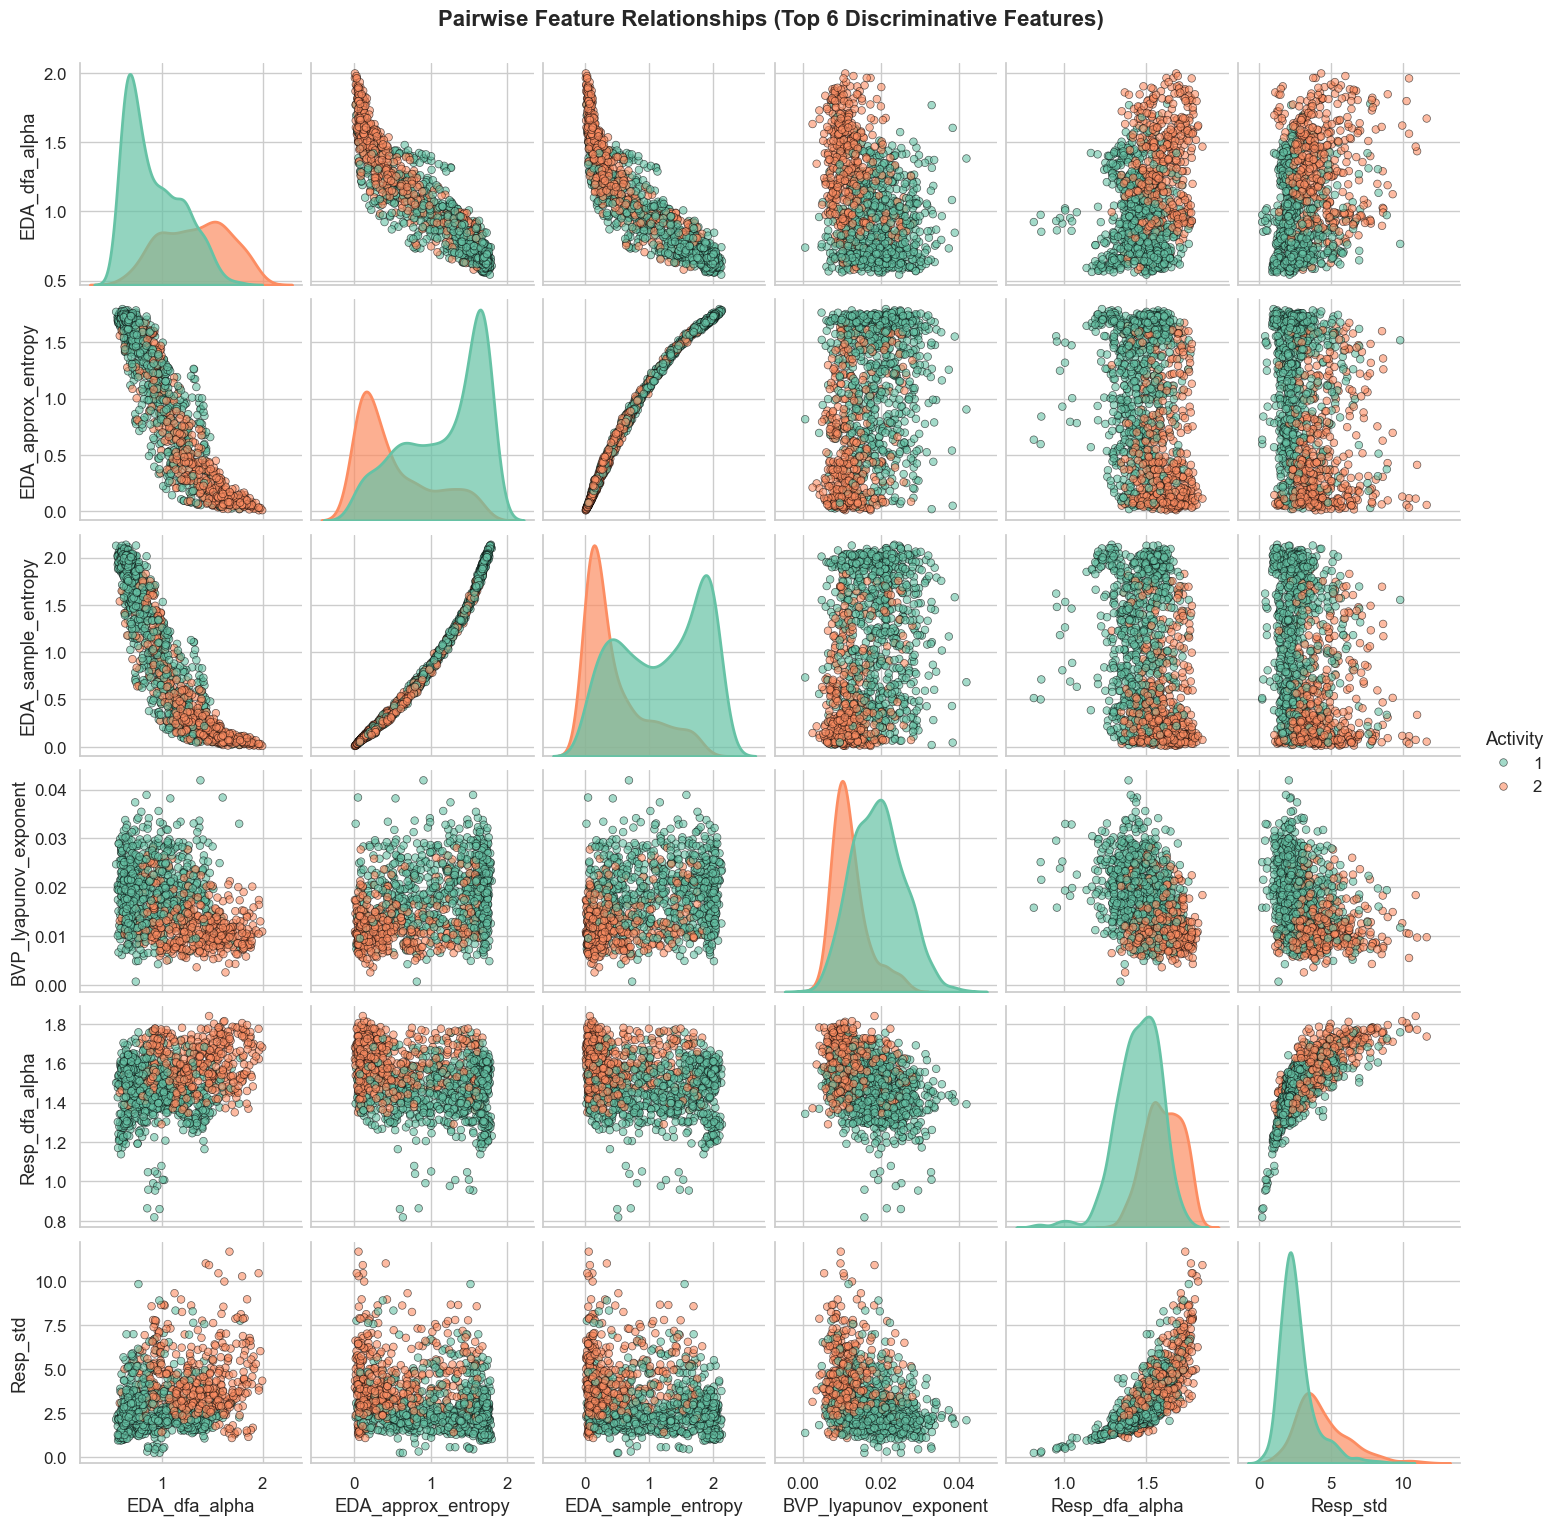

In [62]:
# Select top 6 most discriminative features
top_features_pair = significance_df.head(6)['Feature'].values

# Create pairplot
plot_data = pd.DataFrame(X[top_features_pair])
plot_data['Activity'] = y.values

g = sns.pairplot(plot_data, hue='Activity', palette=palette, 
                 diag_kind='kde', plot_kws={'alpha': 0.6, 's': 30, 'edgecolor': 'black', 'linewidth': 0.5},
                 diag_kws={'alpha': 0.7, 'linewidth': 2})
g.fig.suptitle('Pairwise Feature Relationships (Top 6 Discriminative Features)', 
               fontsize=16, fontweight='bold', y=1.02)

plt.show()

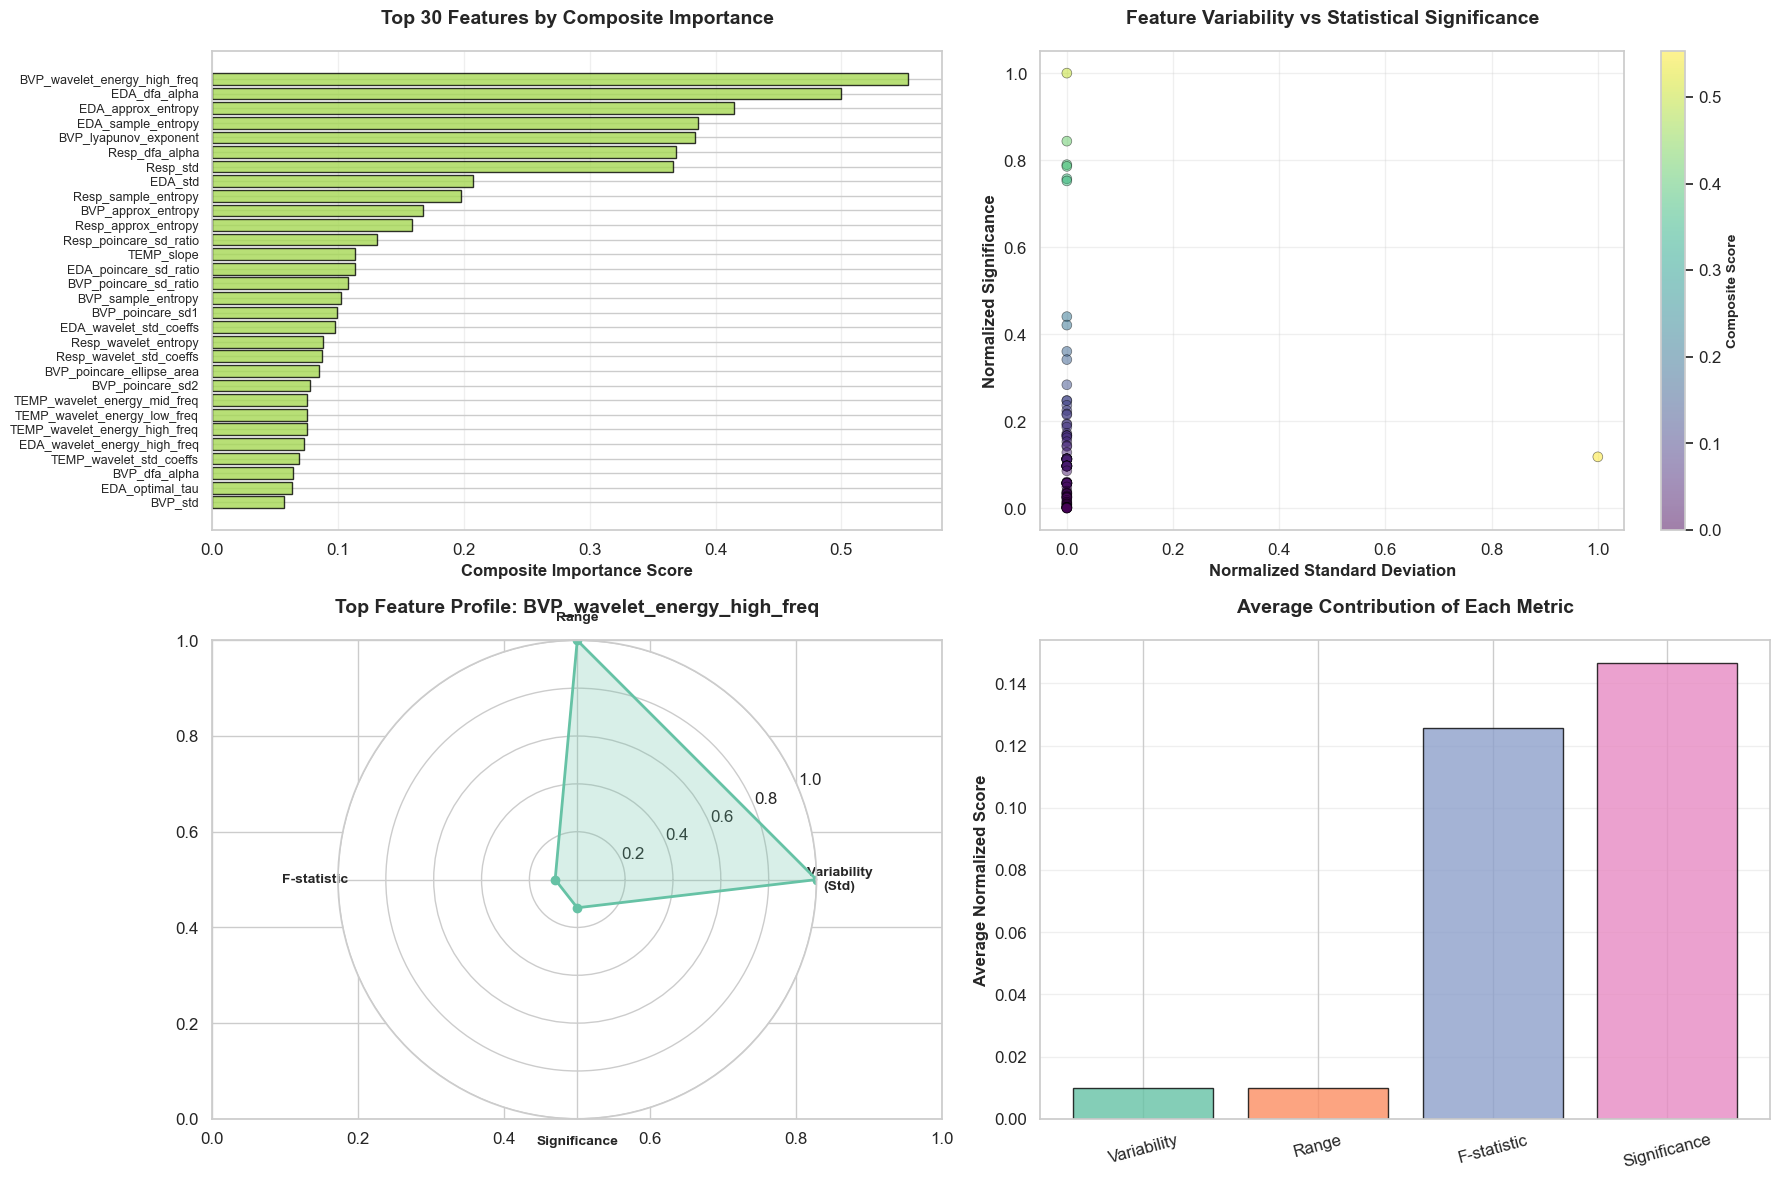

In [63]:
# Combine different metrics
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Std': X.std().values,
    'Range': X.max().values - X.min().values,
    'F-statistic': f_stats,
    '-log10(p)': -np.log10(np.array(p_values) + 1e-300)
})

# Normalize metrics
scaler = MinMaxScaler()
importance_df['Std_norm'] = scaler.fit_transform(importance_df[['Std']])
importance_df['Range_norm'] = scaler.fit_transform(importance_df[['Range']])
importance_df['F-stat_norm'] = scaler.fit_transform(importance_df[['F-statistic']])
importance_df['Significance_norm'] = scaler.fit_transform(importance_df[['-log10(p)']])

# Composite score
importance_df['Composite_Score'] = (importance_df['Std_norm'] + 
                                    importance_df['Range_norm'] + 
                                    importance_df['F-stat_norm'] + 
                                    importance_df['Significance_norm']) / 4

importance_df = importance_df.sort_values('Composite_Score', ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Composite importance
top_30 = importance_df.head(30)
axes[0, 0].barh(range(len(top_30)), top_30['Composite_Score'].values,
                color=sns.color_palette("Set2")[4], alpha=0.8, edgecolor='black')
axes[0, 0].set_yticks(range(len(top_30)))
axes[0, 0].set_yticklabels(top_30['Feature'].values, fontsize=9)
axes[0, 0].set_xlabel('Composite Importance Score', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Top 30 Features by Composite Importance', 
                    fontsize=14, fontweight='bold', pad=20)
axes[0, 0].grid(axis='x', alpha=0.3)
axes[0, 0].invert_yaxis()

# Scatter: Variability vs Significance
scatter = axes[0, 1].scatter(importance_df['Std_norm'], importance_df['Significance_norm'],
                  alpha=0.5, s=50, c=importance_df['Composite_Score'], 
                  cmap='viridis', edgecolor='black', linewidth=0.5)
axes[0, 1].set_xlabel('Normalized Standard Deviation', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Normalized Significance', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Feature Variability vs Statistical Significance', 
                    fontsize=14, fontweight='bold', pad=20)
axes[0, 1].grid(alpha=0.3)
cbar = plt.colorbar(scatter, ax=axes[0, 1])
cbar.set_label('Composite Score', fontsize=10, fontweight='bold')

# Radar chart for top feature
top_feature = importance_df.iloc[0]
categories = ['Variability\n(Std)', 'Range', 'F-statistic', 'Significance']
values = [top_feature['Std_norm'], top_feature['Range_norm'], 
          top_feature['F-stat_norm'], top_feature['Significance_norm']]

angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
values += values[:1]
angles += angles[:1]

axes[1, 0] = plt.subplot(223, projection='polar')
axes[1, 0].plot(angles, values, 'o-', linewidth=2, color=sns.color_palette("Set2")[0])
axes[1, 0].fill(angles, values, alpha=0.25, color=sns.color_palette("Set2")[0])
axes[1, 0].set_xticks(angles[:-1])
axes[1, 0].set_xticklabels(categories, fontsize=10, fontweight='bold')
axes[1, 0].set_ylim(0, 1)
axes[1, 0].set_title(f'Top Feature Profile: {top_feature["Feature"]}', 
                    fontsize=14, fontweight='bold', pad=20)
axes[1, 0].grid(True)

# Component contribution
component_names = ['Variability', 'Range', 'F-statistic', 'Significance']
component_means = [importance_df['Std_norm'].mean(), 
                  importance_df['Range_norm'].mean(),
                  importance_df['F-stat_norm'].mean(), 
                  importance_df['Significance_norm'].mean()]

axes[1, 1].bar(component_names, component_means, 
              color=sns.color_palette("Set2"), alpha=0.8, edgecolor='black')
axes[1, 1].set_ylabel('Average Normalized Score', fontsize=12, fontweight='bold')
axes[1, 1].set_title('Average Contribution of Each Metric', 
                    fontsize=14, fontweight='bold', pad=20)
axes[1, 1].grid(axis='y', alpha=0.3)
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Number of components for >=95% variance: 27


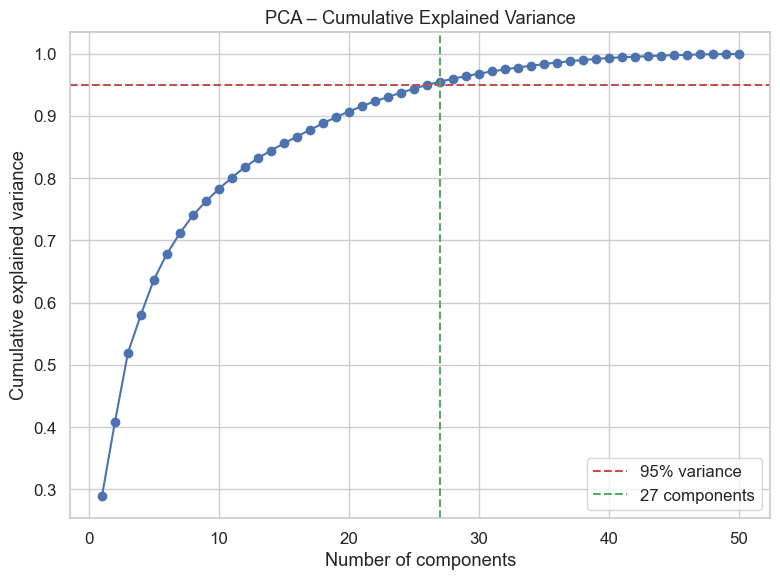

In [64]:
# PCA (fit on all data for EDA) and explained variance

# Standardize all features for PCA-based EDA
scaler_all = StandardScaler().fit(X_raw)
X_scaled_all = scaler_all.transform(X_raw)

# Limit number of components to num_features
n_features = X_scaled_all.shape[1]
n_pca = min(50, n_features)  # limit to 50 for speed/plots

pca = PCA(n_components=n_pca)
X_pca = pca.fit_transform(X_scaled_all)

expl_var = pca.explained_variance_ratio_
cum_expl_var = np.cumsum(expl_var)

# Find number of components for 95% variance
n_95 = np.argmax(cum_expl_var >= 0.95) + 1
print(f"Number of components for >=95% variance: {n_95}")

# Plot cumulative explained variance
plt.figure()
plt.plot(range(1, n_pca + 1), cum_expl_var, marker="o")
plt.axhline(y=0.95, color="r", linestyle="--", label="95% variance")
plt.axvline(x=n_95, color="g", linestyle="--", label=f"{n_95} components")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA – Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


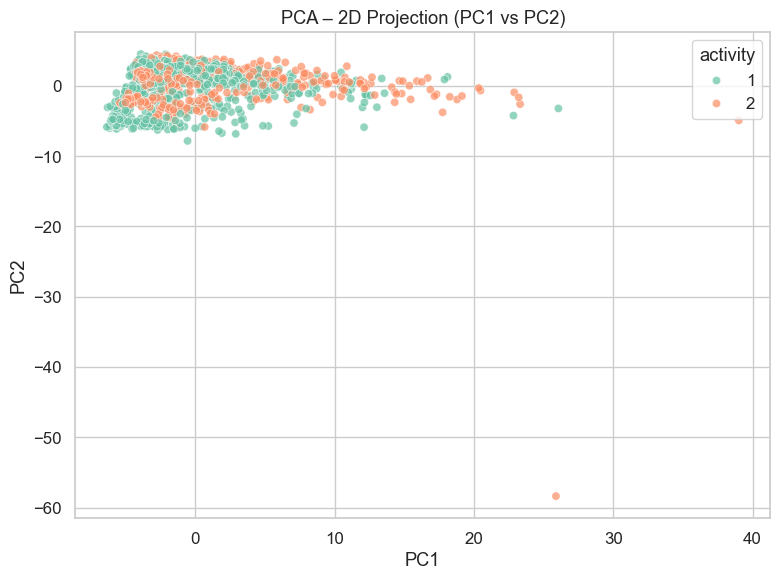

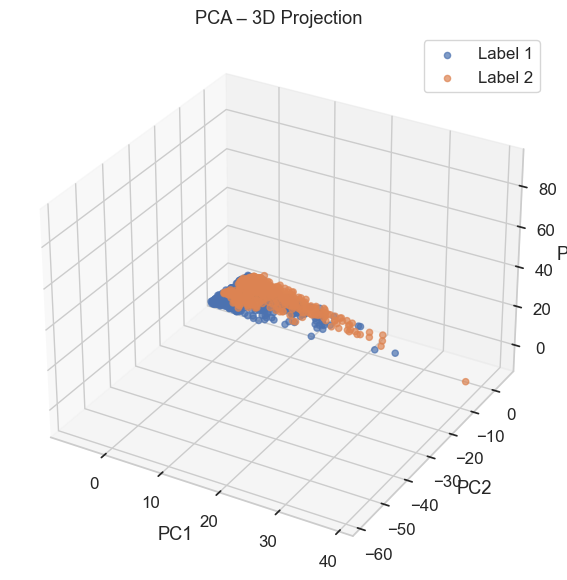

In [65]:
#PCA 2D and 3D visualization

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# 2D PCA scatter (first two PCs)
pca_df_2d = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    label_col: y,
    subject_col: subjects
})

plt.figure()
sns.scatterplot(
    data=pca_df_2d,
    x="PC1", y="PC2",
    hue=label_col,
    palette="Set2",
    alpha=0.7
)
plt.title("PCA – 2D Projection (PC1 vs PC2)")
plt.tight_layout()
plt.show()

# 3D PCA scatter (first three PCs)
if X_pca.shape[1] >= 3:
    pca_df_3d = pd.DataFrame({
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "PC3": X_pca[:, 2],
        label_col: y,
        subject_col: subjects
    })

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    # Map labels to colors
    unique_labels = sorted(pca_df_3d[label_col].unique())
    colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))
    color_map = dict(zip(unique_labels, colors))

    for lbl in unique_labels:
        mask = (pca_df_3d[label_col] == lbl)
        ax.scatter(
            pca_df_3d.loc[mask, "PC1"],
            pca_df_3d.loc[mask, "PC2"],
            pca_df_3d.loc[mask, "PC3"],
            label=f"Label {lbl}",
            alpha=0.7
        )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title("PCA – 3D Projection")
    ax.legend()
    plt.tight_layout()
    plt.show()


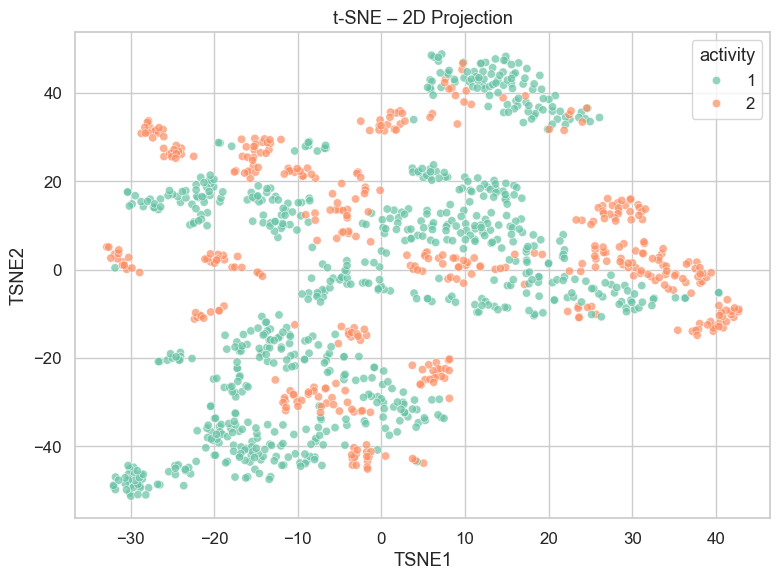

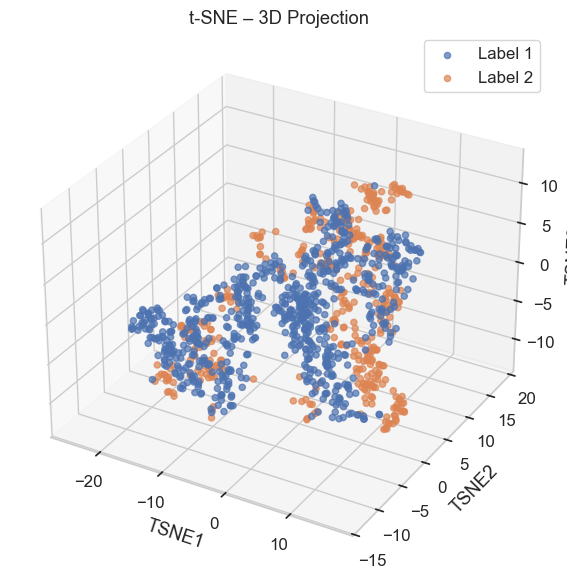

In [66]:
# t-SNE 2D and 3D

# For stability, run t-SNE on a PCA-reduced representation
X_pca_for_tsne = PCA(n_components=min(30, n_features)).fit_transform(X_scaled_all)

# 2D t-SNE
tsne_2d = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate=200,
    max_iter=1000,
    random_state=42
)
X_tsne_2d = tsne_2d.fit_transform(X_pca_for_tsne)

tsne_df_2d = pd.DataFrame({
    "TSNE1": X_tsne_2d[:, 0],
    "TSNE2": X_tsne_2d[:, 1],
    label_col: y,
    subject_col: subjects
})

plt.figure()
sns.scatterplot(
    data=tsne_df_2d,
    x="TSNE1",
    y="TSNE2",
    hue=label_col,
    palette="Set2",
    alpha=0.7
)
plt.title("t-SNE – 2D Projection")
plt.tight_layout()
plt.show()

# 3D t-SNE
tsne_3d = TSNE(
    n_components=3,
    perplexity=30,
    learning_rate=200,
    max_iter=1000,
    random_state=42
)
X_tsne_3d = tsne_3d.fit_transform(X_pca_for_tsne)

tsne_df_3d = pd.DataFrame({
    "TSNE1": X_tsne_3d[:, 0],
    "TSNE2": X_tsne_3d[:, 1],
    "TSNE3": X_tsne_3d[:, 2],
    label_col: y,
    subject_col: subjects
})

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

unique_labels = sorted(tsne_df_3d[label_col].unique())
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))
color_map = dict(zip(unique_labels, colors))

for lbl in unique_labels:
    mask = (tsne_df_3d[label_col] == lbl)
    ax.scatter(
        tsne_df_3d.loc[mask, "TSNE1"],
        tsne_df_3d.loc[mask, "TSNE2"],
        tsne_df_3d.loc[mask, "TSNE3"],
        label=f"Label {lbl}",
        alpha=0.7
    )

ax.set_xlabel("TSNE1")
ax.set_ylabel("TSNE2")
ax.set_zlabel("TSNE3")
ax.set_title("t-SNE – 3D Projection")
ax.legend()
plt.tight_layout()
plt.show()


In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA, KernelPCA
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1.1)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300

print("✓ Libraries imported successfully!")

✓ Libraries imported successfully!


In [68]:
# Standardize features for PCA (important for kernel methods)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Get unique classes for coloring
classes = sorted(y.unique())
n_classes = len(classes)

# Define color palettes
palette_set2 = sns.color_palette("Set2", n_classes)
palette_tab10 = plt.cm.tab10(np.linspace(0, 1, n_classes))
colors_dict = dict(zip(classes, palette_set2))

print(f"Data shape: {X_scaled.shape}")
print(f"Number of classes: {n_classes}")
print(f"Classes: {classes}")

Data shape: (1186, 102)
Number of classes: 2
Classes: [np.int64(1), np.int64(2)]


In [69]:
# Perform standard PCA
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

# Print explained variance
print("Standard Linear PCA:")
print(f"  • Explained variance ratio (PC1): {pca.explained_variance_ratio_[0]:.4f}")
print(f"  • Explained variance ratio (PC2): {pca.explained_variance_ratio_[1]:.4f}")
print(f"  • Explained variance ratio (PC3): {pca.explained_variance_ratio_[2]:.4f}")
print(f"  • Total variance explained (3 PCs): {pca.explained_variance_ratio_[:3].sum():.4f}")

Standard Linear PCA:
  • Explained variance ratio (PC1): 0.2891
  • Explained variance ratio (PC2): 0.1191
  • Explained variance ratio (PC3): 0.1110
  • Total variance explained (3 PCs): 0.5193


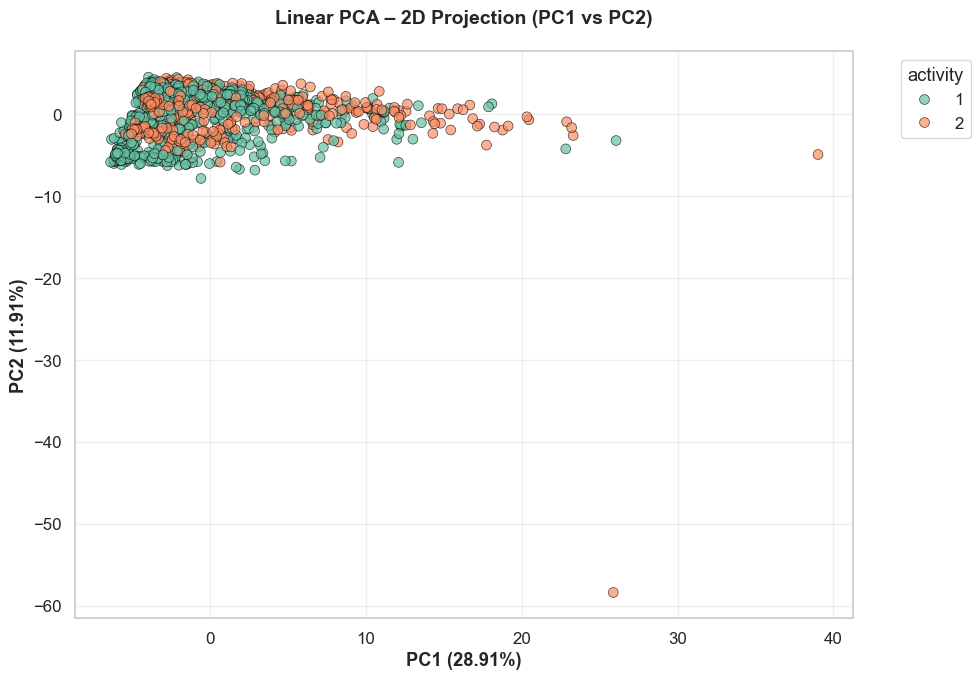

In [70]:
# Create 2D DataFrame
pca_df_2d = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    label_col: y,
    subject_col: subjects
})

# Plot 2D PCA
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df_2d,
    x="PC1", 
    y="PC2",
    hue=label_col,
    palette="Set2",
    alpha=0.7,
    s=50,
    edgecolor='black',
    linewidth=0.5
)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)", fontweight='bold')
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)", fontweight='bold')
plt.title("Linear PCA – 2D Projection (PC1 vs PC2)", fontsize=14, fontweight='bold', pad=20)
plt.legend(title=label_col, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

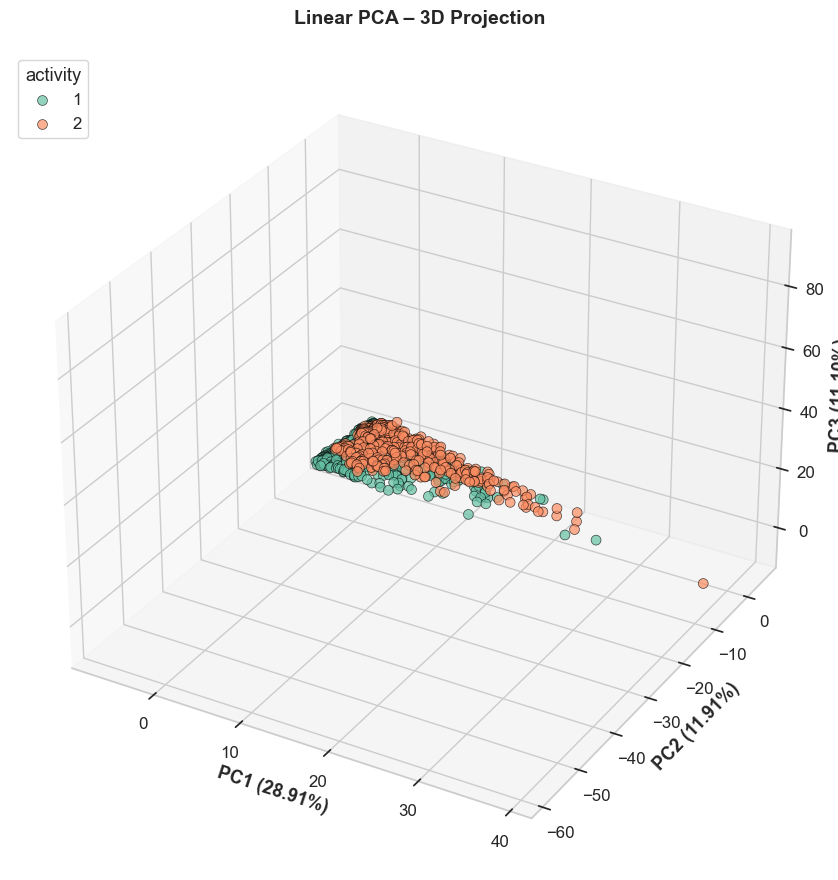

In [71]:
if X_pca.shape[1] >= 3:
    # Create 3D DataFrame
    pca_df_3d = pd.DataFrame({
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "PC3": X_pca[:, 2],
        label_col: y,
        subject_col: subjects
    })
    
    # Create 3D plot
    fig = plt.figure(figsize=(12, 9))
    ax = fig.add_subplot(111, projection="3d")
    
    # Map labels to colors using Set2 palette
    unique_labels = sorted(pca_df_3d[label_col].unique())
    colors = sns.color_palette("Set2", len(unique_labels))
    
    for idx, lbl in enumerate(unique_labels):
        mask = (pca_df_3d[label_col] == lbl)
        ax.scatter(
            pca_df_3d.loc[mask, "PC1"],
            pca_df_3d.loc[mask, "PC2"],
            pca_df_3d.loc[mask, "PC3"],
            label=f"{lbl}",
            alpha=0.7,
            s=50,
            c=[colors[idx]],
            edgecolors='black',
            linewidth=0.5
        )
    
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)", fontweight='bold')
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)", fontweight='bold')
    ax.set_zlabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.2f}%)", fontweight='bold')
    ax.set_title("Linear PCA – 3D Projection", fontsize=14, fontweight='bold', pad=20)
    ax.legend(title=label_col, loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("Not enough components for 3D visualization")

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import KernelPCA
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1.1)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300

print("✓ Libraries imported successfully!")

✓ Libraries imported successfully!


In [73]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Get unique labels and setup colors
labels = sorted(y.unique())
n_labels = len(labels)

# Define colors using Set2 palette
colors = sns.color_palette("Set2", n_labels)
colors_dict = dict(zip(labels, colors))

print(f"Data shape: {X_scaled.shape}")
print(f"Number of labels: {n_labels}")
print(f"Labels: {labels}")

Data shape: (1186, 102)
Number of labels: 2
Labels: [np.int64(1), np.int64(2)]


In [74]:
def evaluate_transform(X_transformed):
    """
    Evaluate the quality of the transformation using total variance.
    Higher variance indicates better spread/separation of data.
    """
    return np.var(X_transformed)

print("✓ Evaluation function defined")

✓ Evaluation function defined


In [75]:
# Define gamma values to test
rbf_gammas = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]

print("Testing RBF (Gaussian) Kernel - 2D")
print("="*60)

best_rbf_2d_score = -1
best_rbf_2d_gamma = None
best_rbf_2d_transform = None

for gamma in rbf_gammas:
    kpca = KernelPCA(n_components=2, kernel='rbf', gamma=gamma, random_state=42)
    X_kpca = kpca.fit_transform(X_scaled)
    
    score = evaluate_transform(X_kpca)
    
    if score > best_rbf_2d_score:
        best_rbf_2d_score = score
        best_rbf_2d_gamma = gamma
        best_rbf_2d_transform = X_kpca
    
    print(f"  gamma={gamma:6.3f}: variance={score:.4f}")

print(f"\n✓ Best RBF 2D: gamma={best_rbf_2d_gamma}")
print(f"  Total Variance: {best_rbf_2d_score:.4f}")

Testing RBF (Gaussian) Kernel - 2D
  gamma= 0.001: variance=0.0286
  gamma= 0.005: variance=0.0673
  gamma= 0.010: variance=0.0680
  gamma= 0.050: variance=0.0146
  gamma= 0.100: variance=0.0053
  gamma= 0.500: variance=0.0012
  gamma= 1.000: variance=0.0009
  gamma= 5.000: variance=0.0008
  gamma=10.000: variance=0.0008

✓ Best RBF 2D: gamma=0.01
  Total Variance: 0.0680


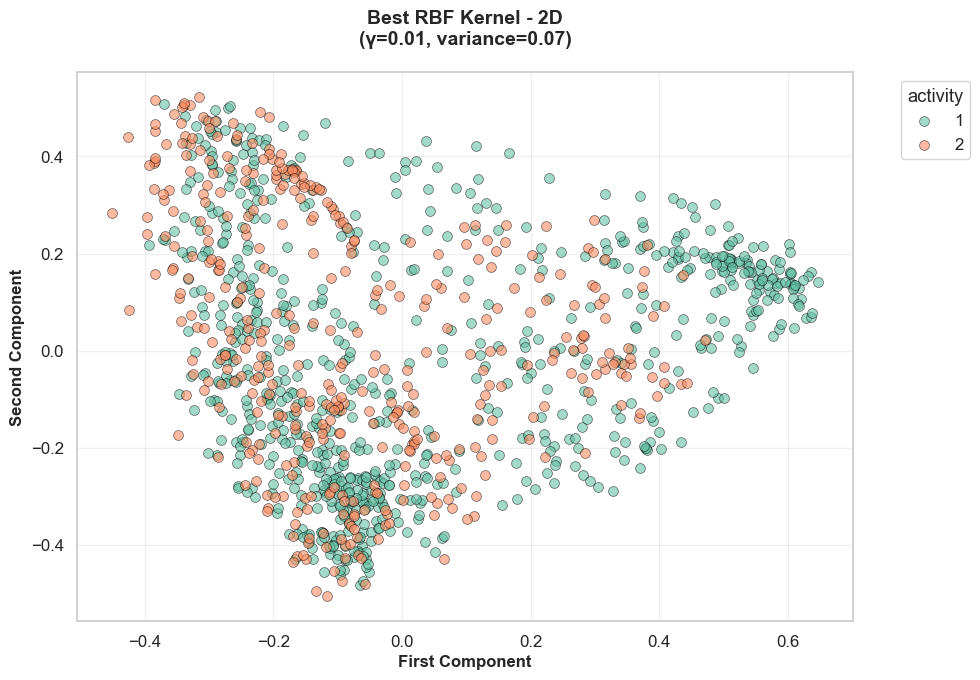

In [76]:
plt.figure(figsize=(10, 7))

for label, color in zip(labels, colors):
    mask = y == label
    plt.scatter(best_rbf_2d_transform[mask, 0], 
                best_rbf_2d_transform[mask, 1], 
                c=[color], label=label, alpha=0.6, s=50,
                edgecolors='black', linewidth=0.5)

plt.xlabel('First Component', fontsize=12, fontweight='bold')
plt.ylabel('Second Component', fontsize=12, fontweight='bold')
plt.title(f"Best RBF Kernel - 2D\n(γ={best_rbf_2d_gamma}, variance={best_rbf_2d_score:.2f})", 
          fontsize=14, fontweight='bold', pad=20)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title=label_col)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [77]:
print("\nTesting RBF (Gaussian) Kernel - 3D")
print("="*60)

best_rbf_3d_score = -1
best_rbf_3d_gamma = None
best_rbf_3d_transform = None

for gamma in rbf_gammas:
    kpca = KernelPCA(n_components=3, kernel='rbf', gamma=gamma, random_state=42)
    X_kpca = kpca.fit_transform(X_scaled)
    
    score = evaluate_transform(X_kpca)
    
    if score > best_rbf_3d_score:
        best_rbf_3d_score = score
        best_rbf_3d_gamma = gamma
        best_rbf_3d_transform = X_kpca
    
    print(f"  gamma={gamma:6.3f}: variance={score:.4f}")

print(f"\n✓ Best RBF 3D: gamma={best_rbf_3d_gamma}")
print(f"  Total Variance: {best_rbf_3d_score:.4f}")


Testing RBF (Gaussian) Kernel - 3D
  gamma= 0.001: variance=0.0224
  gamma= 0.005: variance=0.0542
  gamma= 0.010: variance=0.0560
  gamma= 0.050: variance=0.0132
  gamma= 0.100: variance=0.0047
  gamma= 0.500: variance=0.0011
  gamma= 1.000: variance=0.0009
  gamma= 5.000: variance=0.0008
  gamma=10.000: variance=0.0008

✓ Best RBF 3D: gamma=0.01
  Total Variance: 0.0560


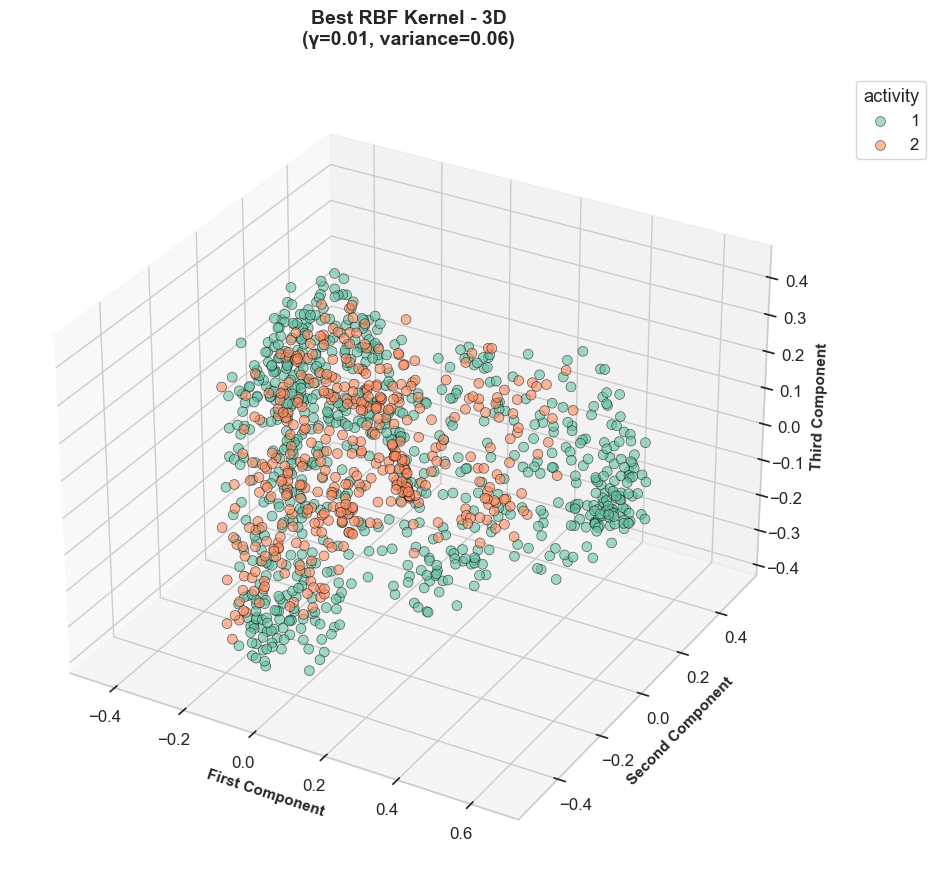

In [78]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

for label, color in zip(labels, colors):
    mask = y == label
    ax.scatter(best_rbf_3d_transform[mask, 0],
               best_rbf_3d_transform[mask, 1],
               best_rbf_3d_transform[mask, 2],
               c=[color], label=label, alpha=0.6, s=50,
               edgecolors='black', linewidth=0.5)

ax.set_xlabel('First Component', fontsize=11, fontweight='bold')
ax.set_ylabel('Second Component', fontsize=11, fontweight='bold')
ax.set_zlabel('Third Component', fontsize=11, fontweight='bold')
ax.set_title(f"Best RBF Kernel - 3D\n(γ={best_rbf_3d_gamma}, variance={best_rbf_3d_score:.2f})", 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title=label_col)
plt.tight_layout()
plt.show()

In [79]:
# Define parameter combinations to test
sigmoid_params = [
    {'gamma': 0.001, 'coef0': 0},
    {'gamma': 0.001, 'coef0': 1},
    {'gamma': 0.01, 'coef0': 0},
    {'gamma': 0.01, 'coef0': 1},
    {'gamma': 0.1, 'coef0': 0},
    {'gamma': 0.1, 'coef0': 1},
    {'gamma': 1.0, 'coef0': 0},
    {'gamma': 1.0, 'coef0': 1},
    {'gamma': 5.0, 'coef0': 0},
    {'gamma': 5.0, 'coef0': 1},
]

print("\nTesting Hyperbolic Tangent (Sigmoid) Kernel - 2D")
print("="*60)

best_sigmoid_2d_score = -1
best_sigmoid_2d_params = None
best_sigmoid_2d_transform = None

for params in sigmoid_params:
    kpca = KernelPCA(n_components=2, kernel='sigmoid', 
                     gamma=params['gamma'], coef0=params['coef0'], random_state=42)
    X_kpca = kpca.fit_transform(X_scaled)
    
    score = evaluate_transform(X_kpca)
    
    if score > best_sigmoid_2d_score:
        best_sigmoid_2d_score = score
        best_sigmoid_2d_params = params
        best_sigmoid_2d_transform = X_kpca
    
    print(f"  gamma={params['gamma']:5.3f}, coef0={params['coef0']}: variance={score:.4f}")

print(f"\n✓ Best Sigmoid 2D: gamma={best_sigmoid_2d_params['gamma']}, coef0={best_sigmoid_2d_params['coef0']}")
print(f"  Total Variance: {best_sigmoid_2d_score:.4f}")


Testing Hyperbolic Tangent (Sigmoid) Kernel - 2D
  gamma=0.001, coef0=0: variance=0.0190
  gamma=0.001, coef0=1: variance=0.0077
  gamma=0.010, coef0=0: variance=0.1529
  gamma=0.010, coef0=1: variance=0.0717
  gamma=0.100, coef0=0: variance=0.4615
  gamma=0.100, coef0=1: variance=0.4161
  gamma=1.000, coef0=0: variance=0.5087
  gamma=1.000, coef0=1: variance=0.5080
  gamma=5.000, coef0=0: variance=0.5093
  gamma=5.000, coef0=1: variance=0.5093

✓ Best Sigmoid 2D: gamma=5.0, coef0=1
  Total Variance: 0.5093


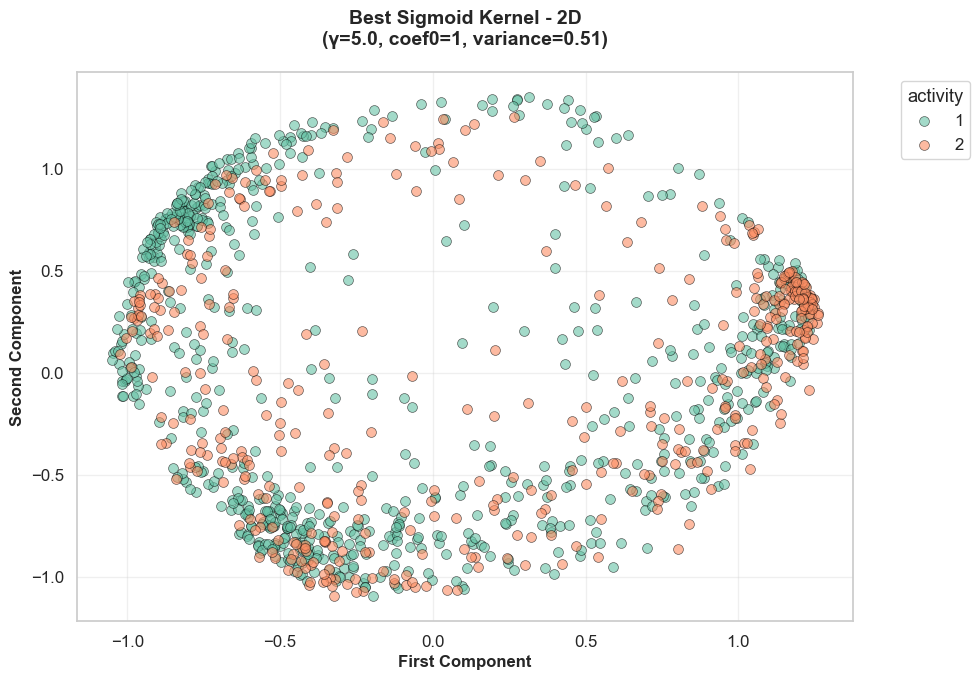

In [80]:
plt.figure(figsize=(10, 7))

for label, color in zip(labels, colors):
    mask = y == label
    plt.scatter(best_sigmoid_2d_transform[mask, 0], 
                best_sigmoid_2d_transform[mask, 1], 
                c=[color], label=label, alpha=0.6, s=50,
                edgecolors='black', linewidth=0.5)

plt.xlabel('First Component', fontsize=12, fontweight='bold')
plt.ylabel('Second Component', fontsize=12, fontweight='bold')
plt.title(f"Best Sigmoid Kernel - 2D\n(γ={best_sigmoid_2d_params['gamma']}, coef0={best_sigmoid_2d_params['coef0']}, variance={best_sigmoid_2d_score:.2f})", 
          fontsize=14, fontweight='bold', pad=20)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title=label_col)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [81]:
print("\nTesting Hyperbolic Tangent (Sigmoid) Kernel - 3D")
print("="*60)

best_sigmoid_3d_score = -1
best_sigmoid_3d_params = None
best_sigmoid_3d_transform = None

for params in sigmoid_params:
    kpca = KernelPCA(n_components=3, kernel='sigmoid', 
                     gamma=params['gamma'], coef0=params['coef0'], random_state=42)
    X_kpca = kpca.fit_transform(X_scaled)
    
    score = evaluate_transform(X_kpca)
    
    if score > best_sigmoid_3d_score:
        best_sigmoid_3d_score = score
        best_sigmoid_3d_params = params
        best_sigmoid_3d_transform = X_kpca
    
    print(f"  gamma={params['gamma']:5.3f}, coef0={params['coef0']}: variance={score:.4f}")

print(f"\n✓ Best Sigmoid 3D: gamma={best_sigmoid_3d_params['gamma']}, coef0={best_sigmoid_3d_params['coef0']}")
print(f"  Total Variance: {best_sigmoid_3d_score:.4f}")


Testing Hyperbolic Tangent (Sigmoid) Kernel - 3D
  gamma=0.001, coef0=0: variance=0.0147
  gamma=0.001, coef0=1: variance=0.0060
  gamma=0.010, coef0=0: variance=0.1202
  gamma=0.010, coef0=1: variance=0.0561
  gamma=0.100, coef0=0: variance=0.3757
  gamma=0.100, coef0=1: variance=0.3329
  gamma=1.000, coef0=0: variance=0.4175
  gamma=1.000, coef0=1: variance=0.4161
  gamma=5.000, coef0=0: variance=0.4181
  gamma=5.000, coef0=1: variance=0.4179

✓ Best Sigmoid 3D: gamma=5.0, coef0=0
  Total Variance: 0.4181


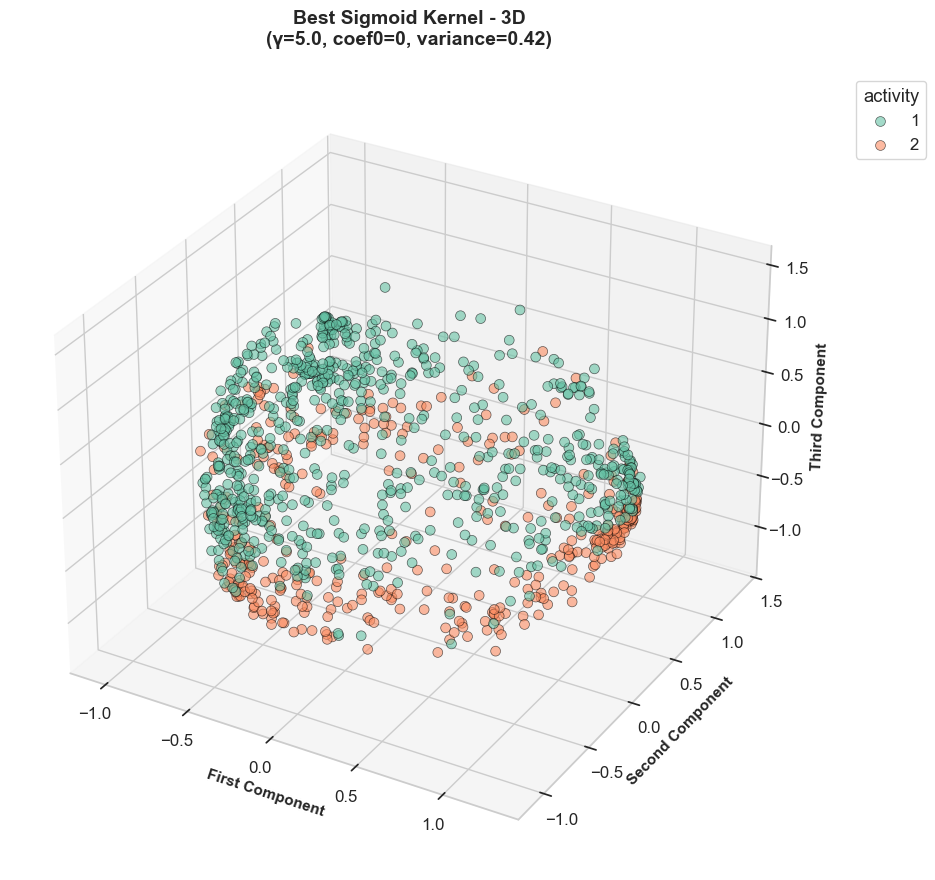

In [82]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

for label, color in zip(labels, colors):
    mask = y == label
    ax.scatter(best_sigmoid_3d_transform[mask, 0],
               best_sigmoid_3d_transform[mask, 1],
               best_sigmoid_3d_transform[mask, 2],
               c=[color], label=label, alpha=0.6, s=50,
               edgecolors='black', linewidth=0.5)

ax.set_xlabel('First Component', fontsize=11, fontweight='bold')
ax.set_ylabel('Second Component', fontsize=11, fontweight='bold')
ax.set_zlabel('Third Component', fontsize=11, fontweight='bold')
ax.set_title(f"Best Sigmoid Kernel - 3D\n(γ={best_sigmoid_3d_params['gamma']}, coef0={best_sigmoid_3d_params['coef0']}, variance={best_sigmoid_3d_score:.2f})", 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title=label_col)
plt.tight_layout()
plt.show()

In [83]:
print("="*80)
print("KERNEL PCA HYPERPARAMETER TUNING SUMMARY")
print("="*80)

print("\n🔵 RBF (Gaussian) Kernel Results:")
print(f"\n  2D Projection:")
print(f"    • Best gamma: {best_rbf_2d_gamma}")
print(f"    • Total variance: {best_rbf_2d_score:.4f}")
print(f"\n  3D Projection:")
print(f"    • Best gamma: {best_rbf_3d_gamma}")
print(f"    • Total variance: {best_rbf_3d_score:.4f}")

print("\n🟡 Sigmoid (Hyperbolic Tangent) Kernel Results:")
print(f"\n  2D Projection:")
print(f"    • Best gamma: {best_sigmoid_2d_params['gamma']}")
print(f"    • Best coef0: {best_sigmoid_2d_params['coef0']}")
print(f"    • Total variance: {best_sigmoid_2d_score:.4f}")
print(f"\n  3D Projection:")
print(f"    • Best gamma: {best_sigmoid_3d_params['gamma']}")
print(f"    • Best coef0: {best_sigmoid_3d_params['coef0']}")
print(f"    • Total variance: {best_sigmoid_3d_score:.4f}")

print("\n💡 Key Insights:")
if best_rbf_2d_score > best_sigmoid_2d_score:
    print(f"    • RBF kernel achieves {(best_rbf_2d_score/best_sigmoid_2d_score - 1)*100:.1f}% higher variance in 2D")
    print("    • RBF is recommended for this dataset")
else:
    print(f"    • Sigmoid kernel achieves {(best_sigmoid_2d_score/best_rbf_2d_score - 1)*100:.1f}% higher variance in 2D")
    print("    • Sigmoid is recommended for this dataset")

print("\n" + "="*80)
print("✅ Hyperparameter tuning completed!")
print("="*80)

KERNEL PCA HYPERPARAMETER TUNING SUMMARY

🔵 RBF (Gaussian) Kernel Results:

  2D Projection:
    • Best gamma: 0.01
    • Total variance: 0.0680

  3D Projection:
    • Best gamma: 0.01
    • Total variance: 0.0560

🟡 Sigmoid (Hyperbolic Tangent) Kernel Results:

  2D Projection:
    • Best gamma: 5.0
    • Best coef0: 1
    • Total variance: 0.5093

  3D Projection:
    • Best gamma: 5.0
    • Best coef0: 0
    • Total variance: 0.4181

💡 Key Insights:
    • Sigmoid kernel achieves 649.2% higher variance in 2D
    • Sigmoid is recommended for this dataset

✅ Hyperparameter tuning completed!


In [84]:
# Define parameter combinations to test
sigmoid_params = [
    {'gamma': 0.001, 'coef0': 0},
    {'gamma': 0.001, 'coef0': 1},
    {'gamma': 0.01, 'coef0': 0},
    {'gamma': 0.01, 'coef0': 1},
    {'gamma': 0.1, 'coef0': 0},
    {'gamma': 0.1, 'coef0': 1},
    {'gamma': 1.0, 'coef0': 0},
    {'gamma': 1.0, 'coef0': 1},
    {'gamma': 5.0, 'coef0': 0},
    {'gamma': 5.0, 'coef0': 1},
]

print("\nTesting Hyperbolic Tangent (Sigmoid) Kernel - 2D")
print("="*60)

best_sigmoid_2d_score = -1
best_sigmoid_2d_params = None
best_sigmoid_2d_transform = None

for params in sigmoid_params:
    kpca = KernelPCA(n_components=2, kernel='sigmoid', 
                     gamma=params['gamma'], coef0=params['coef0'], random_state=42)
    X_kpca = kpca.fit_transform(X_scaled)
    
    score = evaluate_transform(X_kpca)
    
    if score > best_sigmoid_2d_score:
        best_sigmoid_2d_score = score
        best_sigmoid_2d_params = params
        best_sigmoid_2d_transform = X_kpca
    
    print(f"  gamma={params['gamma']:5.3f}, coef0={params['coef0']}: variance={score:.4f}")

print(f"\n✓ Best Sigmoid 2D: gamma={best_sigmoid_2d_params['gamma']}, coef0={best_sigmoid_2d_params['coef0']}")
print(f"  Total Variance: {best_sigmoid_2d_score:.4f}")


Testing Hyperbolic Tangent (Sigmoid) Kernel - 2D
  gamma=0.001, coef0=0: variance=0.0190
  gamma=0.001, coef0=1: variance=0.0077
  gamma=0.010, coef0=0: variance=0.1529
  gamma=0.010, coef0=1: variance=0.0717
  gamma=0.100, coef0=0: variance=0.4615
  gamma=0.100, coef0=1: variance=0.4161
  gamma=1.000, coef0=0: variance=0.5087
  gamma=1.000, coef0=1: variance=0.5080
  gamma=5.000, coef0=0: variance=0.5093
  gamma=5.000, coef0=1: variance=0.5093

✓ Best Sigmoid 2D: gamma=5.0, coef0=1
  Total Variance: 0.5093


In [85]:
plt.figure(figsize=(10, 7))

for activity, color in zip(activities, colors):
    mask = y == activity
    plt.scatter(best_sigmoid_2d_transform[mask, 0], 
                best_sigmoid_2d_transform[mask, 1], 
                c=[color], label=activity, alpha=0.6, s=50,
                edgecolors='black', linewidth=0.5)

plt.xlabel('First Component', fontsize=12, fontweight='bold')
plt.ylabel('Second Component', fontsize=12, fontweight='bold')
plt.title(f"Best Sigmoid Kernel - 2D\n(γ={best_sigmoid_2d_params['gamma']}, coef0={best_sigmoid_2d_params['coef0']}, variance={best_sigmoid_2d_score:.2f})", 
          fontsize=14, fontweight='bold', pad=20)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title=label_col)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'activities' is not defined

<Figure size 1000x700 with 0 Axes>

In [ ]:
print("\nTesting Hyperbolic Tangent (Sigmoid) Kernel - 3D")
print("="*60)

best_sigmoid_3d_score = -1
best_sigmoid_3d_params = None
best_sigmoid_3d_transform = None

for params in sigmoid_params:
    kpca = KernelPCA(n_components=3, kernel='sigmoid', 
                     gamma=params['gamma'], coef0=params['coef0'], random_state=42)
    X_kpca = kpca.fit_transform(X_scaled)
    
    score = evaluate_transform(X_kpca)
    
    if score > best_sigmoid_3d_score:
        best_sigmoid_3d_score = score
        best_sigmoid_3d_params = params
        best_sigmoid_3d_transform = X_kpca
    
    print(f"  gamma={params['gamma']:5.3f}, coef0={params['coef0']}: variance={score:.4f}")

print(f"\n✓ Best Sigmoid 3D: gamma={best_sigmoid_3d_params['gamma']}, coef0={best_sigmoid_3d_params['coef0']}")
print(f"  Total Variance: {best_sigmoid_3d_score:.4f}")


Testing Hyperbolic Tangent (Sigmoid) Kernel - 3D
  gamma=0.001, coef0=0: variance=0.0147
  gamma=0.001, coef0=1: variance=0.0060
  gamma=0.010, coef0=0: variance=0.1202
  gamma=0.010, coef0=1: variance=0.0561
  gamma=0.100, coef0=0: variance=0.3757
  gamma=0.100, coef0=1: variance=0.3329
  gamma=1.000, coef0=0: variance=0.4175
  gamma=1.000, coef0=1: variance=0.4161
  gamma=5.000, coef0=0: variance=0.4181
  gamma=5.000, coef0=1: variance=0.4179

✓ Best Sigmoid 3D: gamma=5.0, coef0=0
  Total Variance: 0.4181


NameError: name 'activities' is not defined

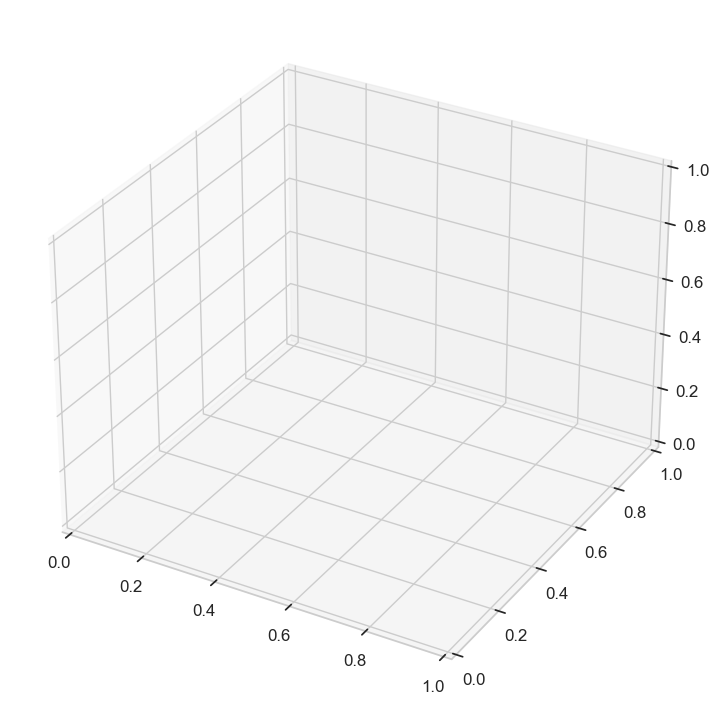

In [ ]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

for activity, color in zip(activities, colors):
    mask = y == activity
    ax.scatter(best_sigmoid_3d_transform[mask, 0],
               best_sigmoid_3d_transform[mask, 1],
               best_sigmoid_3d_transform[mask, 2],
               c=[color], label=activity, alpha=0.6, s=50,
               edgecolors='black', linewidth=0.5)

ax.set_xlabel('First Component', fontsize=11, fontweight='bold')
ax.set_ylabel('Second Component', fontsize=11, fontweight='bold')
ax.set_zlabel('Third Component', fontsize=11, fontweight='bold')
ax.set_title(f"Best Sigmoid Kernel - 3D\n(γ={best_sigmoid_3d_params['gamma']}, coef0={best_sigmoid_3d_params['coef0']}, variance={best_sigmoid_3d_score:.2f})", 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title=label_col)
plt.tight_layout()
plt.show()

NameError: name 'activities' is not defined

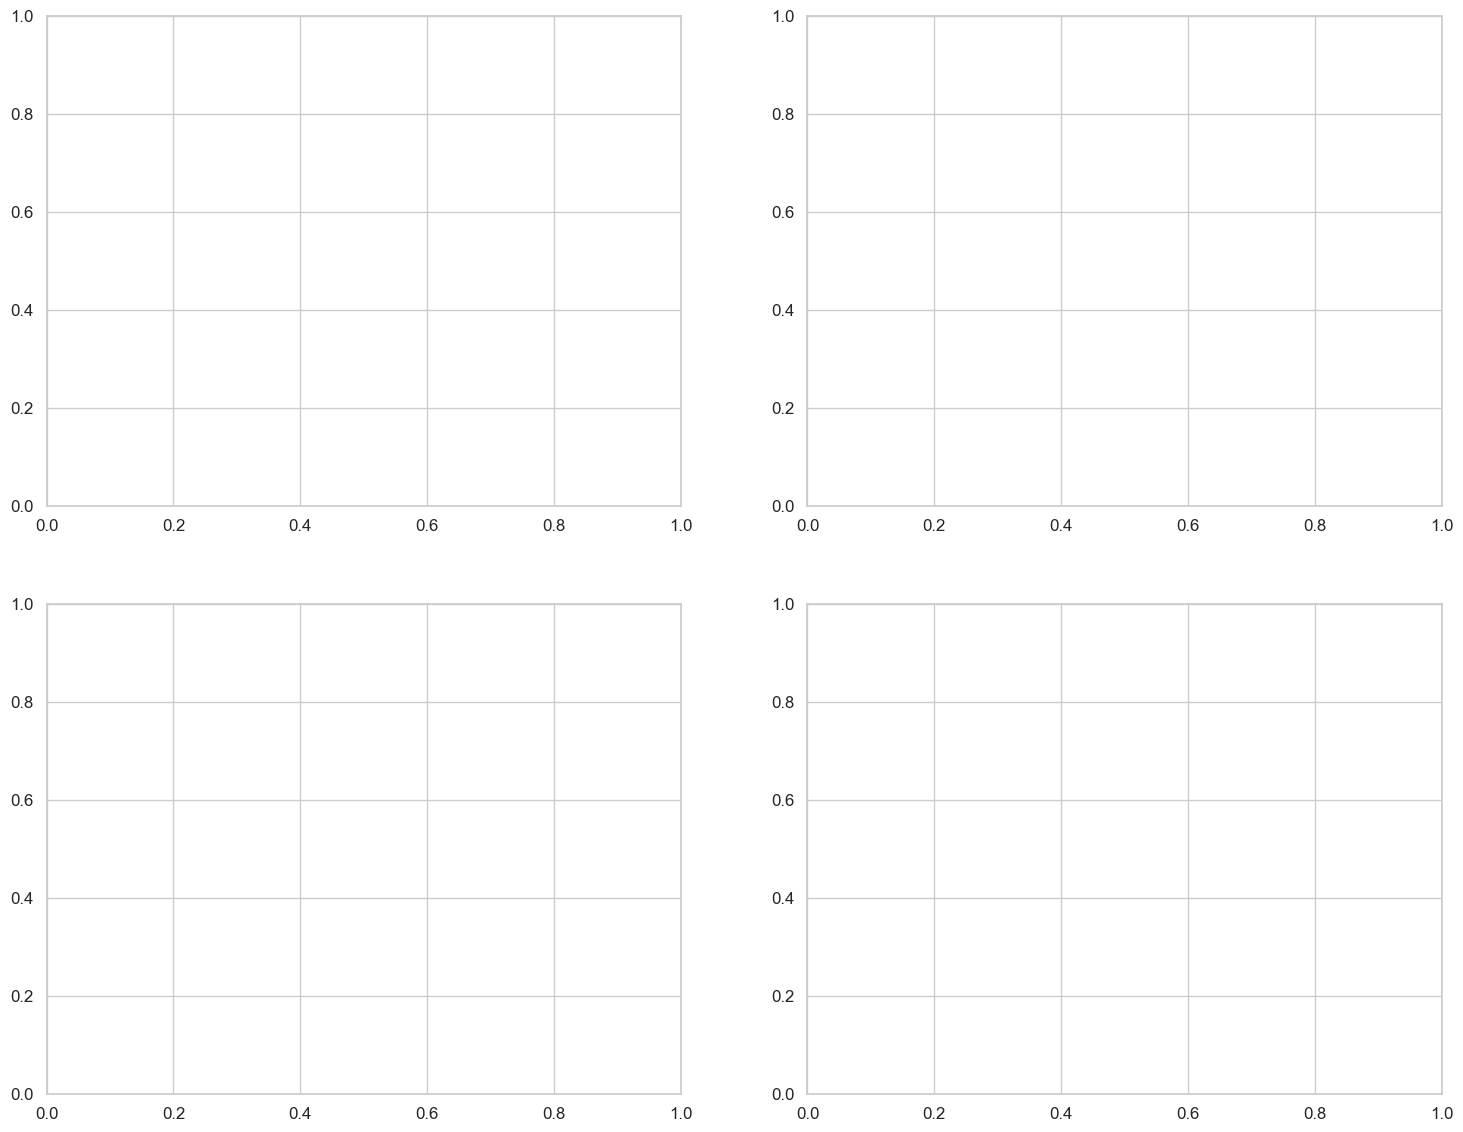

In [ ]:
# Create comparison visualization
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# RBF 2D
for activity, color in zip(activities, colors):
    mask = y == activity
    axes[0, 0].scatter(best_rbf_2d_transform[mask, 0], 
                       best_rbf_2d_transform[mask, 1], 
                       c=[color], label=activity, alpha=0.6, s=40,
                       edgecolors='black', linewidth=0.5)
axes[0, 0].set_xlabel('First Component', fontweight='bold')
axes[0, 0].set_ylabel('Second Component', fontweight='bold')
axes[0, 0].set_title(f"RBF Kernel - 2D\n(γ={best_rbf_2d_gamma}, var={best_rbf_2d_score:.2f})", 
                     fontsize=13, fontweight='bold', pad=15)
axes[0, 0].legend(title=label_col, loc='best', fontsize=9)
axes[0, 0].grid(True, alpha=0.3)

# Sigmoid 2D
for activity, color in zip(activities, colors):
    mask = y == activity
    axes[0, 1].scatter(best_sigmoid_2d_transform[mask, 0], 
                       best_sigmoid_2d_transform[mask, 1], 
                       c=[color], label=activity, alpha=0.6, s=40,
                       edgecolors='black', linewidth=0.5)
axes[0, 1].set_xlabel('First Component', fontweight='bold')
axes[0, 1].set_ylabel('Second Component', fontweight='bold')
axes[0, 1].set_title(f"Sigmoid Kernel - 2D\n(γ={best_sigmoid_2d_params['gamma']}, coef0={best_sigmoid_2d_params['coef0']}, var={best_sigmoid_2d_score:.2f})", 
                     fontsize=13, fontweight='bold', pad=15)
axes[0, 1].legend(title=label_col, loc='best', fontsize=9)
axes[0, 1].grid(True, alpha=0.3)

# RBF gamma comparison
rbf_variances = []
for gamma in rbf_gammas:
    kpca = KernelPCA(n_components=2, kernel='rbf', gamma=gamma, random_state=42)
    X_kpca = kpca.fit_transform(X_scaled)
    rbf_variances.append(evaluate_transform(X_kpca))

axes[1, 0].plot(rbf_gammas, rbf_variances, 'o-', linewidth=2, markersize=8, 
                color='#66c2a5', markeredgecolor='black', markeredgewidth=1)
axes[1, 0].axvline(x=best_rbf_2d_gamma, color='red', linestyle='--', linewidth=2, 
                   label=f'Best: γ={best_rbf_2d_gamma}')
axes[1, 0].set_xlabel('Gamma', fontweight='bold')
axes[1, 0].set_ylabel('Total Variance', fontweight='bold')
axes[1, 0].set_title('RBF Kernel: Gamma vs Variance', fontsize=13, fontweight='bold', pad=15)
axes[1, 0].set_xscale('log')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend(fontsize=10)

# Sigmoid parameter comparison
sigmoid_variances = []
sigmoid_labels = []
for params in sigmoid_params:
    kpca = KernelPCA(n_components=2, kernel='sigmoid', 
                     gamma=params['gamma'], coef0=params['coef0'], random_state=42)
    X_kpca = kpca.fit_transform(X_scaled)
    sigmoid_variances.append(evaluate_transform(X_kpca))
    sigmoid_labels.append(f"γ={params['gamma']}\nc0={params['coef0']}")

x_pos = np.arange(len(sigmoid_params))
axes[1, 1].bar(x_pos, sigmoid_variances, color='#fc8d62', alpha=0.8, edgecolor='black')
axes[1, 1].set_xlabel('Parameter Combination', fontweight='bold')
axes[1, 1].set_ylabel('Total Variance', fontweight='bold')
axes[1, 1].set_title('Sigmoid Kernel: Parameter Comparison', fontsize=13, fontweight='bold', pad=15)
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(sigmoid_labels, rotation=45, ha='right', fontsize=8)
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Highlight best
best_idx = sigmoid_variances.index(max(sigmoid_variances))
axes[1, 1].bar(best_idx, sigmoid_variances[best_idx], color='red', alpha=0.8, edgecolor='black')

plt.suptitle('Kernel PCA Hyperparameter Tuning Results', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

## MLP

All subjects: [ 2  3  4  5  6  7  8  9 10 11 13 14 15 16 17]
Global subjects (used for training global model): [11 14  2 16  7 10  4  3 17  6  9]
Personal subjects (used for personalization study): [13 15  5  8]

=== LOSO CV on 11 global subjects (with StandardScaler + PCA) ===

Fold: test subject = 11
  LOSO accuracy on subject 11: 0.8875

Fold: test subject = 14
  LOSO accuracy on subject 14: 0.8750

Fold: test subject = 2
  LOSO accuracy on subject 2: 0.9067

Fold: test subject = 16
  LOSO accuracy on subject 16: 0.7375

Fold: test subject = 7
  LOSO accuracy on subject 7: 0.7564

Fold: test subject = 10
  LOSO accuracy on subject 10: 0.9390

Fold: test subject = 4
  LOSO accuracy on subject 4: 0.9351

Fold: test subject = 3
  LOSO accuracy on subject 3: 0.8158

Fold: test subject = 17
  LOSO accuracy on subject 17: 0.8293

Fold: test subject = 6
  LOSO accuracy on subject 6: 0.9873

Fold: test subject = 9
  LOSO accuracy on subject 9: 0.8608

Mean LOSO accuracy (11 global subjects)

,subject,acc_global,acc_personal,delta
0,13,0.984375,0.984375,0.000000
1,15,0.656250,0.656250,0.000000
2,5,0.984375,0.937500,-0.046875
3,8,0.953125,0.953125,0.000000



Mean global accuracy (personal subjects):       0.89453125
Mean personalized accuracy (personal subjects): 0.8828125
Mean delta (pers - glob):                       -0.01171875

=== Confusion Matrices & Classification Reports (Personal Subjects) ===


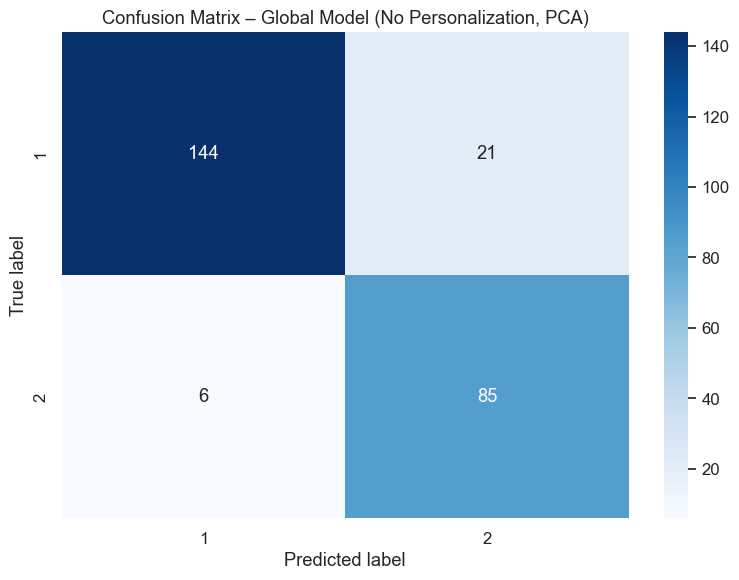

Classification report – Global Model (No Personalization):
              precision    recall  f1-score   support

           1       0.96      0.87      0.91       165
           2       0.80      0.93      0.86        91

    accuracy                           0.89       256
   macro avg       0.88      0.90      0.89       256
weighted avg       0.90      0.89      0.90       256



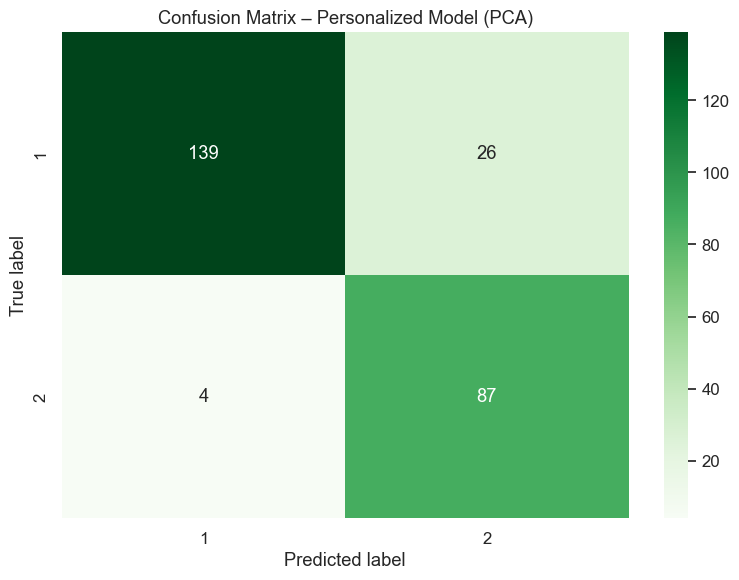

Classification report – Personalized Model:
              precision    recall  f1-score   support

           1       0.97      0.84      0.90       165
           2       0.77      0.96      0.85        91

    accuracy                           0.88       256
   macro avg       0.87      0.90      0.88       256
weighted avg       0.90      0.88      0.88       256



In [ ]:
# === FULL CELL: Global MLP + PCA (27 comps) + Personalization (11 global, remaining personal) ===

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
)
import seaborn as sns
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models as keras_models, callbacks

# -------------------------------------------------------------------
# 0. Prepare data and basic settings
# -------------------------------------------------------------------
X_all_raw = X_raw           # numeric features, NaNs already handled
y_all_bin = y_bin           # {0,1}
subjects_all = subjects

print("All subjects:", np.unique(subjects_all))
print("Global subjects (used for training global model):", global_subjects)
print("Personal subjects (used for personalization study):", personal_subjects)

# From your PCA EDA: 95% variance ~ 27 components
N_PCA_MODEL = min(27, X_all_raw.shape[1])

# -------------------------------------------------------------------
# 1. Define MLP architecture (3 hidden layers, GELU + BatchNorm)
#    Note: input_dim will be N_PCA_MODEL (PCA feature dimension)
# -------------------------------------------------------------------
def build_mlp(input_dim, lr=1e-3):
    inputs = layers.Input(shape=(input_dim,))

    x = layers.Dense(256)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation(tf.nn.gelu)(x)

    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation(tf.nn.gelu)(x)

    x = layers.Dense(64)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation(tf.nn.gelu)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras_models.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

input_dim_model = N_PCA_MODEL  # PCA dimension used for MLP

# -------------------------------------------------------------------
# 2. LOSO CV on the 11 global subjects (with PCA fit on train only)
# -------------------------------------------------------------------
print("\n=== LOSO CV on 11 global subjects (with StandardScaler + PCA) ===")

loso_accuracies = []

for test_sub in global_subjects:
    print(f"\nFold: test subject = {test_sub}")

    # Train = other global subjects; Test = this global subject
    train_mask = np.isin(subjects_all, global_subjects) & (subjects_all != test_sub)
    test_mask  = (subjects_all == test_sub)

    X_train_raw = X_all_raw[train_mask]
    y_train     = y_all_bin[train_mask]

    X_test_raw  = X_all_raw[test_mask]
    y_test      = y_all_bin[test_mask]

    # --- Fit scaler and PCA on TRAIN ONLY ---
    scaler_loso = StandardScaler().fit(X_train_raw)
    X_train_scaled = scaler_loso.transform(X_train_raw)
    X_test_scaled  = scaler_loso.transform(X_test_raw)

    pca_loso = PCA(n_components=input_dim_model).fit(X_train_scaled)
    X_train_pca = pca_loso.transform(X_train_scaled)
    X_test_pca  = pca_loso.transform(X_test_scaled)

    model = build_mlp(input_dim_model, lr=1e-3)

    es = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=0
    )

    model.fit(
        X_train_pca,
        y_train,
        validation_split=0.1,
        epochs=50,
        batch_size=128,
        callbacks=[es],
        verbose=0,
    )

    preds = model.predict(X_test_pca, verbose=0).ravel()
    y_pred = (preds >= 0.5).astype(int)
    acc = accuracy_score(y_test, y_pred)
    loso_accuracies.append(acc)
    print(f"  LOSO accuracy on subject {test_sub}: {acc:.4f}")

print("\nMean LOSO accuracy (11 global subjects):", np.mean(loso_accuracies))

# -------------------------------------------------------------------
# 3. Train final GLOBAL base model on all 11 global subjects
#    (StandardScaler + PCA fit on 11 subjects)
# -------------------------------------------------------------------
print("\n=== Train final GLOBAL base model on 11 subjects (with PCA) ===")

mask_global = np.isin(subjects_all, global_subjects)
X_global_raw = X_all_raw[mask_global]
y_global     = y_all_bin[mask_global]

# One global scaler fit on all global data
scaler_global = StandardScaler().fit(X_global_raw)
X_global_scaled = scaler_global.transform(X_global_raw)

# One global PCA fit on scaled global data
pca_global = PCA(n_components=input_dim_model).fit(X_global_scaled)
X_global_pca = pca_global.transform(X_global_scaled)

global_base_model = build_mlp(input_dim_model, lr=1e-3)

es_global = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

global_base_model.fit(
    X_global_pca,
    y_global,
    validation_split=0.1,
    epochs=80,
    batch_size=128,
    callbacks=[es_global],
    verbose=1,
)

base_weights = global_base_model.get_weights()  # for cloning during personalization

# -------------------------------------------------------------------
# 4. Evaluation on personal subjects:
#    (a) Global model (no personalization)
#    (b) Personalized model (fine-tuned on 20% of that subject)
#    All in PCA space using global scaler + PCA
# -------------------------------------------------------------------
print("\n=== Evaluation on personal subjects (global vs personalized, with PCA) ===")

results = []
y_true_global_all = []
y_pred_global_all = []

y_true_pers_all = []
y_pred_pers_all = []

for s in personal_subjects:
    print(f"\n----- Subject {s} -----")

    # All data for this subject
    mask_s = (subjects_all == s)
    X_s_raw = X_all_raw[mask_s]
    y_s     = y_all_bin[mask_s]

    # 20% for personalization training, 80% for test
    strat = y_s if len(np.unique(y_s)) > 1 else None
    X_train_raw, X_test_raw, y_train_s, y_test_s = train_test_split(
        X_s_raw,
        y_s,
        test_size=0.80,
        random_state=42,
        shuffle=True,
        stratify=strat,
    )

    print("  Personalization train shape:", X_train_raw.shape,
          "Test shape:", X_test_raw.shape)

    # --- Transform using the GLOBAL scaler + PCA (no refit!) ---
    X_train_scaled = scaler_global.transform(X_train_raw)
    X_test_scaled  = scaler_global.transform(X_test_raw)

    X_train_pca = pca_global.transform(X_train_scaled)
    X_test_pca  = pca_global.transform(X_test_scaled)

    # ---- (a) Global model, no personalization ----
    preds_global = global_base_model.predict(X_test_pca, verbose=0).ravel()
    y_pred_global = (preds_global >= 0.5).astype(int)
    acc_global = accuracy_score(y_test_s, y_pred_global)
    print(f"  Global (no personalization) accuracy: {acc_global:.4f}")

    # ---- (b) Personalized: fine-tune copy of global model on 20% ----
    personal_model = build_mlp(input_dim_model, lr=5e-4)
    personal_model.set_weights(base_weights)

    es_pers = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=0
    )

    val_split = 0.2 if len(np.unique(y_train_s)) > 1 else 0.0

    personal_model.fit(
        X_train_pca,
        y_train_s,
        validation_split=val_split,
        epochs=40,
        batch_size=64,
        callbacks=[es_pers],
        verbose=0,
    )

    preds_pers = personal_model.predict(X_test_pca, verbose=0).ravel()
    y_pred_pers = (preds_pers >= 0.5).astype(int)
    acc_pers = accuracy_score(y_test_s, y_pred_pers)
    print(f"  Personalized accuracy:             {acc_pers:.4f}")

    # Store per-subject
    results.append({
        "subject": s,
        "acc_global": acc_global,
        "acc_personal": acc_pers,
    })

    # Store for overall confusion matrices / reports
    y_true_global_all.extend(y_test_s)
    y_pred_global_all.extend(y_pred_global)

    y_true_pers_all.extend(y_test_s)
    y_pred_pers_all.extend(y_pred_pers)

results_df = pd.DataFrame(results)
results_df["delta"] = results_df["acc_personal"] - results_df["acc_global"]
print("\nPer-subject results (personal subjects):")
display(results_df)
print("\nMean global accuracy (personal subjects):      ", results_df["acc_global"].mean())
print("Mean personalized accuracy (personal subjects):", results_df["acc_personal"].mean())
print("Mean delta (pers - glob):                      ", results_df["delta"].mean())

# -------------------------------------------------------------------
# 5. Confusion matrices & classification reports (for the personal subjects)
# -------------------------------------------------------------------
print("\n=== Confusion Matrices & Classification Reports (Personal Subjects) ===")

y_true_global_all = np.array(y_true_global_all)
y_pred_global_all = np.array(y_pred_global_all)

y_true_pers_all = np.array(y_true_pers_all)
y_pred_pers_all = np.array(y_pred_pers_all)

# Map back to original labels {1,2}
inv_label_mapping = {v: k for k, v in label_mapping.items()}

def remap_back(y_bin_arr):
    return np.vectorize(inv_label_mapping.get)(y_bin_arr)

y_true_global_orig = remap_back(y_true_global_all)
y_pred_global_orig = remap_back(y_pred_global_all)

y_true_pers_orig = remap_back(y_true_pers_all)
y_pred_pers_orig = remap_back(y_pred_pers_all)

labels_orig = [1, 2]

# Global confusion matrix
cm_global = confusion_matrix(y_true_global_orig, y_pred_global_orig, labels=labels_orig)
plt.figure()
sns.heatmap(
    cm_global,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels_orig,
    yticklabels=labels_orig
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix – Global Model (No Personalization, PCA)")
plt.tight_layout()
plt.show()

print("Classification report – Global Model (No Personalization):")
print(classification_report(y_true_global_orig, y_pred_global_orig, labels=labels_orig))

# Personalized confusion matrix
cm_pers = confusion_matrix(y_true_pers_orig, y_pred_pers_orig, labels=labels_orig)
plt.figure()
sns.heatmap(
    cm_pers,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels_orig,
    yticklabels=labels_orig
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix – Personalized Model (PCA)")
plt.tight_layout()
plt.show()

print("Classification report – Personalized Model:")
print(classification_report(y_true_pers_orig, y_pred_pers_orig, labels=labels_orig))


Global subjects: [11 14  2 16  7 10  4  3 17  6  9]
Personal subjects: [13 15  5  8]
Global PCA shape: (868, 27)
Global training data (PCA) shape: (868, 27)

================ Subject 13 ================
  Personalization train shape: (15, 102) Test shape: (64, 102)
    -> Classifier: KNN_5
       Global acc:       0.8594
       Personalized acc: 0.8906
    -> Classifier: DecisionTree
       Global acc:       0.7188
       Personalized acc: 0.7344
    -> Classifier: SVM_linear
       Global acc:       0.9844
       Personalized acc: 0.9844
    -> Classifier: SVM_rbf
       Global acc:       0.9219
       Personalized acc: 0.9062
    -> Classifier: SVM_poly
       Global acc:       0.9375
       Personalized acc: 0.9375
    -> Classifier: XGBoost
       Global acc:       0.9375
       Personalized acc: 0.9531
    -> Classifier: RandomForest
       Global acc:       0.9531
       Personalized acc: 0.9688

================ Subject 15 ================
  Personalization train shape: (16, 102

,subject,acc_global,acc_personal,delta
0,13,0.859375,0.890625,0.031250
1,15,0.578125,0.718750,0.140625
2,5,0.781250,0.921875,0.140625
3,8,0.984375,0.968750,-0.015625


Mean global acc:       0.80078125
Mean personalized acc: 0.875
Mean delta (pers-glob): 0.07421875

================ Results for DecisionTree ================


,subject,acc_global,acc_personal,delta
0,13,0.718750,0.734375,0.015625
1,15,0.671875,0.656250,-0.015625
2,5,0.843750,0.906250,0.062500
3,8,0.734375,0.687500,-0.046875


Mean global acc:       0.7421875
Mean personalized acc: 0.74609375
Mean delta (pers-glob): 0.00390625

================ Results for SVM_linear ================


,subject,acc_global,acc_personal,delta
0,13,0.984375,0.984375,0.000000
1,15,0.609375,0.656250,0.046875
2,5,0.921875,0.921875,0.000000
3,8,0.890625,0.968750,0.078125


... (5 outputs left out)

,subject,acc_global,acc_personal,delta
0,13,0.937500,0.953125,0.015625
1,15,0.656250,0.812500,0.156250
2,5,0.921875,0.953125,0.031250
3,8,0.968750,0.984375,0.015625


Mean global acc:       0.87109375
Mean personalized acc: 0.92578125
Mean delta (pers-glob): 0.0546875

================ Results for RandomForest ================


,subject,acc_global,acc_personal,delta
0,13,0.953125,0.96875,0.015625
1,15,0.640625,0.75000,0.109375
2,5,0.937500,0.93750,0.000000
3,8,0.968750,0.96875,0.000000


Mean global acc:       0.875
Mean personalized acc: 0.90625
Mean delta (pers-glob): 0.03125


====== Confusion Matrices & Reports for KNN_5 ======


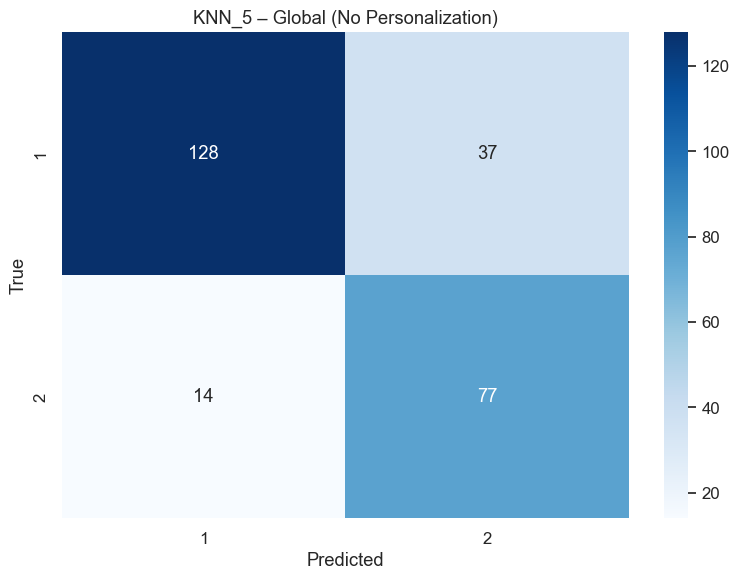

Classification report – KNN_5 Global:
              precision    recall  f1-score   support

           1       0.90      0.78      0.83       165
           2       0.68      0.85      0.75        91

    accuracy                           0.80       256
   macro avg       0.79      0.81      0.79       256
weighted avg       0.82      0.80      0.80       256



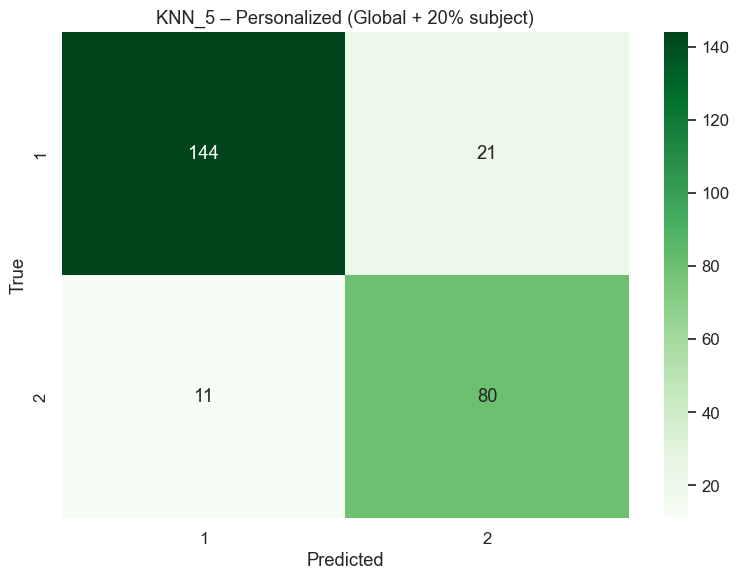

Classification report – KNN_5 Personalized:
              precision    recall  f1-score   support

           1       0.93      0.87      0.90       165
           2       0.79      0.88      0.83        91

    accuracy                           0.88       256
   macro avg       0.86      0.88      0.87       256
weighted avg       0.88      0.88      0.88       256



====== Confusion Matrices & Reports for DecisionTree ======


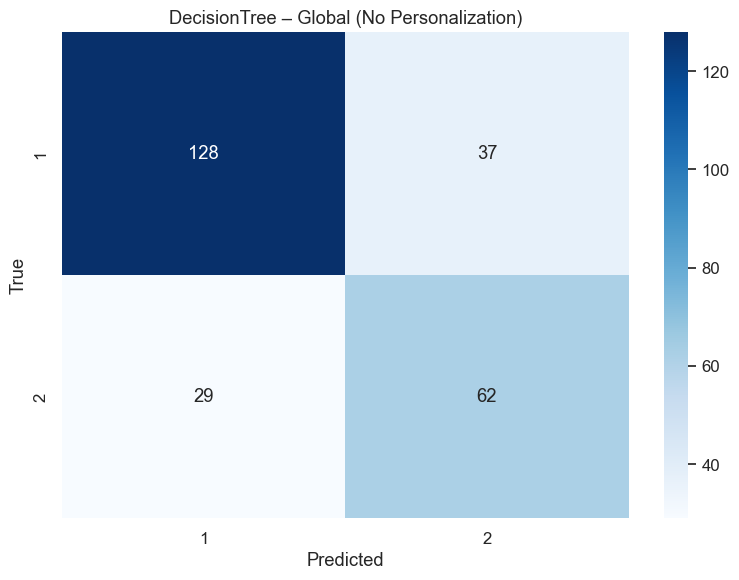

Classification report – DecisionTree Global:
              precision    recall  f1-score   support

           1       0.82      0.78      0.80       165
           2       0.63      0.68      0.65        91

    accuracy                           0.74       256
   macro avg       0.72      0.73      0.72       256
weighted avg       0.75      0.74      0.74       256



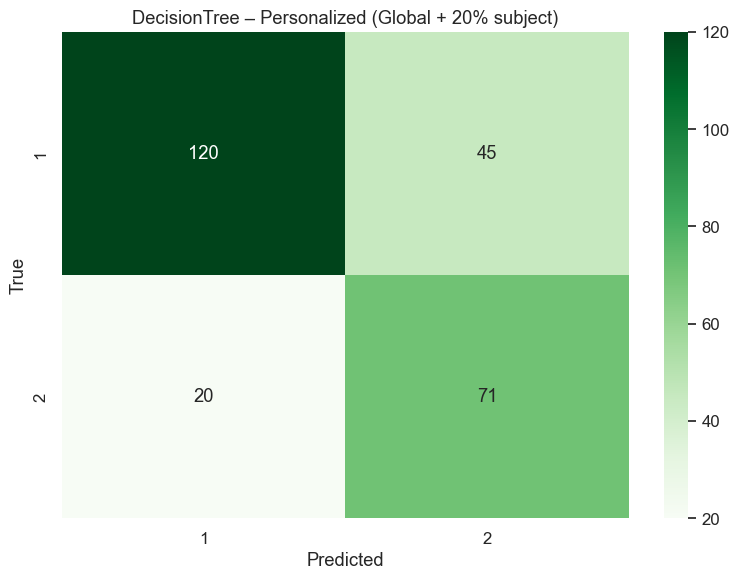

Classification report – DecisionTree Personalized:
              precision    recall  f1-score   support

           1       0.86      0.73      0.79       165
           2       0.61      0.78      0.69        91

    accuracy                           0.75       256
   macro avg       0.73      0.75      0.74       256
weighted avg       0.77      0.75      0.75       256



====== Confusion Matrices & Reports for SVM_linear ======


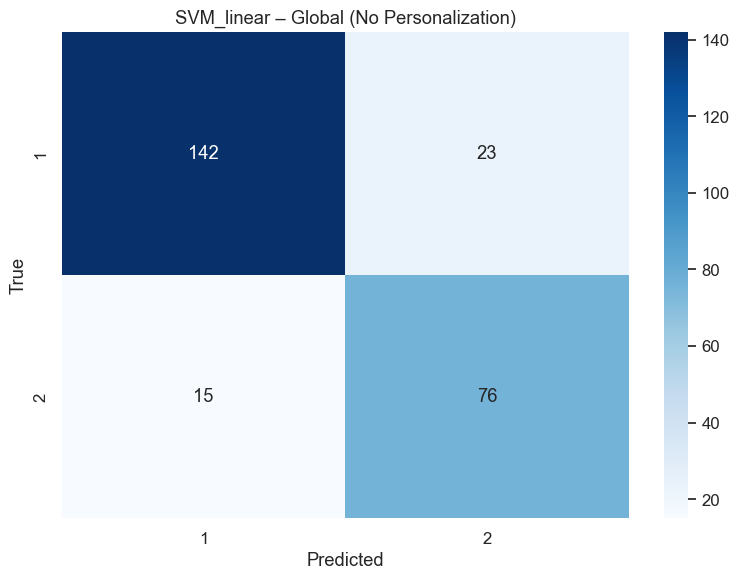

Classification report – SVM_linear Global:
              precision    recall  f1-score   support

           1       0.90      0.86      0.88       165
           2       0.77      0.84      0.80        91

    accuracy                           0.85       256
   macro avg       0.84      0.85      0.84       256
weighted avg       0.86      0.85      0.85       256



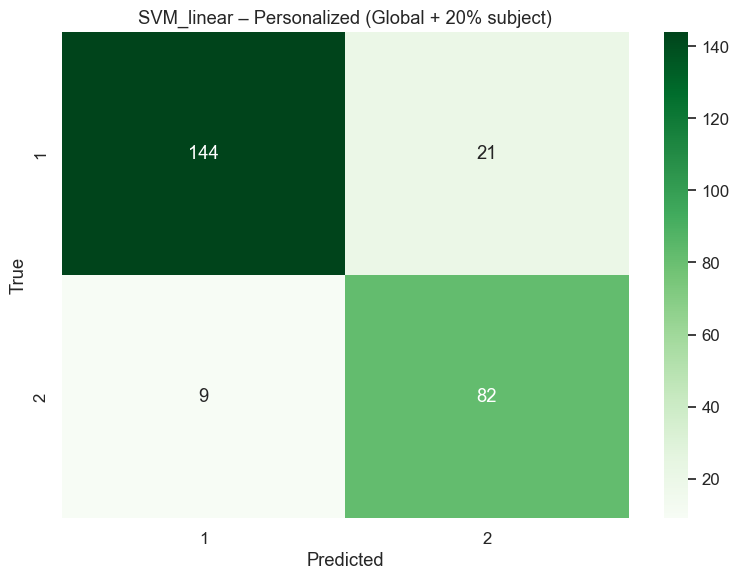

Classification report – SVM_linear Personalized:
              precision    recall  f1-score   support

           1       0.94      0.87      0.91       165
           2       0.80      0.90      0.85        91

    accuracy                           0.88       256
   macro avg       0.87      0.89      0.88       256
weighted avg       0.89      0.88      0.88       256



====== Confusion Matrices & Reports for SVM_rbf ======


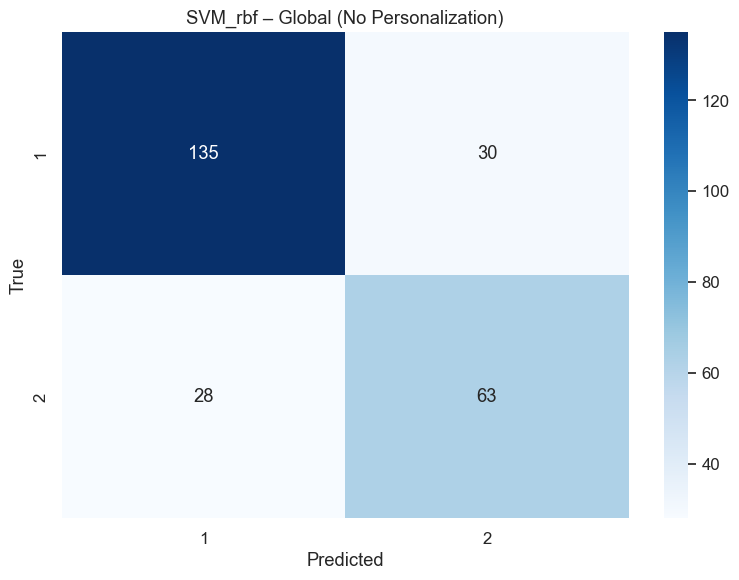

Classification report – SVM_rbf Global:
              precision    recall  f1-score   support

           1       0.83      0.82      0.82       165
           2       0.68      0.69      0.68        91

    accuracy                           0.77       256
   macro avg       0.75      0.76      0.75       256
weighted avg       0.77      0.77      0.77       256



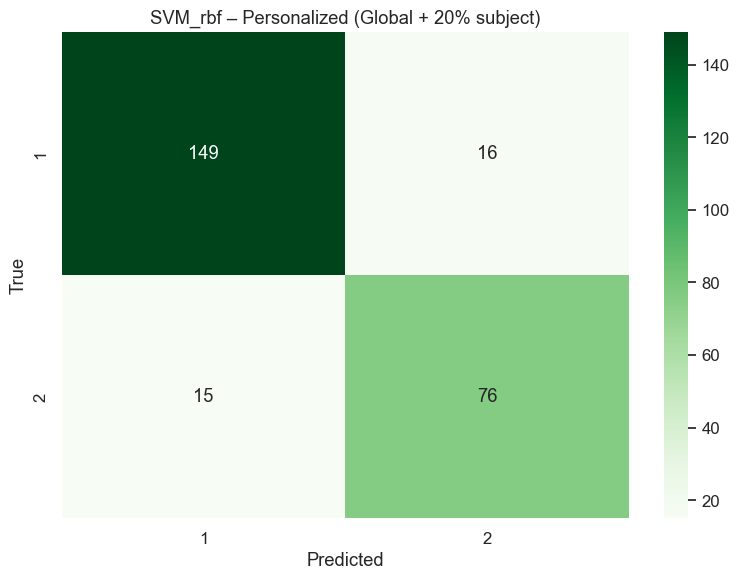

Classification report – SVM_rbf Personalized:
              precision    recall  f1-score   support

           1       0.91      0.90      0.91       165
           2       0.83      0.84      0.83        91

    accuracy                           0.88       256
   macro avg       0.87      0.87      0.87       256
weighted avg       0.88      0.88      0.88       256



====== Confusion Matrices & Reports for SVM_poly ======


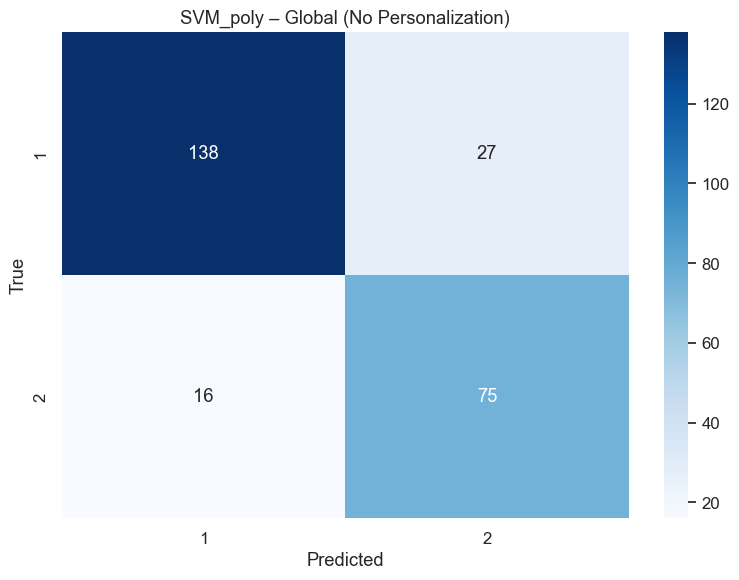

Classification report – SVM_poly Global:
              precision    recall  f1-score   support

           1       0.90      0.84      0.87       165
           2       0.74      0.82      0.78        91

    accuracy                           0.83       256
   macro avg       0.82      0.83      0.82       256
weighted avg       0.84      0.83      0.83       256



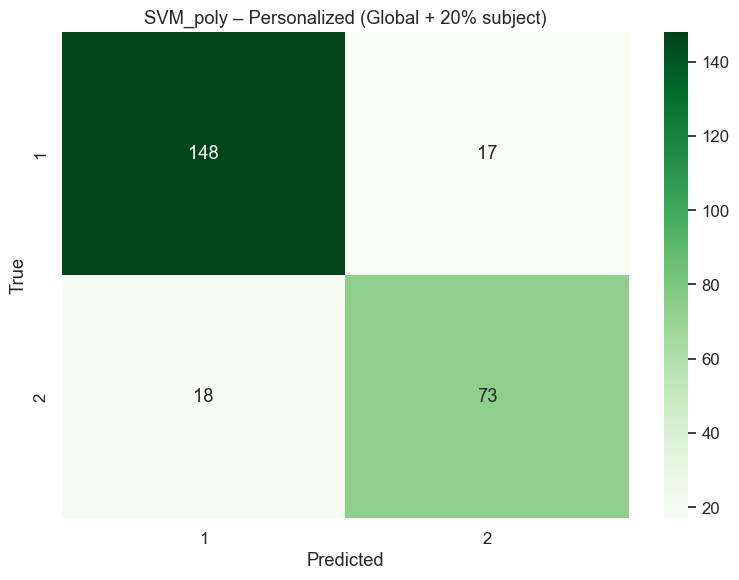

Classification report – SVM_poly Personalized:
              precision    recall  f1-score   support

           1       0.89      0.90      0.89       165
           2       0.81      0.80      0.81        91

    accuracy                           0.86       256
   macro avg       0.85      0.85      0.85       256
weighted avg       0.86      0.86      0.86       256



====== Confusion Matrices & Reports for XGBoost ======


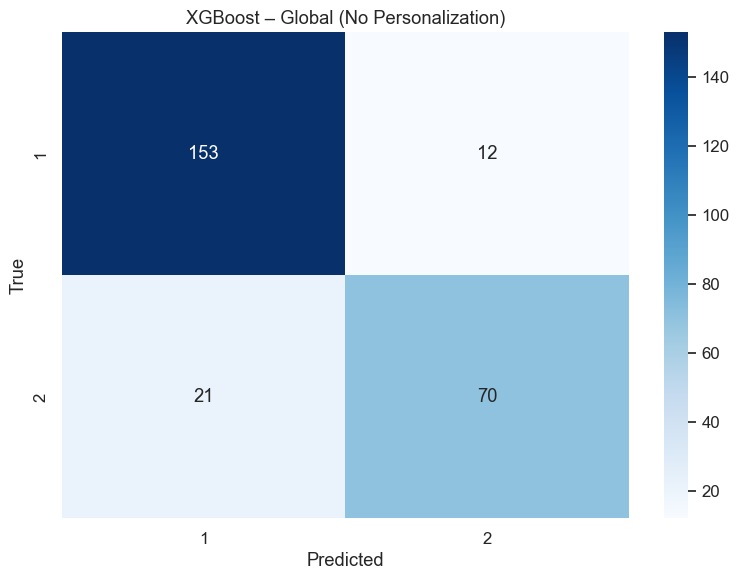

Classification report – XGBoost Global:
              precision    recall  f1-score   support

           1       0.88      0.93      0.90       165
           2       0.85      0.77      0.81        91

    accuracy                           0.87       256
   macro avg       0.87      0.85      0.86       256
weighted avg       0.87      0.87      0.87       256



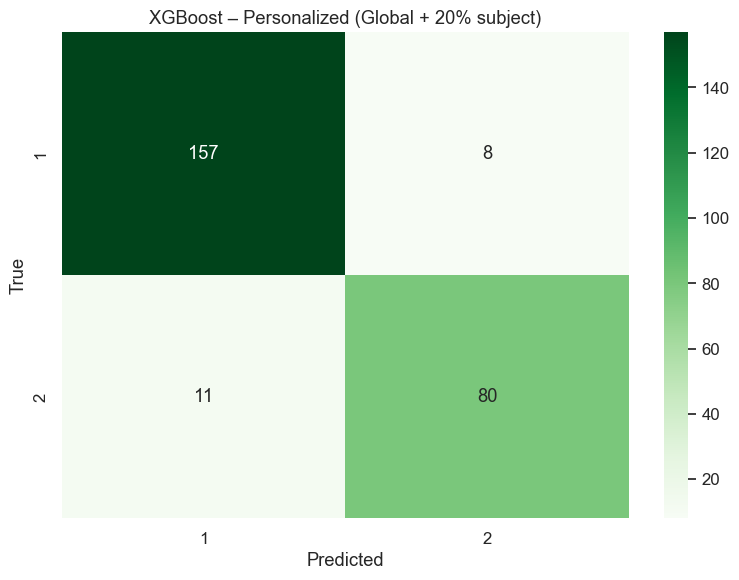

Classification report – XGBoost Personalized:
              precision    recall  f1-score   support

           1       0.93      0.95      0.94       165
           2       0.91      0.88      0.89        91

    accuracy                           0.93       256
   macro avg       0.92      0.92      0.92       256
weighted avg       0.93      0.93      0.93       256



====== Confusion Matrices & Reports for RandomForest ======


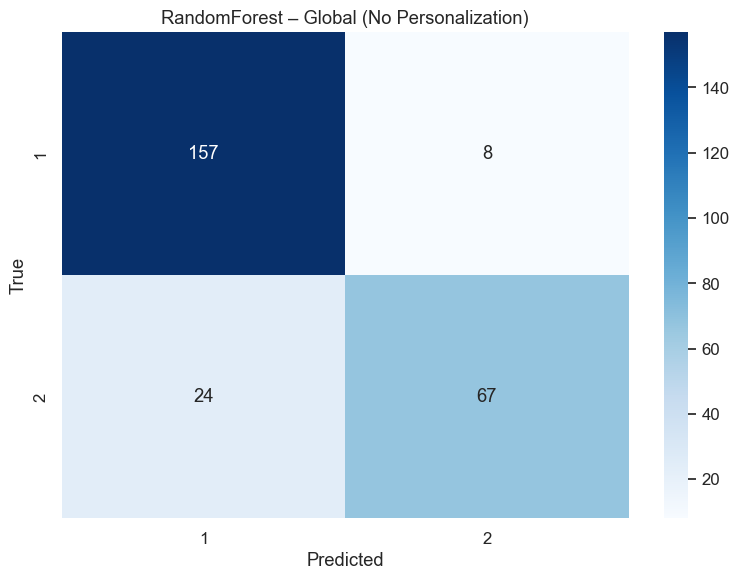

Classification report – RandomForest Global:
              precision    recall  f1-score   support

           1       0.87      0.95      0.91       165
           2       0.89      0.74      0.81        91

    accuracy                           0.88       256
   macro avg       0.88      0.84      0.86       256
weighted avg       0.88      0.88      0.87       256



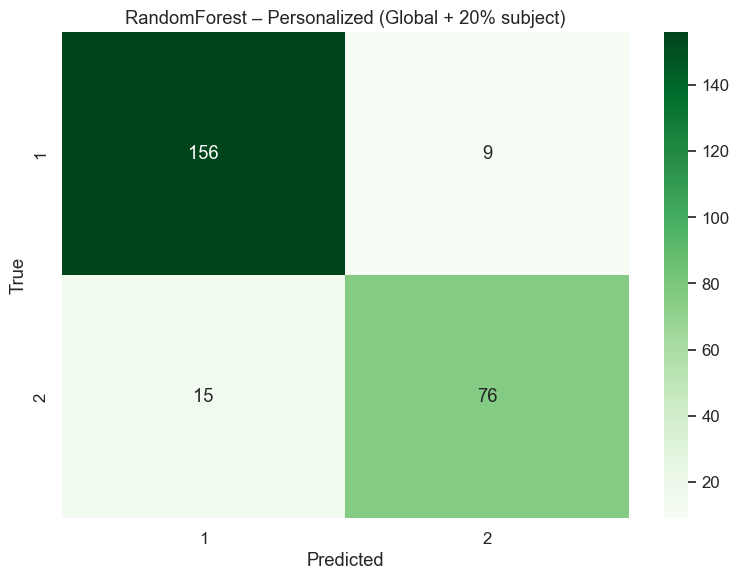

Classification report – RandomForest Personalized:
              precision    recall  f1-score   support

           1       0.91      0.95      0.93       165
           2       0.89      0.84      0.86        91

    accuracy                           0.91       256
   macro avg       0.90      0.89      0.90       256
weighted avg       0.91      0.91      0.91       256



In [ ]:
# === CELL: Classical ML classifiers with PCA – Global vs Personalized ===

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 0. Sanity check: we reuse the same PCA space as the MLP
# ---------------------------------------------------------
X_all_raw = X_raw           # numeric features, NaNs already handled
y_all     = y_all_bin       # {0,1}
subjects_all = subjects

print("Global subjects:", global_subjects)
print("Personal subjects:", personal_subjects)

# These should already exist from the MLP cell:
# scaler_global, pca_global, X_global_pca, y_global
print("Global PCA shape:", X_global_pca.shape)

N_PCA_MODEL = X_global_pca.shape[1]

# ---------------------------------------------------------
# 1. Classifier factory: new fresh instance each time
# ---------------------------------------------------------
def make_classifier(name):
    if name == "KNN_5":
        return KNeighborsClassifier(n_neighbors=5)
    elif name == "DecisionTree":
        return DecisionTreeClassifier(random_state=42)
    elif name == "SVM_linear":
        return SVC(kernel="linear", C=1.0)
    elif name == "SVM_rbf":
        return SVC(kernel="rbf", C=1.0, gamma="scale")
    elif name == "SVM_poly":
        return SVC(kernel="poly", degree=3, C=1.0, gamma="scale")
    elif name == "XGBoost":
        return xgb.XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            n_jobs=-1,
            random_state=42,
        )
    elif name == "RandomForest":
        return RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            random_state=42,
            n_jobs=-1,
        )
    else:
        raise ValueError(f"Unknown classifier name: {name}")

classifier_names = [
    "KNN_5",
    "DecisionTree",
    "SVM_linear",
    "SVM_rbf",
    "SVM_poly",
    "XGBoost",
    "RandomForest",
]

# ---------------------------------------------------------
# 2. Prepare global training data in PCA space
# ---------------------------------------------------------
mask_global = np.isin(subjects_all, global_subjects)
X_global_raw = X_all_raw[mask_global]
y_global     = y_all[mask_global]

# These should match what you used for MLP:
X_global_scaled = scaler_global.transform(X_global_raw)
X_global_pca    = pca_global.transform(X_global_scaled)

print("Global training data (PCA) shape:", X_global_pca.shape)

# ---------------------------------------------------------
# 3. Loop over personal subjects and classifiers
# ---------------------------------------------------------
results_per_classifier = {name: [] for name in classifier_names}

y_true_global_all = {name: [] for name in classifier_names}
y_pred_global_all = {name: [] for name in classifier_names}
y_true_pers_all   = {name: [] for name in classifier_names}
y_pred_pers_all   = {name: [] for name in classifier_names}

for s in personal_subjects:
    print(f"\n================ Subject {s} ================")

    # All data for this subject
    mask_s = (subjects_all == s)
    X_s_raw = X_all_raw[mask_s]
    y_s     = y_all[mask_s]

    # 20% for personalization training, 80% for test
    strat = y_s if len(np.unique(y_s)) > 1 else None
    X_train_raw, X_test_raw, y_train_s, y_test_s = train_test_split(
        X_s_raw,
        y_s,
        test_size=0.80,
        random_state=42,
        shuffle=True,
        stratify=strat,
    )

    print("  Personalization train shape:", X_train_raw.shape,
          "Test shape:", X_test_raw.shape)

    # Transform with GLOBAL scaler + PCA (no refit)
    X_train_scaled = scaler_global.transform(X_train_raw)
    X_test_scaled  = scaler_global.transform(X_test_raw)

    X_train_pca = pca_global.transform(X_train_scaled)
    X_test_pca  = pca_global.transform(X_test_scaled)

    # Personalized training set: global + 20% of subject s
    X_train_pers = np.vstack([X_global_pca, X_train_pca])
    y_train_pers = np.concatenate([y_global, y_train_s])

    # ---------------------------------------
    # For each classifier: global vs personal
    # ---------------------------------------
    for name in classifier_names:
        print(f"    -> Classifier: {name}")

        # ---- (a) Global-only training ----
        clf_global = make_classifier(name)
        clf_global.fit(X_global_pca, y_global)
        y_pred_global = clf_global.predict(X_test_pca)
        acc_global = accuracy_score(y_test_s, y_pred_global)

        # ---- (b) Personalized training ----
        clf_pers = make_classifier(name)
        clf_pers.fit(X_train_pers, y_train_pers)
        y_pred_pers = clf_pers.predict(X_test_pca)
        acc_pers = accuracy_score(y_test_s, y_pred_pers)

        print(f"       Global acc:       {acc_global:.4f}")
        print(f"       Personalized acc: {acc_pers:.4f}")

        # Store per-subject result
        results_per_classifier[name].append({
            "subject": s,
            "acc_global": acc_global,
            "acc_personal": acc_pers,
        })

        # Store for confusion matrices / reports
        y_true_global_all[name].extend(y_test_s)
        y_pred_global_all[name].extend(y_pred_global)

        y_true_pers_all[name].extend(y_test_s)
        y_pred_pers_all[name].extend(y_pred_pers)

# ---------------------------------------------------------
# 4. Summary tables per classifier
# ---------------------------------------------------------
all_results_tables = {}

for name in classifier_names:
    df_res = pd.DataFrame(results_per_classifier[name])
    df_res["delta"] = df_res["acc_personal"] - df_res["acc_global"]
    all_results_tables[name] = df_res
    print(f"\n================ Results for {name} ================")
    display(df_res)
    print("Mean global acc:      ", df_res["acc_global"].mean())
    print("Mean personalized acc:", df_res["acc_personal"].mean())
    print("Mean delta (pers-glob):", df_res["delta"].mean())

# ---------------------------------------------------------
# 5. Confusion matrices & classification reports
#    (aggregated over the 4 personal subjects)
# ---------------------------------------------------------
inv_label_mapping = {v: k for k, v in label_mapping.items()}
labels_orig = [1, 2]

def remap_back(y_bin_arr):
    return np.vectorize(inv_label_mapping.get)(y_bin_arr)

for name in classifier_names:
    print(f"\n\n====== Confusion Matrices & Reports for {name} ======")

    y_true_g = np.array(y_true_global_all[name])
    y_pred_g = np.array(y_pred_global_all[name])
    y_true_p = np.array(y_true_pers_all[name])
    y_pred_p = np.array(y_pred_pers_all[name])

    y_true_g_orig = remap_back(y_true_g)
    y_pred_g_orig = remap_back(y_pred_g)
    y_true_p_orig = remap_back(y_true_p)
    y_pred_p_orig = remap_back(y_pred_p)

    # Global confusion matrix
    cm_g = confusion_matrix(y_true_g_orig, y_pred_g_orig, labels=labels_orig)
    plt.figure()
    sns.heatmap(
        cm_g,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels_orig,
        yticklabels=labels_orig
    )
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"{name} – Global (No Personalization)")
    plt.tight_layout()
    plt.show()

    print(f"Classification report – {name} Global:")
    print(classification_report(y_true_g_orig, y_pred_g_orig, labels=labels_orig))

    # Personalized confusion matrix
    cm_p = confusion_matrix(y_true_p_orig, y_pred_p_orig, labels=labels_orig)
    plt.figure()
    sns.heatmap(
        cm_p,
        annot=True,
        fmt="d",
        cmap="Greens",
        xticklabels=labels_orig,
        yticklabels=labels_orig
    )
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"{name} – Personalized (Global + 20% subject)")
    plt.tight_layout()
    plt.show()

    print(f"Classification report – {name} Personalized:")
    print(classification_report(y_true_p_orig, y_pred_p_orig, labels=labels_orig))


[I 2025-11-19 14:51:17,793] A new study created in memory with name: tune_KNN_5


All subjects: [ 2  3  4  5  6  7  8  9 10 11 13 14 15 16 17]
Global subjects: [11 14  2 16  7 10  4  3 17  6  9]
Personal subjects: [13 15  5  8]
Using PCA components: 27

==================== Tuning KNN_5 ====================


[I 2025-11-19 14:51:18,089] Trial 0 finished with value: 0.8062340668252137 and parameters: {'n_neighbors': 13, 'weights': 'uniform', 'p': 2}. Best is trial 0 with value: 0.8062340668252137.
[I 2025-11-19 14:51:18,379] Trial 1 finished with value: 0.8057224362254304 and parameters: {'n_neighbors': 9, 'weights': 'uniform', 'p': 2}. Best is trial 0 with value: 0.8062340668252137.
[I 2025-11-19 14:51:18,666] Trial 2 finished with value: 0.7731987426238857 and parameters: {'n_neighbors': 1, 'weights': 'distance', 'p': 1}. Best is trial 0 with value: 0.8062340668252137.
[I 2025-11-19 14:51:18,950] Trial 3 finished with value: 0.8037654072224558 and parameters: {'n_neighbors': 17, 'weights': 'distance', 'p': 2}. Best is trial 0 with value: 0.8062340668252137.
[I 2025-11-19 14:51:19,227] Trial 4 finished with value: 0.8057224362254304 and parameters: {'n_neighbors': 9, 'weights': 'distance', 'p': 2}. Best is trial 0 with value: 0.8062340668252137.
[I 2025-11-19 14:51:19,388] Trial 5 finished 


Best params for KNN_5:
{'n_neighbors': 25, 'weights': 'distance', 'p': 1}
Best LOSO accuracy: 0.8477

==================== Tuning DecisionTree ====================


[I 2025-11-19 14:51:24,642] Trial 0 finished with value: 0.8305131615246786 and parameters: {'max_depth': 3, 'min_samples_split': 14, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.8305131615246786.
[I 2025-11-19 14:51:24,961] Trial 1 finished with value: 0.8143807747129074 and parameters: {'max_depth': 20, 'min_samples_split': 19, 'min_samples_leaf': 1}. Best is trial 0 with value: 0.8305131615246786.
[I 2025-11-19 14:51:25,224] Trial 2 finished with value: 0.8131549315289387 and parameters: {'max_depth': 5, 'min_samples_split': 15, 'min_samples_leaf': 7}. Best is trial 0 with value: 0.8305131615246786.
[I 2025-11-19 14:51:25,504] Trial 3 finished with value: 0.7778597075326861 and parameters: {'max_depth': 6, 'min_samples_split': 14, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.8305131615246786.
[I 2025-11-19 14:51:25,809] Trial 4 finished with value: 0.7757387027892833 and parameters: {'max_depth': 10, 'min_samples_split': 10, 'min_samples_leaf': 2}. Best is trial 0 


Best params for DecisionTree:
{'max_depth': 3, 'min_samples_split': 7, 'min_samples_leaf': 10}
Best LOSO accuracy: 0.8316

==================== Tuning SVM_linear ====================


... (20 outputs left out)

,subject,acc_global,acc_personal,delta
0,13,0.968750,0.968750,0.00000
1,15,0.671875,0.703125,0.03125
2,5,0.937500,0.937500,0.00000
3,8,0.937500,0.968750,0.03125


Mean global acc:       0.87890625
Mean personalized acc: 0.89453125
Mean delta (pers-glob): 0.015625

================ Results for RandomForest (tuned) ================


,subject,acc_global,acc_personal,delta
0,13,0.968750,0.953125,-0.015625
1,15,0.640625,0.734375,0.093750
2,5,0.937500,0.937500,0.000000
3,8,0.937500,0.968750,0.031250


Mean global acc:       0.87109375
Mean personalized acc: 0.8984375
Mean delta (pers-glob): 0.02734375


====== Confusion Matrices & Reports for KNN_5 (tuned) ======


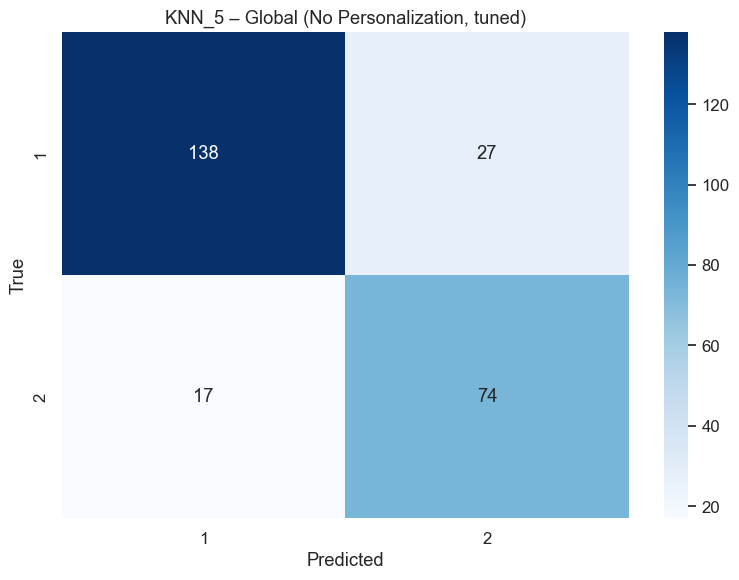

Classification report – KNN_5 Global (tuned):
              precision    recall  f1-score   support

           1       0.89      0.84      0.86       165
           2       0.73      0.81      0.77        91

    accuracy                           0.83       256
   macro avg       0.81      0.82      0.82       256
weighted avg       0.83      0.83      0.83       256



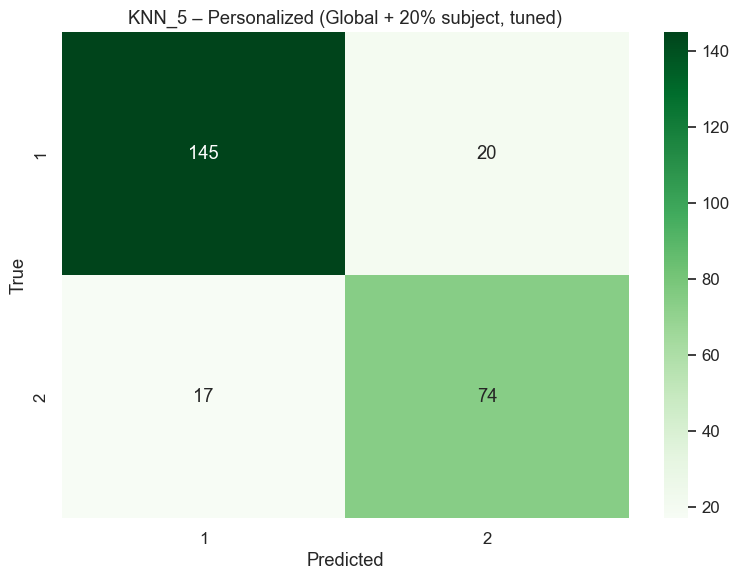

Classification report – KNN_5 Personalized (tuned):
              precision    recall  f1-score   support

           1       0.90      0.88      0.89       165
           2       0.79      0.81      0.80        91

    accuracy                           0.86       256
   macro avg       0.84      0.85      0.84       256
weighted avg       0.86      0.86      0.86       256



====== Confusion Matrices & Reports for DecisionTree (tuned) ======


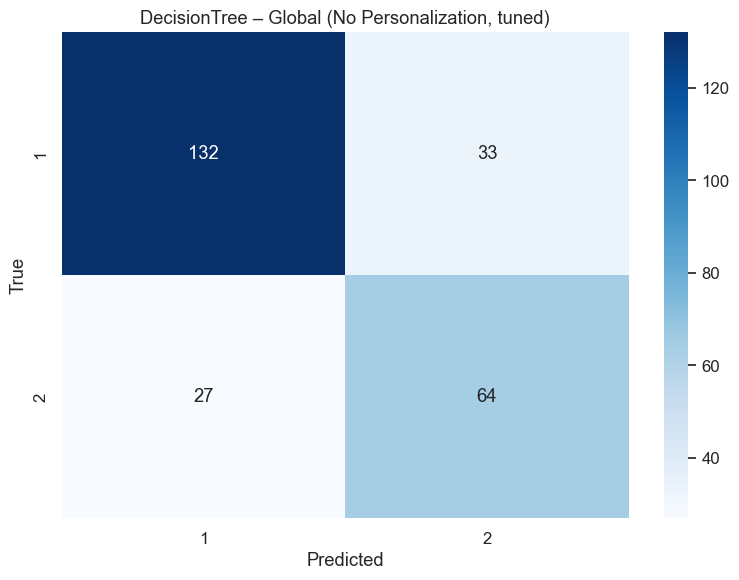

Classification report – DecisionTree Global (tuned):
              precision    recall  f1-score   support

           1       0.83      0.80      0.81       165
           2       0.66      0.70      0.68        91

    accuracy                           0.77       256
   macro avg       0.74      0.75      0.75       256
weighted avg       0.77      0.77      0.77       256



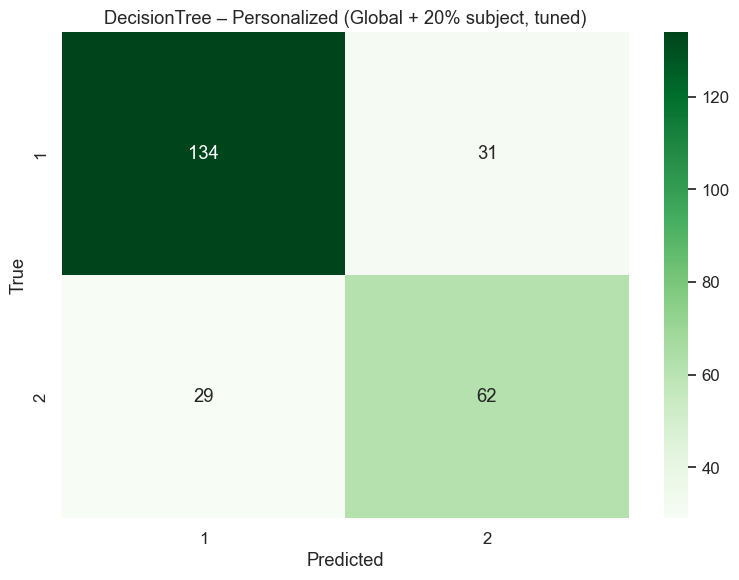

Classification report – DecisionTree Personalized (tuned):
              precision    recall  f1-score   support

           1       0.82      0.81      0.82       165
           2       0.67      0.68      0.67        91

    accuracy                           0.77       256
   macro avg       0.74      0.75      0.75       256
weighted avg       0.77      0.77      0.77       256



====== Confusion Matrices & Reports for SVM_linear (tuned) ======


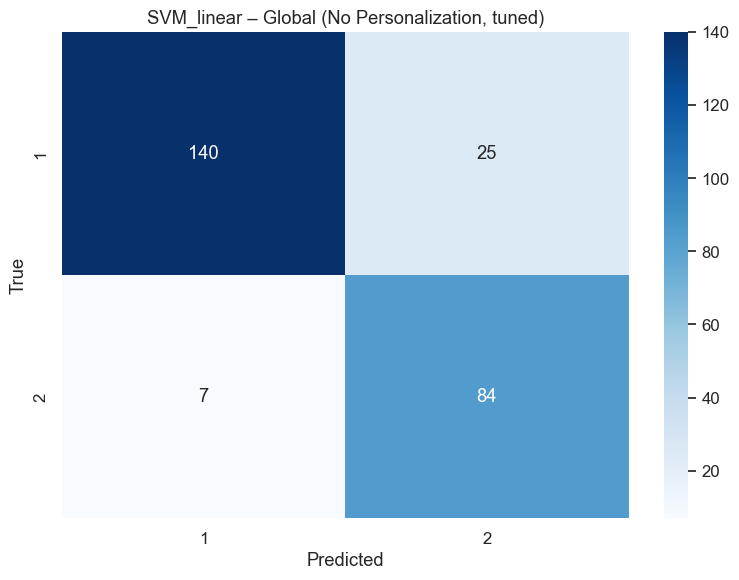

Classification report – SVM_linear Global (tuned):
              precision    recall  f1-score   support

           1       0.95      0.85      0.90       165
           2       0.77      0.92      0.84        91

    accuracy                           0.88       256
   macro avg       0.86      0.89      0.87       256
weighted avg       0.89      0.88      0.88       256



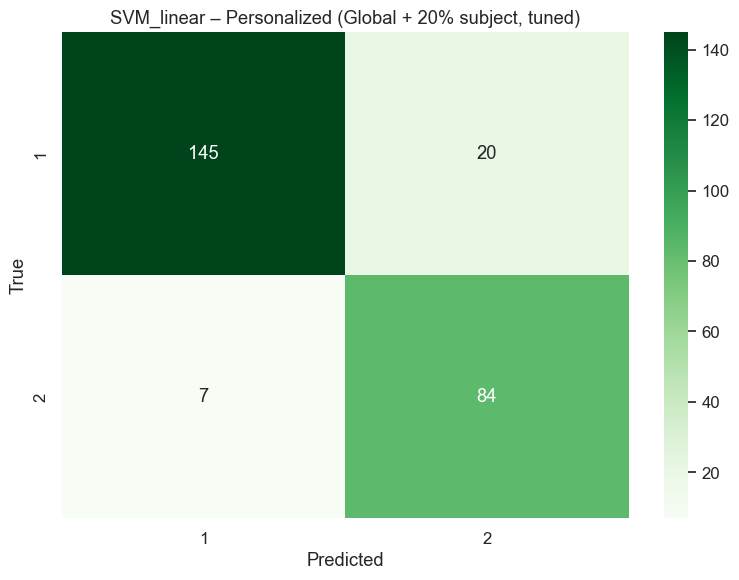

Classification report – SVM_linear Personalized (tuned):
              precision    recall  f1-score   support

           1       0.95      0.88      0.91       165
           2       0.81      0.92      0.86        91

    accuracy                           0.89       256
   macro avg       0.88      0.90      0.89       256
weighted avg       0.90      0.89      0.90       256



====== Confusion Matrices & Reports for SVM_rbf (tuned) ======


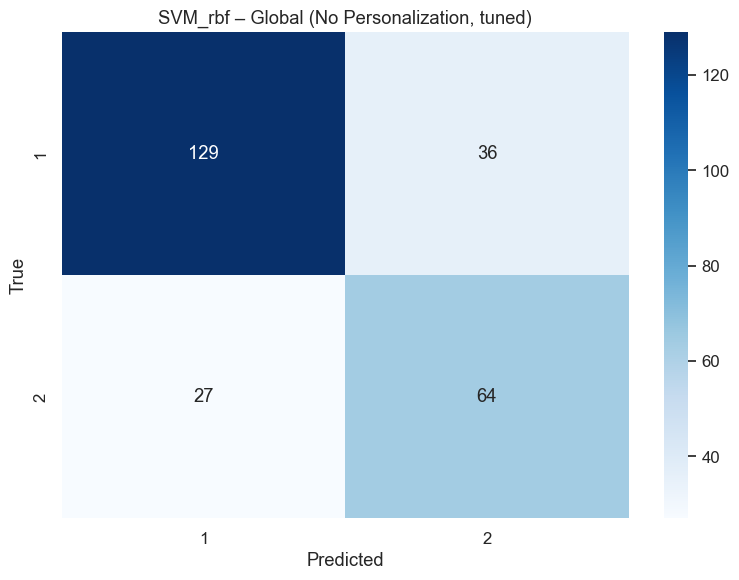

Classification report – SVM_rbf Global (tuned):
              precision    recall  f1-score   support

           1       0.83      0.78      0.80       165
           2       0.64      0.70      0.67        91

    accuracy                           0.75       256
   macro avg       0.73      0.74      0.74       256
weighted avg       0.76      0.75      0.76       256



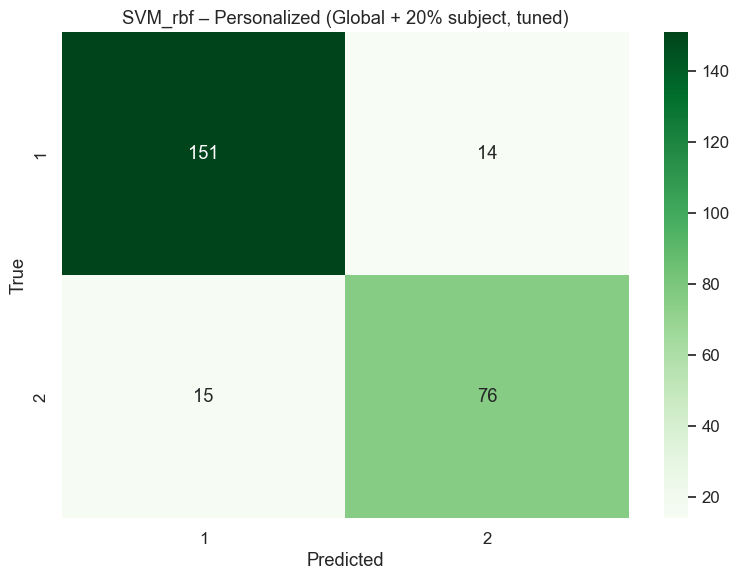

Classification report – SVM_rbf Personalized (tuned):
              precision    recall  f1-score   support

           1       0.91      0.92      0.91       165
           2       0.84      0.84      0.84        91

    accuracy                           0.89       256
   macro avg       0.88      0.88      0.88       256
weighted avg       0.89      0.89      0.89       256



====== Confusion Matrices & Reports for SVM_poly (tuned) ======


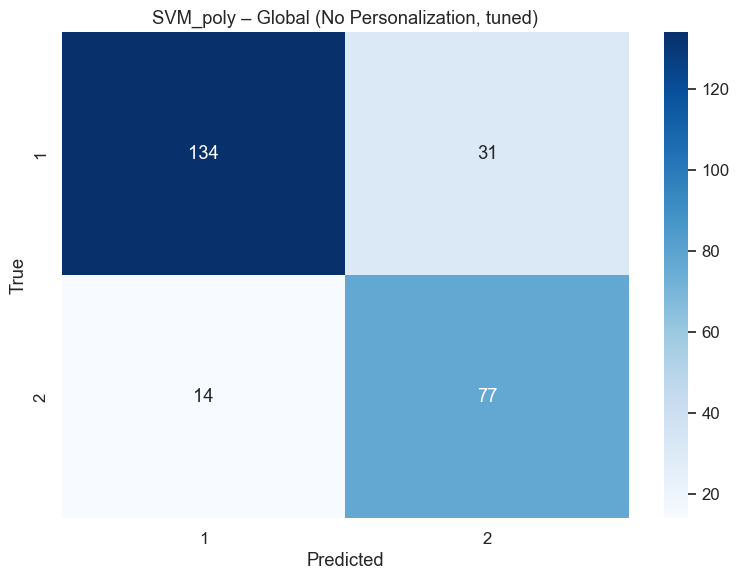

Classification report – SVM_poly Global (tuned):
              precision    recall  f1-score   support

           1       0.91      0.81      0.86       165
           2       0.71      0.85      0.77        91

    accuracy                           0.82       256
   macro avg       0.81      0.83      0.82       256
weighted avg       0.84      0.82      0.83       256



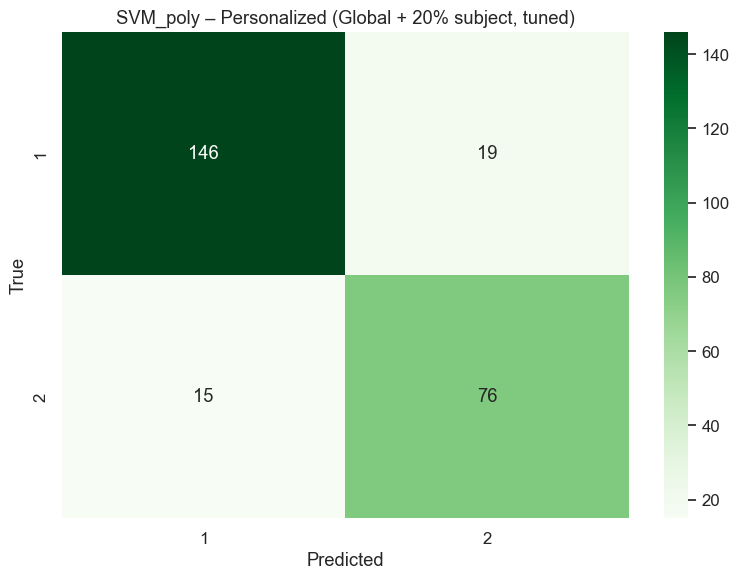

Classification report – SVM_poly Personalized (tuned):
              precision    recall  f1-score   support

           1       0.91      0.88      0.90       165
           2       0.80      0.84      0.82        91

    accuracy                           0.87       256
   macro avg       0.85      0.86      0.86       256
weighted avg       0.87      0.87      0.87       256



====== Confusion Matrices & Reports for XGBoost (tuned) ======


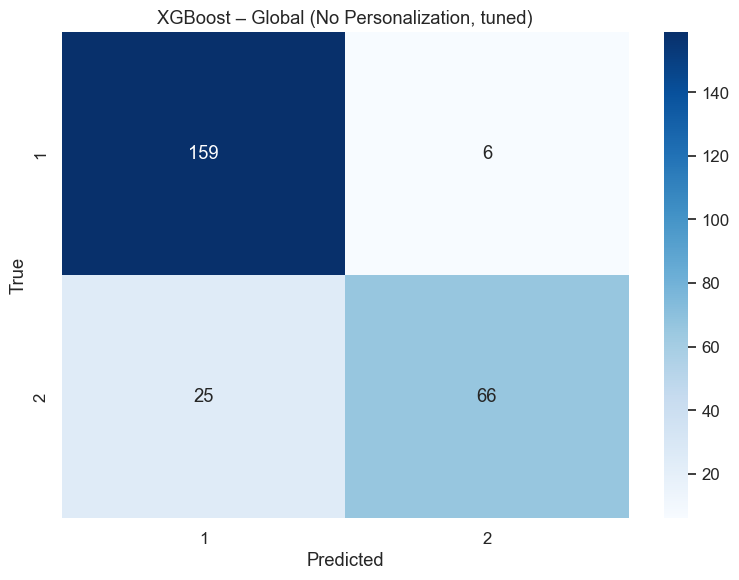

Classification report – XGBoost Global (tuned):
              precision    recall  f1-score   support

           1       0.86      0.96      0.91       165
           2       0.92      0.73      0.81        91

    accuracy                           0.88       256
   macro avg       0.89      0.84      0.86       256
weighted avg       0.88      0.88      0.88       256



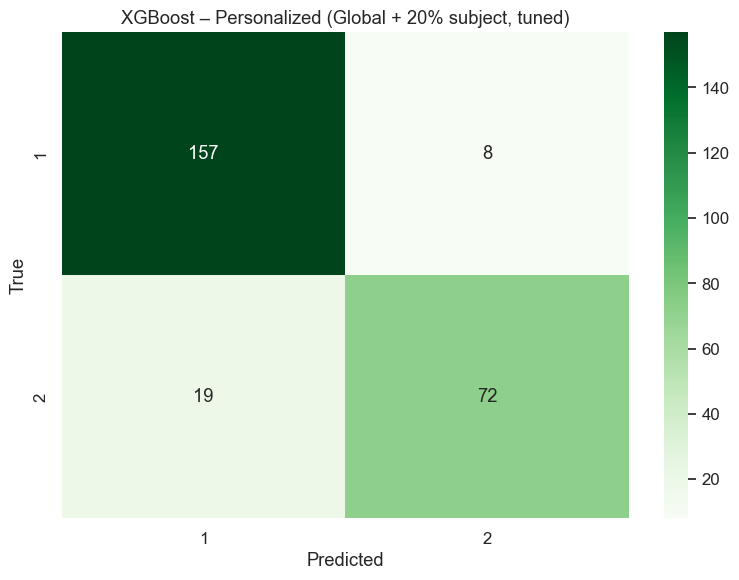

Classification report – XGBoost Personalized (tuned):
              precision    recall  f1-score   support

           1       0.89      0.95      0.92       165
           2       0.90      0.79      0.84        91

    accuracy                           0.89       256
   macro avg       0.90      0.87      0.88       256
weighted avg       0.89      0.89      0.89       256



====== Confusion Matrices & Reports for RandomForest (tuned) ======


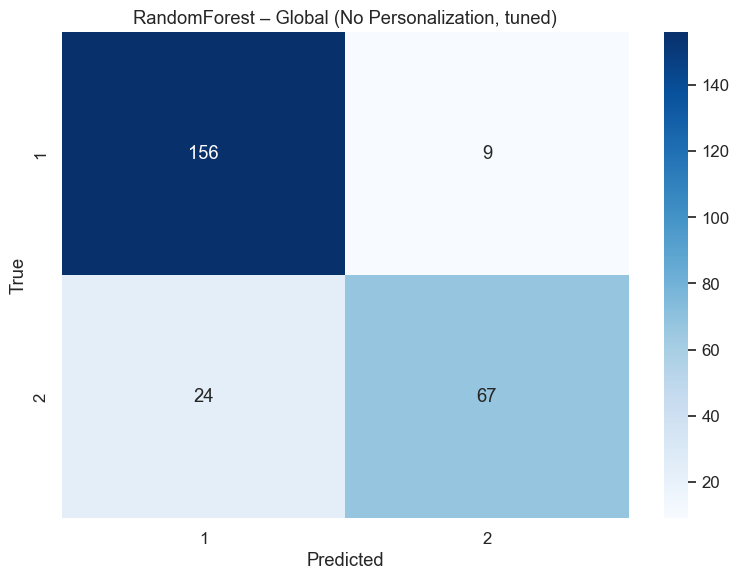

Classification report – RandomForest Global (tuned):
              precision    recall  f1-score   support

           1       0.87      0.95      0.90       165
           2       0.88      0.74      0.80        91

    accuracy                           0.87       256
   macro avg       0.87      0.84      0.85       256
weighted avg       0.87      0.87      0.87       256



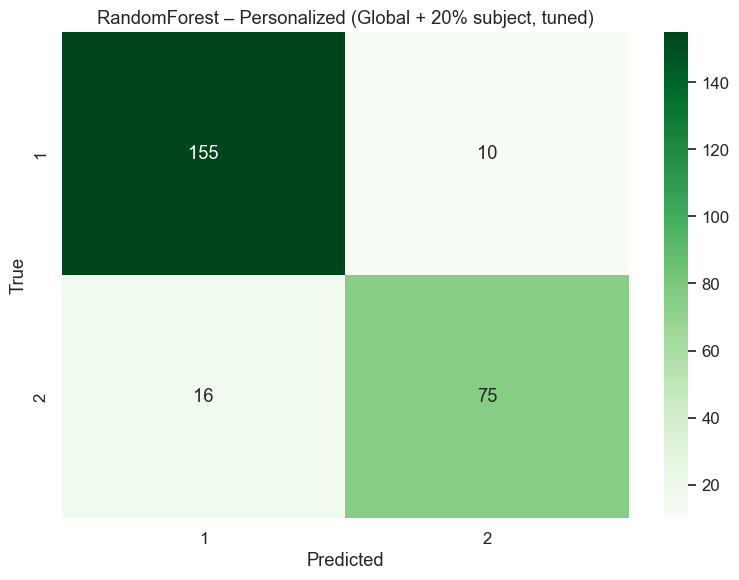

Classification report – RandomForest Personalized (tuned):
              precision    recall  f1-score   support

           1       0.91      0.94      0.92       165
           2       0.88      0.82      0.85        91

    accuracy                           0.90       256
   macro avg       0.89      0.88      0.89       256
weighted avg       0.90      0.90      0.90       256



In [ ]:
# === CELL: Optuna-tuned classical ML classifiers with PCA – Global vs Personalized ===

# If optuna is not installed, uncomment:
# !pip install optuna xgboost

import numpy as np
import pandas as pd

import optuna

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 0. Prepare data and settings
# ---------------------------------------------------------
X_all_raw = X_raw           # numeric features, NaNs handled
y_all     = y_bin           # {0,1}
subjects_all = subjects

print("All subjects:", np.unique(subjects_all))
print("Global subjects:", global_subjects)
print("Personal subjects:", personal_subjects)

# Use 27 PCA components as before (95% variance)
N_PCA_MODEL = min(27, X_all_raw.shape[1])
print("Using PCA components:", N_PCA_MODEL)

classifier_names = [
    "KNN_5",
    "DecisionTree",
    "SVM_linear",
    "SVM_rbf",
    "SVM_poly",
    "XGBoost",
    "RandomForest",
]

# ---------------------------------------------------------
# 1. Helper: build classifier from trial (for Optuna)
# ---------------------------------------------------------
def build_classifier_from_trial(name, trial):
    if name == "KNN_5":
        n_neighbors = trial.suggest_int("n_neighbors", 1, 25)
        weights = trial.suggest_categorical("weights", ["uniform", "distance"])
        p = trial.suggest_int("p", 1, 2)  # 1: Manhattan, 2: Euclidean
        return KNeighborsClassifier(
            n_neighbors=n_neighbors,
            weights=weights,
            p=p,
        )

    elif name == "DecisionTree":
        max_depth = trial.suggest_int("max_depth", 2, 20)
        min_samples_split = trial.suggest_int("min_samples_split", 2, 20)
        min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 10)
        return DecisionTreeClassifier(
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            random_state=42,
        )

    elif name == "SVM_linear":
        C = trial.suggest_float("C", 1e-3, 1e3, log=True)
        return SVC(
            kernel="linear",
            C=C,
        )

    elif name == "SVM_rbf":
        C = trial.suggest_float("C", 1e-3, 1e3, log=True)
        gamma = trial.suggest_float("gamma", 1e-4, 1.0, log=True)
        return SVC(
            kernel="rbf",
            C=C,
            gamma=gamma,
        )

    elif name == "SVM_poly":
        C = trial.suggest_float("C", 1e-3, 1e3, log=True)
        degree = trial.suggest_int("degree", 2, 5)
        gamma = trial.suggest_float("gamma", 1e-4, 1.0, log=True)
        return SVC(
            kernel="poly",
            C=C,
            degree=degree,
            gamma=gamma,
        )

    elif name == "XGBoost":
        n_estimators = trial.suggest_int("n_estimators", 100, 400)
        max_depth = trial.suggest_int("max_depth", 2, 8)
        learning_rate = trial.suggest_float("learning_rate", 1e-3, 0.3, log=True)
        subsample = trial.suggest_float("subsample", 0.5, 1.0)
        colsample_bytree = trial.suggest_float("colsample_bytree", 0.5, 1.0)
        return xgb.XGBClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            learning_rate=learning_rate,
            subsample=subsample,
            colsample_bytree=colsample_bytree,
            objective="binary:logistic",
            eval_metric="logloss",
            n_jobs=-1,
            random_state=42,
            tree_method="hist",
        )

    elif name == "RandomForest":
        n_estimators = trial.suggest_int("n_estimators", 100, 400)
        max_depth = trial.suggest_int("max_depth", 2, 20)
        min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 10)
        max_features = trial.suggest_categorical("max_features", ["sqrt", "log2", None])
        return RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            random_state=42,
            n_jobs=-1,
        )

    else:
        raise ValueError(f"Unknown classifier name: {name}")

# ---------------------------------------------------------
# 2. Optuna tuning: LOSO CV on global subjects, with scaler & PCA
# ---------------------------------------------------------
def tune_classifier_with_optuna(name, n_trials=25):
    """
    Tune hyperparams of classifier `name` using LOSO CV on global subjects.
    Inside each trial:
      - For each global test subject:
        * Fit scaler + PCA on training subjects only
        * Fit classifier with trial hyperparams
        * Evaluate on that test subject in PCA space
      - Return mean LOSO accuracy as objective.
    """

    def objective(trial):
        accs = []

        for test_sub in global_subjects:
            # LOSO fold
            train_mask = np.isin(subjects_all, global_subjects) & (subjects_all != test_sub)
            test_mask  = (subjects_all == test_sub)

            X_train_raw = X_all_raw[train_mask]
            y_train     = y_all[train_mask]

            X_test_raw  = X_all_raw[test_mask]
            y_test      = y_all[test_mask]

            # Fit scaler and PCA on TRAIN ONLY
            scaler = StandardScaler().fit(X_train_raw)
            X_train_scaled = scaler.transform(X_train_raw)
            X_test_scaled  = scaler.transform(X_test_raw)

            pca = PCA(n_components=N_PCA_MODEL).fit(X_train_scaled)
            X_train_pca = pca.transform(X_train_scaled)
            X_test_pca  = pca.transform(X_test_scaled)

            clf = build_classifier_from_trial(name, trial)
            clf.fit(X_train_pca, y_train)
            y_pred = clf.predict(X_test_pca)
            acc = accuracy_score(y_test, y_pred)
            accs.append(acc)

        return np.mean(accs)

    study = optuna.create_study(
        direction="maximize",
        study_name=f"tune_{name}",
    )
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    print(f"\nBest params for {name}:")
    print(study.best_params)
    print(f"Best LOSO accuracy: {study.best_value:.4f}")

    return study.best_params, study.best_value

best_params_dict = {}
best_loso_scores = {}

for name in classifier_names:
    print(f"\n==================== Tuning {name} ====================")
    best_params, best_score = tune_classifier_with_optuna(name, n_trials=25)
    best_params_dict[name] = best_params
    best_loso_scores[name] = best_score

print("\n=== Summary of best LOSO scores on global subjects ===")
for name in classifier_names:
    print(f"{name}: {best_loso_scores[name]:.4f}")

# ---------------------------------------------------------
# 3. Build classifier from best params (no Optuna inside)
# ---------------------------------------------------------
def make_classifier_from_best(name, best_params):
    # Wrap build_classifier_from_trial but with fixed params
    class DummyTrial:
        def __init__(self, params):
            self.params = params
        def suggest_int(self, name, low, high):
            return self.params[name]
        def suggest_float(self, name, low, high, log=False):
            return self.params[name]
        def suggest_categorical(self, name, choices):
            return self.params[name]

    dummy_trial = DummyTrial(best_params)
    return build_classifier_from_trial(name, dummy_trial)

# ---------------------------------------------------------
# 4. Prepare global PCA space for final training
#    (Scaler + PCA fit once on all global subjects, as in MLP pipeline)
# ---------------------------------------------------------
mask_global = np.isin(subjects_all, global_subjects)
X_global_raw = X_all_raw[mask_global]
y_global     = y_all[mask_global]

scaler_global = StandardScaler().fit(X_global_raw)
X_global_scaled = scaler_global.transform(X_global_raw)

pca_global = PCA(n_components=N_PCA_MODEL).fit(X_global_scaled)
X_global_pca = pca_global.transform(X_global_scaled)

print("\nGlobal PCA training data shape:", X_global_pca.shape)

# ---------------------------------------------------------
# 5. Evaluate tuned classifiers: Global vs Personalized
#    (same logic as before, but using best_params_dict)
# ---------------------------------------------------------
results_per_classifier = {name: [] for name in classifier_names}

y_true_global_all = {name: [] for name in classifier_names}
y_pred_global_all = {name: [] for name in classifier_names}
y_true_pers_all   = {name: [] for name in classifier_names}
y_pred_pers_all   = {name: [] for name in classifier_names}

for s in personal_subjects:
    print(f"\n================ Subject {s} ================")

    # All data for this subject
    mask_s = (subjects_all == s)
    X_s_raw = X_all_raw[mask_s]
    y_s     = y_all[mask_s]

    # 20% for personalization training, 80% for test
    strat = y_s if len(np.unique(y_s)) > 1 else None
    X_train_raw, X_test_raw, y_train_s, y_test_s = train_test_split(
        X_s_raw,
        y_s,
        test_size=0.80,
        random_state=42,
        shuffle=True,
        stratify=strat,
    )

    print("  Personalization train shape:", X_train_raw.shape,
          "Test shape:", X_test_raw.shape)

    # Transform with GLOBAL scaler + PCA
    X_train_scaled = scaler_global.transform(X_train_raw)
    X_test_scaled  = scaler_global.transform(X_test_raw)

    X_train_pca = pca_global.transform(X_train_scaled)
    X_test_pca  = pca_global.transform(X_test_scaled)

    # Personalized training set = global + 20% of subject s
    X_train_pers = np.vstack([X_global_pca, X_train_pca])
    y_train_pers = np.concatenate([y_global, y_train_s])

    for name in classifier_names:
        print(f"    -> Classifier: {name}")

        # ---- Global-only training ----
        clf_global = make_classifier_from_best(name, best_params_dict[name])
        clf_global.fit(X_global_pca, y_global)
        y_pred_global = clf_global.predict(X_test_pca)
        acc_global = accuracy_score(y_test_s, y_pred_global)

        # ---- Personalized training: global + 20% subject s ----
        clf_pers = make_classifier_from_best(name, best_params_dict[name])
        clf_pers.fit(X_train_pers, y_train_pers)
        y_pred_pers = clf_pers.predict(X_test_pca)
        acc_pers = accuracy_score(y_test_s, y_pred_pers)

        print(f"       Global acc:       {acc_global:.4f}")
        print(f"       Personalized acc: {acc_pers:.4f}")

        results_per_classifier[name].append({
            "subject": s,
            "acc_global": acc_global,
            "acc_personal": acc_pers,
        })

        y_true_global_all[name].extend(y_test_s)
        y_pred_global_all[name].extend(y_pred_global)

        y_true_pers_all[name].extend(y_test_s)
        y_pred_pers_all[name].extend(y_pred_pers)

# ---------------------------------------------------------
# 6. Summary tables per classifier
# ---------------------------------------------------------
all_results_tables = {}

for name in classifier_names:
    df_res = pd.DataFrame(results_per_classifier[name])
    df_res["delta"] = df_res["acc_personal"] - df_res["acc_global"]
    all_results_tables[name] = df_res

    print(f"\n================ Results for {name} (tuned) ================")
    display(df_res)
    print("Mean global acc:      ", df_res["acc_global"].mean())
    print("Mean personalized acc:", df_res["acc_personal"].mean())
    print("Mean delta (pers-glob):", df_res["delta"].mean())

# ---------------------------------------------------------
# 7. Confusion matrices & classification reports (personal subjects)
# ---------------------------------------------------------
inv_label_mapping = {v: k for k, v in label_mapping.items()}
labels_orig = [1, 2]

def remap_back(y_bin_arr):
    return np.vectorize(inv_label_mapping.get)(y_bin_arr)

for name in classifier_names:
    print(f"\n\n====== Confusion Matrices & Reports for {name} (tuned) ======")

    y_true_g = np.array(y_true_global_all[name])
    y_pred_g = np.array(y_pred_global_all[name])
    y_true_p = np.array(y_true_pers_all[name])
    y_pred_p = np.array(y_pred_pers_all[name])

    y_true_g_orig = remap_back(y_true_g)
    y_pred_g_orig = remap_back(y_pred_g)
    y_true_p_orig = remap_back(y_true_p)
    y_pred_p_orig = remap_back(y_pred_p)

    # Global confusion matrix
    cm_g = confusion_matrix(y_true_g_orig, y_pred_g_orig, labels=labels_orig)
    plt.figure()
    sns.heatmap(
        cm_g,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels_orig,
        yticklabels=labels_orig
    )
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"{name} – Global (No Personalization, tuned)")
    plt.tight_layout()
    plt.show()

    print(f"Classification report – {name} Global (tuned):")
    print(classification_report(y_true_g_orig, y_pred_g_orig, labels=labels_orig))

    # Personalized confusion matrix
    cm_p = confusion_matrix(y_true_p_orig, y_pred_p_orig, labels=labels_orig)
    plt.figure()
    sns.heatmap(
        cm_p,
        annot=True,
        fmt="d",
        cmap="Greens",
        xticklabels=labels_orig,
        yticklabels=labels_orig
    )
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"{name} – Personalized (Global + 20% subject, tuned)")
    plt.tight_layout()
    plt.show()

    print(f"Classification report – {name} Personalized (tuned):")
    print(classification_report(y_true_p_orig, y_pred_p_orig, labels=labels_orig))


## Clustering

Using PCA components: 27

=== KMeans – Metrics ===
ARI:          0.0820
NMI:          0.0368
Homogeneity:  0.0323
Completeness: 0.0426
V-measure:    0.0368
Silhouette:   0.2884
Accuracy*:    0.6653  (after cluster→label mapping)

Confusion Matrix:
[[658 102]
 [295 131]]

Classification Report:
              precision    recall  f1-score   support

           1       0.69      0.87      0.77       760
           2       0.56      0.31      0.40       426

    accuracy                           0.67      1186
   macro avg       0.63      0.59      0.58      1186
weighted avg       0.64      0.67      0.64      1186



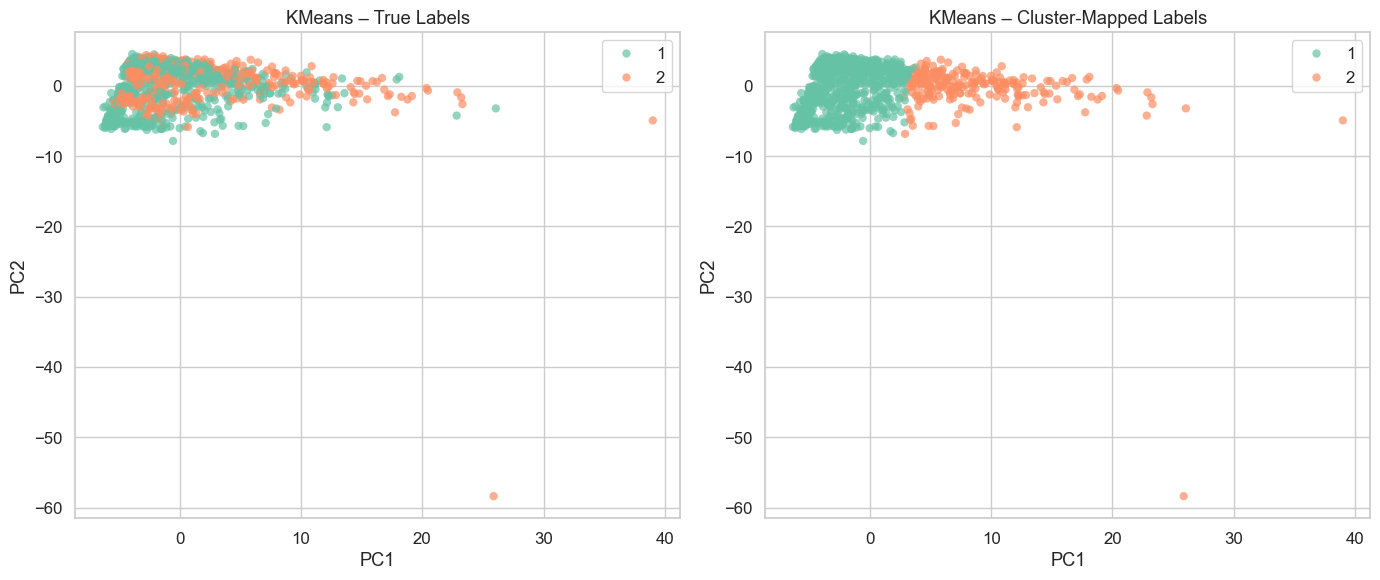


=== GMM – Metrics ===
ARI:          0.2830
NMI:          0.2000
Homogeneity:  0.2032
Completeness: 0.1970
V-measure:    0.2000
Silhouette:   0.1343
Accuracy*:    0.7673  (after cluster→label mapping)

Confusion Matrix:
[[597 163]
 [113 313]]

Classification Report:
              precision    recall  f1-score   support

           1       0.84      0.79      0.81       760
           2       0.66      0.73      0.69       426

    accuracy                           0.77      1186
   macro avg       0.75      0.76      0.75      1186
weighted avg       0.78      0.77      0.77      1186



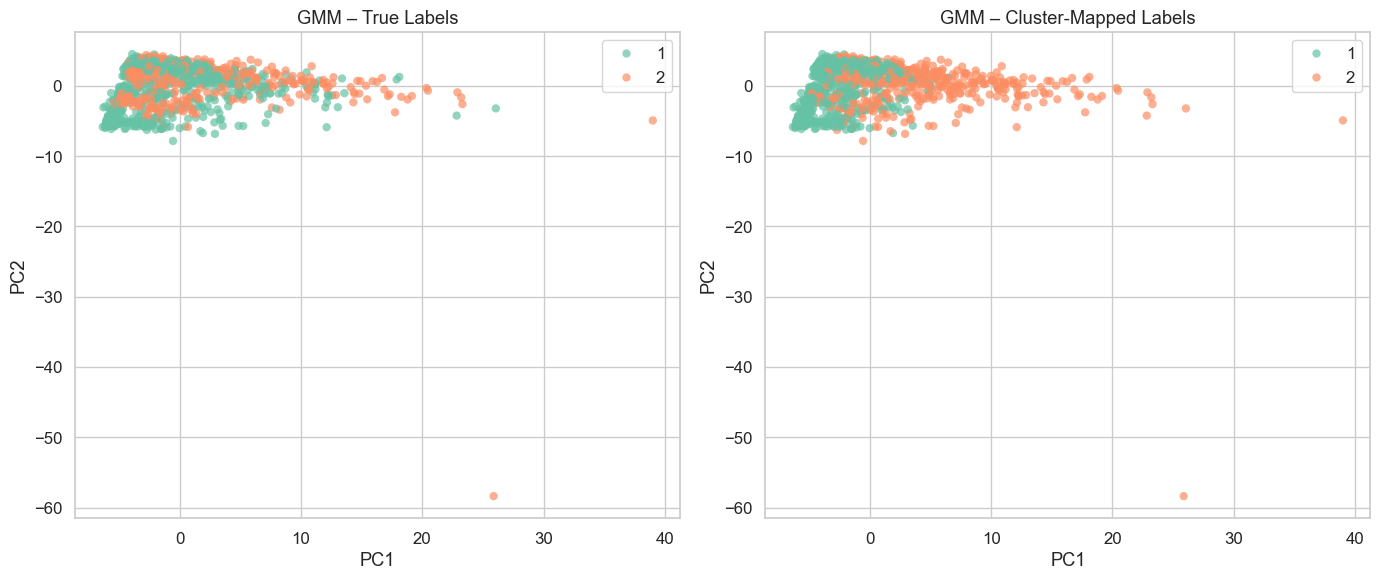


=== Spectral – Metrics ===
ARI:          -0.0138
NMI:          0.0273
Homogeneity:  0.0262
Completeness: 0.0285
V-measure:    0.0273
Silhouette:   0.1268
Accuracy*:    0.6408  (after cluster→label mapping)

Confusion Matrix:
[[760   0]
 [426   0]]

Classification Report:
              precision    recall  f1-score   support

           1       0.64      1.00      0.78       760
           2       0.00      0.00      0.00       426

    accuracy                           0.64      1186
   macro avg       0.32      0.50      0.39      1186
weighted avg       0.41      0.64      0.50      1186



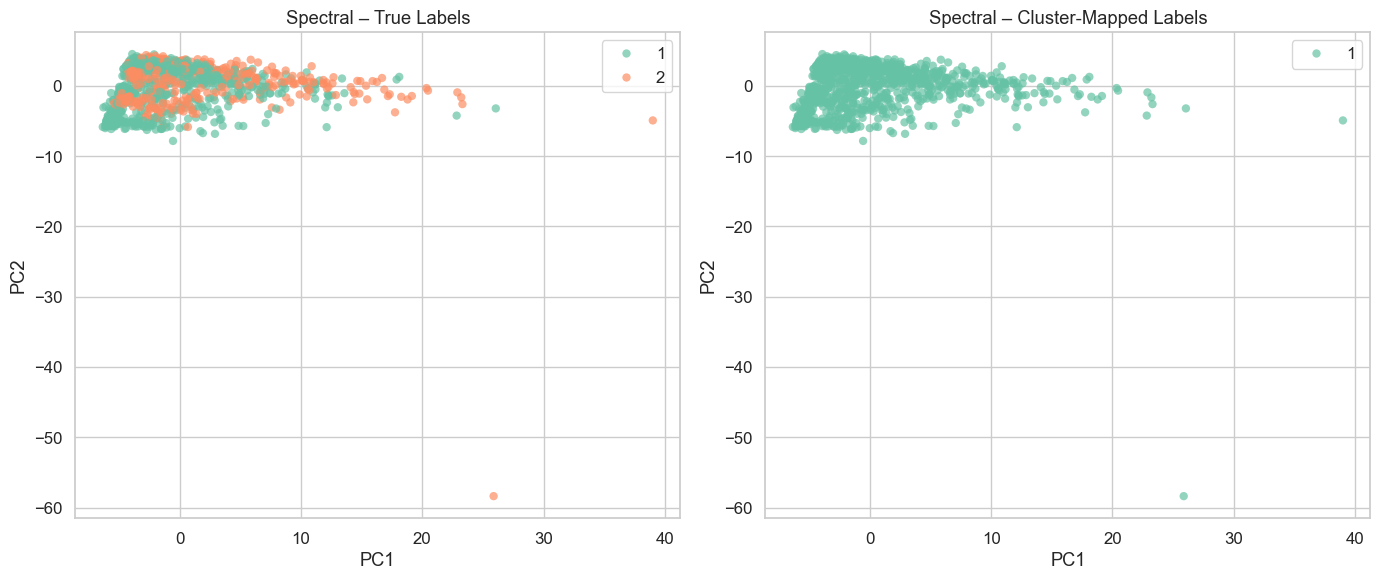


=== Unsupervised Clustering Summary ===


,Method,ARI,NMI,Homogeneity,Completeness,V-measure,Silhouette,LabelMapped_ACC
0,KMeans,0.081961,0.036780,0.032345,0.042626,0.036780,0.288439,0.665261
1,GMM,0.283016,0.200015,0.203170,0.196955,0.200015,0.134309,0.767285
2,Spectral,-0.013789,0.027304,0.026195,0.028511,0.027304,0.126801,0.640809


In [ ]:
# === CELL: Unsupervised clustering (KMeans, GMM, Spectral Clustering) in PCA space ===

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    silhouette_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
)

import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 0. Prepare data and PCA representation for clustering
# ---------------------------------------------------------
X_all_raw = X_raw
y_true_bin = y_bin

inv_label_mapping = {v: k for k, v in label_mapping.items()}
y_true_orig = np.vectorize(inv_label_mapping.get)(y_true_bin)
n_classes = len(np.unique(y_true_orig))

# PCA components used previously
N_PCA_CLUSTER = min(27, X_all_raw.shape[1])

scaler_clust = StandardScaler().fit(X_all_raw)
X_scaled_clust = scaler_clust.transform(X_all_raw)

pca_clust = PCA(n_components=N_PCA_CLUSTER).fit(X_scaled_clust)
X_pca_clust = pca_clust.transform(X_scaled_clust)

# 2D PCA for visualization
X_pca_2d = X_pca_clust[:, :2]

palette_set2 = sns.color_palette("Set2", n_classes)

print("Using PCA components:", N_PCA_CLUSTER)

# ---------------------------------------------------------
# 1. Majority-vote label mapping
# ---------------------------------------------------------
def best_cluster_label_mapping(y_true_bin, cluster_labels):
    mapping = {}
    for c in np.unique(cluster_labels):
        mask = cluster_labels == c
        true_labels_in_cluster = y_true_bin[mask]
        majority = np.bincount(true_labels_in_cluster).argmax()
        mapping[c] = majority
    return mapping

# ---------------------------------------------------------
# 2. Evaluate clustering
# ---------------------------------------------------------
def evaluate_clustering(name, cluster_labels, X_feat, y_true_bin):
    y_true_bin = np.asarray(y_true_bin)
    cluster_labels = np.asarray(cluster_labels)

    # Unsupervised metrics
    ari = adjusted_rand_score(y_true_bin, cluster_labels)
    nmi = normalized_mutual_info_score(y_true_bin, cluster_labels)
    homo = homogeneity_score(y_true_bin, cluster_labels)
    comp = completeness_score(y_true_bin, cluster_labels)
    v_meas = v_measure_score(y_true_bin, cluster_labels)

    if len(np.unique(cluster_labels)) > 1:
        sil = silhouette_score(X_feat, cluster_labels)
    else:
        sil = np.nan

    # Label mapping
    mapping = best_cluster_label_mapping(y_true_bin, cluster_labels)
    y_pred_bin = np.array([mapping[c] for c in cluster_labels])

    acc = accuracy_score(y_true_bin, y_pred_bin)

    # Back to original labels
    y_true_orig2 = np.vectorize(inv_label_mapping.get)(y_true_bin)
    y_pred_orig2 = np.vectorize(inv_label_mapping.get)(y_pred_bin)

    cm = confusion_matrix(y_true_orig2, y_pred_orig2, labels=np.unique(y_true_orig))
    cls_rep = classification_report(
        y_true_orig2,
        y_pred_orig2,
        labels=np.unique(y_true_orig),
        zero_division=0
    )

    print(f"\n=== {name} – Metrics ===")
    print(f"ARI:          {ari:.4f}")
    print(f"NMI:          {nmi:.4f}")
    print(f"Homogeneity:  {homo:.4f}")
    print(f"Completeness: {comp:.4f}")
    print(f"V-measure:    {v_meas:.4f}")
    print(f"Silhouette:   {sil:.4f}")
    print(f"Accuracy*:    {acc:.4f}  (after cluster→label mapping)")

    print("\nConfusion Matrix:")
    print(cm)
    print("\nClassification Report:")
    print(cls_rep)

    return {
        "ari": ari,
        "nmi": nmi,
        "homogeneity": homo,
        "completeness": comp,
        "v_measure": v_meas,
        "silhouette": sil,
        "accuracy": acc,
        "cluster_labels": cluster_labels,
        "y_pred_orig": y_pred_orig2,
    }

# ---------------------------------------------------------
# 3. Visualization
# ---------------------------------------------------------
def plot_2d(name, X_2d, y_true, y_pred, palette):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # True
    sns.scatterplot(
        x=X_2d[:, 0],
        y=X_2d[:, 1],
        hue=y_true,
        palette=palette,
        ax=axes[0],
        edgecolor="none",
        alpha=0.7,
    )
    axes[0].set_title(f"{name} – True Labels")
    axes[0].set_xlabel("PC1")
    axes[0].set_ylabel("PC2")

    # Pred
    sns.scatterplot(
        x=X_2d[:, 0],
        y=X_2d[:, 1],
        hue=y_pred,
        palette=palette,
        ax=axes[1],
        edgecolor="none",
        alpha=0.7,
    )
    axes[1].set_title(f"{name} – Cluster-Mapped Labels")
    axes[1].set_xlabel("PC1")
    axes[1].set_ylabel("PC2")

    plt.tight_layout()
    plt.show()

# =========================================================
# 4. Run clustering algorithms
# =========================================================

results = {}

# ----- 4.1 KMeans -----
kmeans = KMeans(n_clusters=n_classes, n_init=20, random_state=42)
labels_kmeans = kmeans.fit_predict(X_pca_clust)
res_kmeans = evaluate_clustering("KMeans", labels_kmeans, X_pca_clust, y_true_bin)
results["KMeans"] = res_kmeans
plot_2d("KMeans", X_pca_2d, y_true_orig, res_kmeans["y_pred_orig"], palette_set2)

# ----- 4.2 Gaussian Mixture Model -----
gmm = GaussianMixture(n_components=n_classes, covariance_type="full", random_state=42)
labels_gmm = gmm.fit_predict(X_pca_clust)
res_gmm = evaluate_clustering("GMM", labels_gmm, X_pca_clust, y_true_bin)
results["GMM"] = res_gmm
plot_2d("GMM", X_pca_2d, y_true_orig, res_gmm["y_pred_orig"], palette_set2)

# ----- 4.3 Spectral Clustering -----
spectral = SpectralClustering(
    n_clusters=n_classes,
    assign_labels="kmeans",
    affinity="nearest_neighbors",   # best for physiological datasets
    n_neighbors=15,
    random_state=42,
)
labels_spec = spectral.fit_predict(X_pca_clust)
res_spec = evaluate_clustering("Spectral", labels_spec, X_pca_clust, y_true_bin)
results["Spectral"] = res_spec
plot_2d("Spectral", X_pca_2d, y_true_orig, res_spec["y_pred_orig"], palette_set2)

# Show summary
summary_df = pd.DataFrame([
    {
        "Method": name,
        "ARI": r["ari"],
        "NMI": r["nmi"],
        "Homogeneity": r["homogeneity"],
        "Completeness": r["completeness"],
        "V-measure": r["v_measure"],
        "Silhouette": r["silhouette"],
        "LabelMapped_ACC": r["accuracy"],
    }
    for name, r in results.items()
])

print("\n=== Unsupervised Clustering Summary ===")
display(summary_df)


[I 2025-11-19 14:57:14,335] A new study created in memory with name: kmeans_ari
[I 2025-11-19 14:57:14,469] Trial 0 finished with value: 0.08196122364437035 and parameters: {'n_init': 17, 'max_iter': 230, 'algorithm': 'lloyd'}. Best is trial 0 with value: 0.08196122364437035.


Number of samples: 1186
Number of features: 102
Classes: [1 2]
Using PCA components: 27

=== Tuning KMeans with Optuna (objective = ARI) ===


[I 2025-11-19 14:57:14,605] Trial 1 finished with value: 0.08196122364437035 and parameters: {'n_init': 17, 'max_iter': 284, 'algorithm': 'lloyd'}. Best is trial 0 with value: 0.08196122364437035.
[I 2025-11-19 14:57:14,892] Trial 2 finished with value: 0.08196122364437035 and parameters: {'n_init': 30, 'max_iter': 237, 'algorithm': 'elkan'}. Best is trial 0 with value: 0.08196122364437035.
[I 2025-11-19 14:57:14,980] Trial 3 finished with value: 0.08196122364437035 and parameters: {'n_init': 11, 'max_iter': 432, 'algorithm': 'lloyd'}. Best is trial 0 with value: 0.08196122364437035.
[I 2025-11-19 14:57:15,196] Trial 4 finished with value: 0.08196122364437035 and parameters: {'n_init': 28, 'max_iter': 238, 'algorithm': 'lloyd'}. Best is trial 0 with value: 0.08196122364437035.
[I 2025-11-19 14:57:15,364] Trial 5 finished with value: 0.08196122364437035 and parameters: {'n_init': 22, 'max_iter': 415, 'algorithm': 'lloyd'}. Best is trial 0 with value: 0.08196122364437035.
[I 2025-11-19 1

Best KMeans params: {'n_init': 17, 'max_iter': 230, 'algorithm': 'lloyd'}
Best KMeans ARI:    0.08196122364437035

=== Tuning GMM with Optuna (objective = ARI) ===


[I 2025-11-19 14:57:18,627] Trial 5 finished with value: 0.2830161082162493 and parameters: {'covariance_type': 'full', 'reg_covar': 6.085759190188242e-06}. Best is trial 5 with value: 0.2830161082162493.
[I 2025-11-19 14:57:18,643] Trial 6 finished with value: 0.06951754469271643 and parameters: {'covariance_type': 'spherical', 'reg_covar': 0.0009275181235007472}. Best is trial 5 with value: 0.2830161082162493.
[I 2025-11-19 14:57:18,660] Trial 7 finished with value: 0.0502666748079635 and parameters: {'covariance_type': 'diag', 'reg_covar': 0.0002854896710295287}. Best is trial 5 with value: 0.2830161082162493.
[I 2025-11-19 14:57:18,676] Trial 8 finished with value: 0.07083136783847002 and parameters: {'covariance_type': 'spherical', 'reg_covar': 9.675196674753028e-05}. Best is trial 5 with value: 0.2830161082162493.
[I 2025-11-19 14:57:18,691] Trial 9 finished with value: 0.07083136783847002 and parameters: {'covariance_type': 'spherical', 'reg_covar': 1.685410794330283e-06}. Best 

Best GMM params: {'covariance_type': 'full', 'reg_covar': 6.085759190188242e-06}
Best GMM ARI:    0.2830161082162493

=== Tuning Spectral Clustering with Optuna (objective = ARI) ===


[I 2025-11-19 14:57:19,929] Trial 1 finished with value: -0.007231709734508138 and parameters: {'n_neighbors': 29, 'assign_labels': 'discretize'}. Best is trial 1 with value: -0.007231709734508138.
[I 2025-11-19 14:57:20,105] Trial 2 finished with value: -0.00713791389045049 and parameters: {'n_neighbors': 32, 'assign_labels': 'discretize'}. Best is trial 2 with value: -0.00713791389045049.
[I 2025-11-19 14:57:20,220] Trial 3 finished with value: -0.009427489044159527 and parameters: {'n_neighbors': 8, 'assign_labels': 'discretize'}. Best is trial 2 with value: -0.00713791389045049.
[I 2025-11-19 14:57:20,469] Trial 4 finished with value: -0.01015942727684216 and parameters: {'n_neighbors': 25, 'assign_labels': 'kmeans'}. Best is trial 2 with value: -0.00713791389045049.
[I 2025-11-19 14:57:20,706] Trial 5 finished with value: -0.008297769735193906 and parameters: {'n_neighbors': 38, 'assign_labels': 'kmeans'}. Best is trial 2 with value: -0.00713791389045049.
[I 2025-11-19 14:57:20,88

Best Spectral params: {'n_neighbors': 26, 'assign_labels': 'discretize'}
Best Spectral ARI:    -0.006668109853012441

=== KMeans (tuned) – Metrics ===
ARI:          0.0820
NMI:          0.0368
Homogeneity:  0.0323
Completeness: 0.0426
V-measure:    0.0368
Silhouette:   0.2884
Accuracy*:    0.6653  (after cluster→label mapping)

Confusion Matrix:
[[658 102]
 [295 131]]

Classification Report:
              precision    recall  f1-score   support

           1       0.69      0.87      0.77       760
           2       0.56      0.31      0.40       426

    accuracy                           0.67      1186
   macro avg       0.63      0.59      0.58      1186
weighted avg       0.64      0.67      0.64      1186



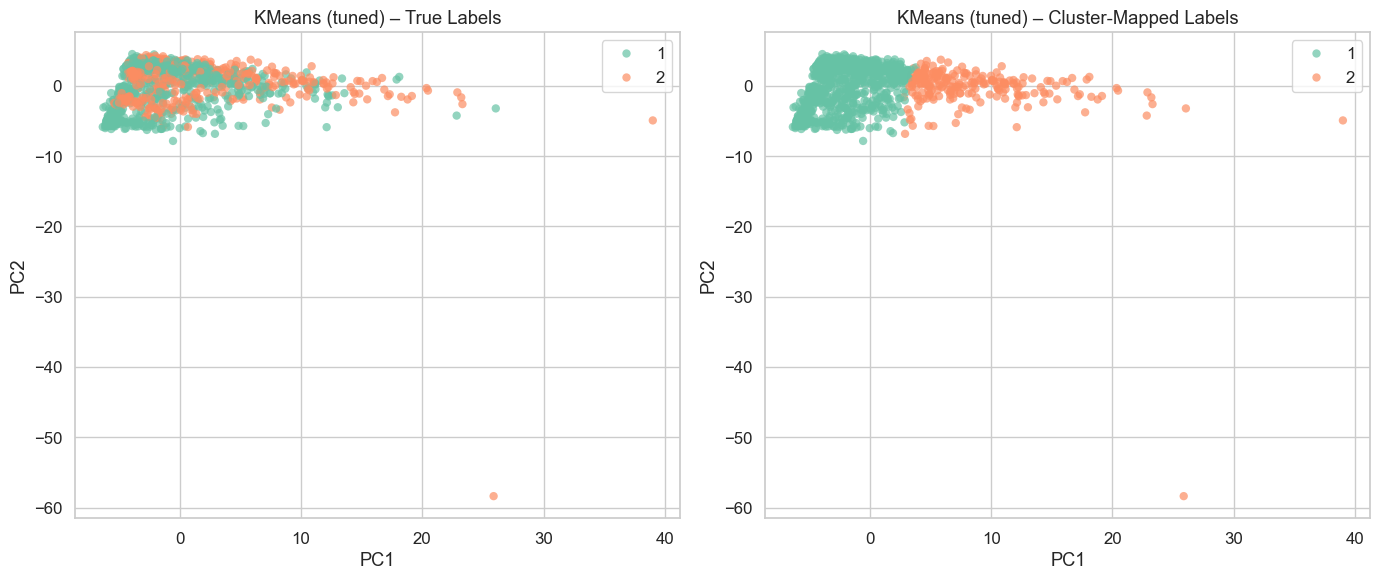


=== GMM (tuned) – Metrics ===
ARI:          0.2830
NMI:          0.2000
Homogeneity:  0.2032
Completeness: 0.1970
V-measure:    0.2000
Silhouette:   0.1343
Accuracy*:    0.7673  (after cluster→label mapping)

Confusion Matrix:
[[597 163]
 [113 313]]

Classification Report:
              precision    recall  f1-score   support

           1       0.84      0.79      0.81       760
           2       0.66      0.73      0.69       426

    accuracy                           0.77      1186
   macro avg       0.75      0.76      0.75      1186
weighted avg       0.78      0.77      0.77      1186



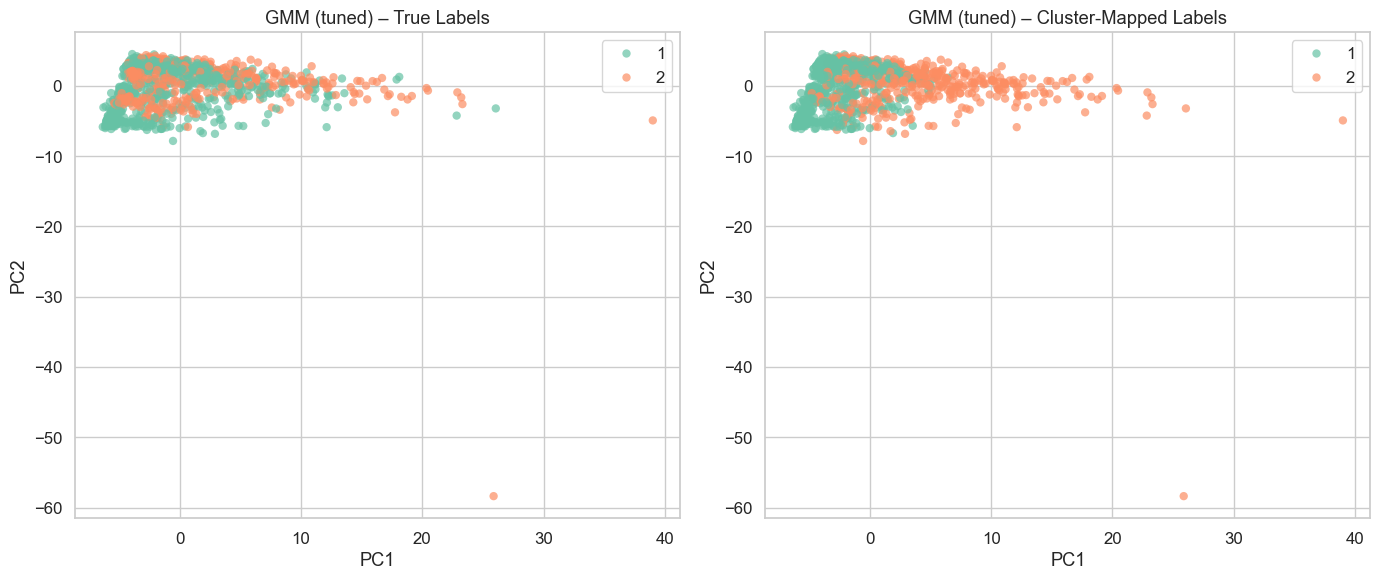


=== Spectral (tuned) – Metrics ===
ARI:          -0.0067
NMI:          0.0232
Homogeneity:  0.0229
Completeness: 0.0236
V-measure:    0.0232
Silhouette:   0.1294
Accuracy*:    0.6408  (after cluster→label mapping)

Confusion Matrix:
[[760   0]
 [426   0]]

Classification Report:
              precision    recall  f1-score   support

           1       0.64      1.00      0.78       760
           2       0.00      0.00      0.00       426

    accuracy                           0.64      1186
   macro avg       0.32      0.50      0.39      1186
weighted avg       0.41      0.64      0.50      1186



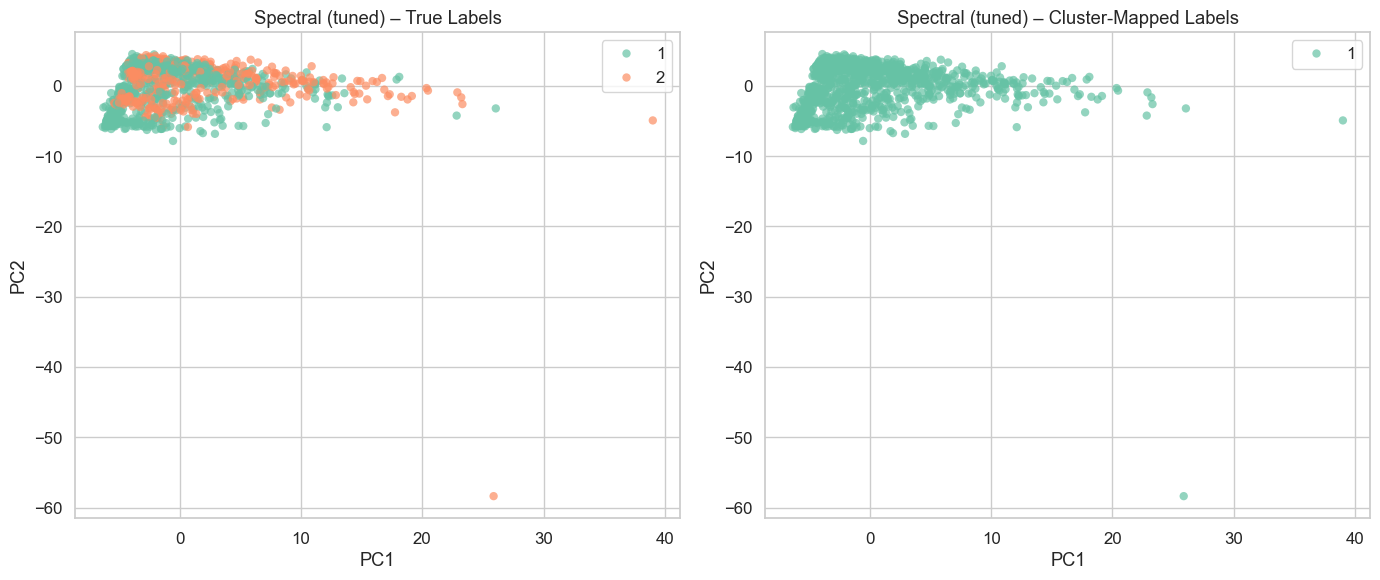


=== Unsupervised Clustering Summary (Optuna-tuned) ===


,Method,ARI,NMI,Homogeneity,Completeness,V-measure,Silhouette,LabelMapped_ACC
0,KMeans,0.081961,0.036780,0.032345,0.042626,0.036780,0.288439,0.665261
1,GMM,0.283016,0.200015,0.203170,0.196955,0.200015,0.134309,0.767285
2,Spectral,-0.006668,0.023227,0.022889,0.023575,0.023227,0.129401,0.640809


In [ ]:
# === CELL: Optuna-tuned KMeans / GMM / Spectral Clustering in PCA space ===

# If optuna is not installed:
# !pip install optuna

import numpy as np
import pandas as pd

import optuna

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    silhouette_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
)

import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 0. Prepare data and PCA space
# ---------------------------------------------------------
X_all_raw = X_raw
y_true_bin = y_bin

inv_label_mapping = {v: k for k, v in label_mapping.items()}
y_true_orig = np.vectorize(inv_label_mapping.get)(y_true_bin)
classes = np.unique(y_true_orig)
n_classes = len(classes)

print("Number of samples:", X_all_raw.shape[0])
print("Number of features:", X_all_raw.shape[1])
print("Classes:", classes)

# Use 27 PCA components (≈95% variance from before)
N_PCA_CLUSTER = min(27, X_all_raw.shape[1])

scaler_clust = StandardScaler().fit(X_all_raw)
X_scaled_clust = scaler_clust.transform(X_all_raw)

pca_clust = PCA(n_components=N_PCA_CLUSTER).fit(X_scaled_clust)
X_pca_clust = pca_clust.transform(X_scaled_clust)

# 2D PCA for visualization
X_pca_2d = X_pca_clust[:, :2]

palette_set2 = sns.color_palette("Set2", n_classes)
print("Using PCA components:", N_PCA_CLUSTER)

# ---------------------------------------------------------
# 1. Majority-vote label mapping (cluster -> label)
# ---------------------------------------------------------
def best_cluster_label_mapping(y_true_bin, cluster_labels):
    mapping = {}
    for c in np.unique(cluster_labels):
        mask = (cluster_labels == c)
        true_labels = y_true_bin[mask]
        majority = np.bincount(true_labels).argmax()
        mapping[c] = majority
    return mapping

# ---------------------------------------------------------
# 2. Evaluation helper (metrics + mapping)
# ---------------------------------------------------------
def evaluate_clustering(name, cluster_labels, X_feat, y_true_bin):
    y_true_bin = np.asarray(y_true_bin)
    cluster_labels = np.asarray(cluster_labels)

    # Unsupervised metrics
    ari = adjusted_rand_score(y_true_bin, cluster_labels)
    nmi = normalized_mutual_info_score(y_true_bin, cluster_labels)
    homo = homogeneity_score(y_true_bin, cluster_labels)
    comp = completeness_score(y_true_bin, cluster_labels)
    v_meas = v_measure_score(y_true_bin, cluster_labels)

    if len(np.unique(cluster_labels)) > 1:
        sil = silhouette_score(X_feat, cluster_labels)
    else:
        sil = np.nan

    # Label mapping
    mapping = best_cluster_label_mapping(y_true_bin, cluster_labels)
    y_pred_bin = np.array([mapping[c] for c in cluster_labels])
    acc = accuracy_score(y_true_bin, y_pred_bin)

    # Back to original labels
    y_true_orig2 = np.vectorize(inv_label_mapping.get)(y_true_bin)
    y_pred_orig2 = np.vectorize(inv_label_mapping.get)(y_pred_bin)

    cm = confusion_matrix(y_true_orig2, y_pred_orig2, labels=classes)
    cls_rep = classification_report(
        y_true_orig2,
        y_pred_orig2,
        labels=classes,
        zero_division=0,
    )

    print(f"\n=== {name} – Metrics ===")
    print(f"ARI:          {ari:.4f}")
    print(f"NMI:          {nmi:.4f}")
    print(f"Homogeneity:  {homo:.4f}")
    print(f"Completeness: {comp:.4f}")
    print(f"V-measure:    {v_meas:.4f}")
    print(f"Silhouette:   {sil:.4f}")
    print(f"Accuracy*:    {acc:.4f}  (after cluster→label mapping)")

    print("\nConfusion Matrix:")
    print(cm)
    print("\nClassification Report:")
    print(cls_rep)

    return {
        "ari": ari,
        "nmi": nmi,
        "homogeneity": homo,
        "completeness": comp,
        "v_measure": v_meas,
        "silhouette": sil,
        "accuracy": acc,
        "cluster_labels": cluster_labels,
        "y_pred_orig": y_pred_orig2,
    }

# ---------------------------------------------------------
# 3. Visualization helper
# ---------------------------------------------------------
def plot_2d(name, X_2d, y_true, y_pred, palette):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # True labels
    sns.scatterplot(
        x=X_2d[:, 0],
        y=X_2d[:, 1],
        hue=y_true,
        palette=palette,
        ax=axes[0],
        edgecolor="none",
        alpha=0.7,
    )
    axes[0].set_title(f"{name} – True Labels")
    axes[0].set_xlabel("PC1")
    axes[0].set_ylabel("PC2")

    # Cluster-mapped labels
    sns.scatterplot(
        x=X_2d[:, 0],
        y=X_2d[:, 1],
        hue=y_pred,
        palette=palette,
        ax=axes[1],
        edgecolor="none",
        alpha=0.7,
    )
    axes[1].set_title(f"{name} – Cluster-Mapped Labels")
    axes[1].set_xlabel("PC1")
    axes[1].set_ylabel("PC2")

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 4. Optuna tuning objectives (use ARI as objective)
# ---------------------------------------------------------
def objective_kmeans(trial):
    n_init = trial.suggest_int("n_init", 5, 30)
    max_iter = trial.suggest_int("max_iter", 100, 500)
    algorithm = trial.suggest_categorical("algorithm", ["lloyd", "elkan"])

    kmeans = KMeans(
        n_clusters=n_classes,
        n_init=n_init,
        max_iter=max_iter,
        algorithm=algorithm,
        random_state=42,
    )
    labels = kmeans.fit_predict(X_pca_clust)
    ari = adjusted_rand_score(y_true_bin, labels)
    return ari

def objective_gmm(trial):
    covariance_type = trial.suggest_categorical(
        "covariance_type",
        ["full", "tied", "diag", "spherical"]
    )
    reg_covar = trial.suggest_float("reg_covar", 1e-6, 1e-2, log=True)

    gmm = GaussianMixture(
        n_components=n_classes,
        covariance_type=covariance_type,
        reg_covar=reg_covar,
        random_state=42,
    )
    labels = gmm.fit_predict(X_pca_clust)
    ari = adjusted_rand_score(y_true_bin, labels)
    return ari

def objective_spectral(trial):
    n_neighbors = trial.suggest_int("n_neighbors", 5, 40)
    assign_labels = trial.suggest_categorical("assign_labels", ["kmeans", "discretize"])

    spectral = SpectralClustering(
        n_clusters=n_classes,
        affinity="nearest_neighbors",
        n_neighbors=n_neighbors,
        assign_labels=assign_labels,
        random_state=42,
    )
    labels = spectral.fit_predict(X_pca_clust)
    ari = adjusted_rand_score(y_true_bin, labels)
    return ari

# ---------------------------------------------------------
# 5. Run Optuna for each method
# ---------------------------------------------------------
n_trials = 25  # adjust up/down depending on time budget

print("\n=== Tuning KMeans with Optuna (objective = ARI) ===")
study_km = optuna.create_study(direction="maximize", study_name="kmeans_ari")
study_km.optimize(objective_kmeans, n_trials=n_trials, show_progress_bar=False)
print("Best KMeans params:", study_km.best_params)
print("Best KMeans ARI:   ", study_km.best_value)

print("\n=== Tuning GMM with Optuna (objective = ARI) ===")
study_gmm = optuna.create_study(direction="maximize", study_name="gmm_ari")
study_gmm.optimize(objective_gmm, n_trials=n_trials, show_progress_bar=False)
print("Best GMM params:", study_gmm.best_params)
print("Best GMM ARI:   ", study_gmm.best_value)

print("\n=== Tuning Spectral Clustering with Optuna (objective = ARI) ===")
study_spec = optuna.create_study(direction="maximize", study_name="spectral_ari")
study_spec.optimize(objective_spectral, n_trials=n_trials, show_progress_bar=False)
print("Best Spectral params:", study_spec.best_params)
print("Best Spectral ARI:   ", study_spec.best_value)

# ---------------------------------------------------------
# 6. Fit final models with best params and evaluate
# ---------------------------------------------------------
results = {}

# ----- KMeans final -----
best_km = KMeans(
    n_clusters=n_classes,
    n_init=study_km.best_params["n_init"],
    max_iter=study_km.best_params["max_iter"],
    algorithm=study_km.best_params["algorithm"],
    random_state=42,
)
labels_km = best_km.fit_predict(X_pca_clust)
res_km = evaluate_clustering("KMeans (tuned)", labels_km, X_pca_clust, y_true_bin)
results["KMeans"] = res_km
plot_2d("KMeans (tuned)", X_pca_2d, y_true_orig, res_km["y_pred_orig"], palette_set2)

# ----- GMM final -----
best_gmm = GaussianMixture(
    n_components=n_classes,
    covariance_type=study_gmm.best_params["covariance_type"],
    reg_covar=study_gmm.best_params["reg_covar"],
    random_state=42,
)
labels_gmm = best_gmm.fit_predict(X_pca_clust)
res_gmm = evaluate_clustering("GMM (tuned)", labels_gmm, X_pca_clust, y_true_bin)
results["GMM"] = res_gmm
plot_2d("GMM (tuned)", X_pca_2d, y_true_orig, res_gmm["y_pred_orig"], palette_set2)

# ----- Spectral Clustering final -----
best_spec = SpectralClustering(
    n_clusters=n_classes,
    affinity="nearest_neighbors",
    n_neighbors=study_spec.best_params["n_neighbors"],
    assign_labels=study_spec.best_params["assign_labels"],
    random_state=42,
)
labels_spec = best_spec.fit_predict(X_pca_clust)
res_spec = evaluate_clustering("Spectral (tuned)", labels_spec, X_pca_clust, y_true_bin)
results["Spectral"] = res_spec
plot_2d("Spectral (tuned)", X_pca_2d, y_true_orig, res_spec["y_pred_orig"], palette_set2)

# ---------------------------------------------------------
# 7. Summary table
# ---------------------------------------------------------
summary_df = pd.DataFrame([
    {
        "Method": name,
        "ARI": r["ari"],
        "NMI": r["nmi"],
        "Homogeneity": r["homogeneity"],
        "Completeness": r["completeness"],
        "V-measure": r["v_measure"],
        "Silhouette": r["silhouette"],
        "LabelMapped_ACC": r["accuracy"],
    }
    for name, r in results.items()
])

print("\n=== Unsupervised Clustering Summary (Optuna-tuned) ===")
display(summary_df)


Classes: [1 2]
X_train shape: (948, 102)
X_val shape: (238, 102)



Model: "AE_2D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 102)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        26,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 2)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 102)            │        26,214 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,984 (542.91 KB)

 Trainable params: 137,192 (535.91 KB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - loss: 1.1724 - val_loss: 0.8370
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.7498 - val_loss: 0.7825
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6585 - val_loss: 0.7453
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.5876 - val_loss: 0.7181
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5493 - val_loss: 0.6980
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5158 - val_loss: 0.6795
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4891 - val_loss: 0.6695
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4760 - val_loss: 0.6622
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4630 - val_loss: 0.6526
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4477 - val_loss: 0.6526
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.4506 - val_loss: 0.6410
Epoch 12/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.4207 - val_lo

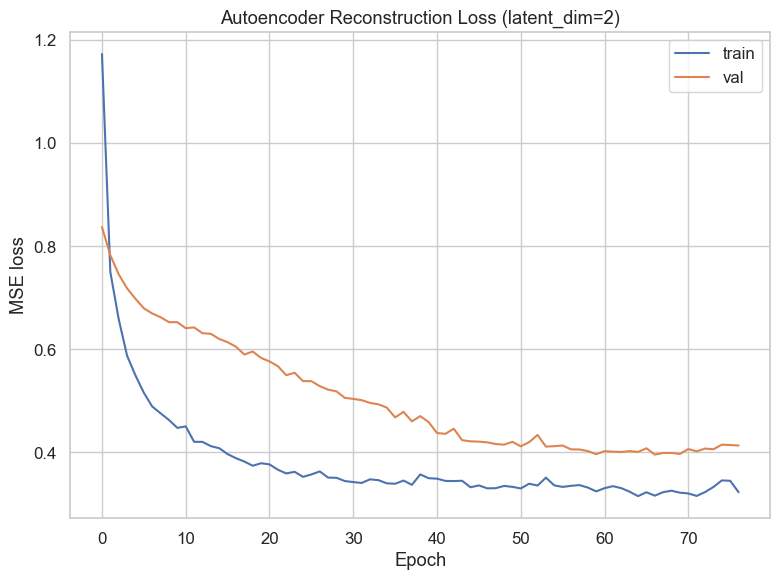

Latent space shape: (1186, 2)


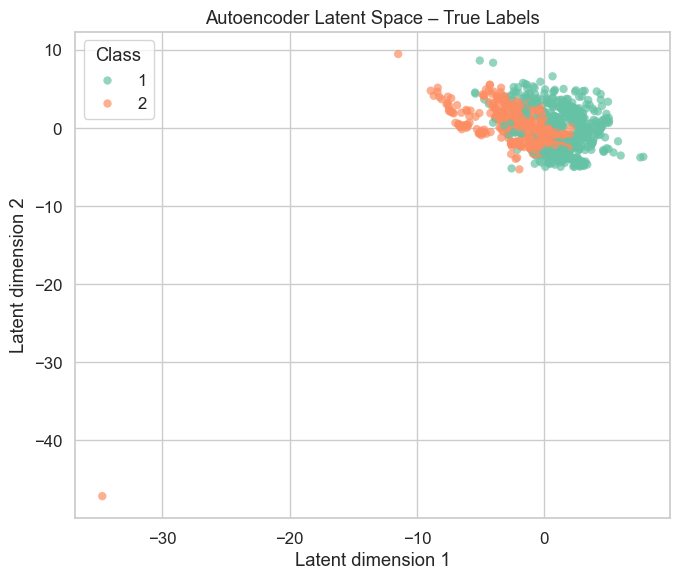

In [ ]:
# === CELL: Autoencoder latent space visualization (no K-Means) ===

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, models as keras_models, callbacks

import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 0. Prepare data
# ---------------------------------------------------------
X_all_raw = X_raw          # numeric features (NaNs already handled)
y_true_bin = y_bin         # {0,1}
inv_label_mapping = {v: k for k, v in label_mapping.items()}
y_true_orig = np.vectorize(inv_label_mapping.get)(y_true_bin)

classes = np.unique(y_true_orig)
n_classes = len(classes)
print("Classes:", classes)

# Standardize features for autoencoder
scaler_ae = StandardScaler().fit(X_all_raw)
X_scaled = scaler_ae.transform(X_all_raw)

# Train/val split for unsupervised AE training
X_train, X_val = train_test_split(
    X_scaled,
    test_size=0.2,
    random_state=42,
    shuffle=True,
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

# ---------------------------------------------------------
# 1. Build autoencoder (latent_dim = 2 for visualization)
# ---------------------------------------------------------
tf.keras.backend.clear_session()

input_dim = X_scaled.shape[1]
latent_dim = 2   # <---- 2D latent space for direct plotting

inputs = layers.Input(shape=(input_dim,))

x = layers.Dense(256)(inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation(tf.nn.gelu)(x)

x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation(tf.nn.gelu)(x)

x = layers.Dense(64)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation(tf.nn.gelu)(x)

# Latent (2D bottleneck)
z = layers.Dense(latent_dim, activation="linear", name="latent")(x)

# Decoder
x_dec = layers.Dense(64)(z)
x_dec = layers.BatchNormalization()(x_dec)
x_dec = layers.Activation(tf.nn.gelu)(x_dec)

x_dec = layers.Dense(128)(x_dec)
x_dec = layers.BatchNormalization()(x_dec)
x_dec = layers.Activation(tf.nn.gelu)(x_dec)

x_dec = layers.Dense(256)(x_dec)
x_dec = layers.BatchNormalization()(x_dec)
x_dec = layers.Activation(tf.nn.gelu)(x_dec)

outputs = layers.Dense(input_dim, activation="linear")(x_dec)

autoencoder = keras_models.Model(inputs, outputs, name="AE_2D")
encoder = keras_models.Model(inputs, z, name="Encoder_2D")

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
)

autoencoder.summary()

# ---------------------------------------------------------
# 2. Train autoencoder
# ---------------------------------------------------------
es_ae = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)

history = autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=100,
    batch_size=128,
    callbacks=[es_ae],
    verbose=1,
)

# Optional: plot reconstruction loss
plt.figure()
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Autoencoder Reconstruction Loss (latent_dim=2)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Get 2D latent representation for ALL samples
# ---------------------------------------------------------
Z_latent_2d = encoder.predict(X_scaled, verbose=0)
print("Latent space shape:", Z_latent_2d.shape)   # (N, 2)

# ---------------------------------------------------------
# 4. Visualize latent space colored by true labels
# ---------------------------------------------------------
palette_set2 = sns.color_palette("Set2", n_classes)

plt.figure(figsize=(7, 6))
sns.scatterplot(
    x=Z_latent_2d[:, 0],
    y=Z_latent_2d[:, 1],
    hue=y_true_orig,
    palette=palette_set2,
    alpha=0.7,
    edgecolor="none",
)
plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.title("Autoencoder Latent Space – True Labels")
plt.legend(title="Class")
plt.tight_layout()
plt.show()


Classes: [1 2]
X_train shape: (948, 102)
X_val shape: (238, 102)


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 102)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │     26,368 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256)       │      1,024 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64)        │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        130 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        130 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 69,572 (271.77 KB)

 Trainable params: 68,676 (268.27 KB)

 Non-trainable params: 896 (3.50 KB)

... (7 outputs left out)

 Total params: 139,114 (543.41 KB)

 Trainable params: 137,322 (536.41 KB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step - kl_loss: 1.7299 - loss: 123.8623 - recon_loss: 122.1323 - val_kl_loss: 0.4221 - val_loss: 87.1870 - val_recon_loss: 86.7648
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - kl_loss: 3.8722 - loss: 85.0959 - recon_loss: 81.2237 - val_kl_loss: 1.7957 - val_loss: 83.5052 - val_recon_loss: 81.7095
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - kl_loss: 4.6821 - loss: 74.8177 - recon_loss: 70.1356 - val_kl_loss: 2.8568 - val_loss: 79.0865 - val_recon_loss: 76.2297
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - kl_loss: 4.7629 - loss: 87.1947 - recon_loss: 82.4318 - val_kl_loss: 3.4012 - val_loss: 77.9488 - val_recon_loss: 74.5475
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - kl_loss: 4.5492 - loss: 80.9245 - recon_loss: 76.3753 - val_kl_loss: 3.7383 - val_loss: 76.1862 - val_recon_loss: 72.4480
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - kl_loss: 4.3503 - loss: 63.2274 - recon_loss: 58.8771 - val_kl_loss: 3.3747 

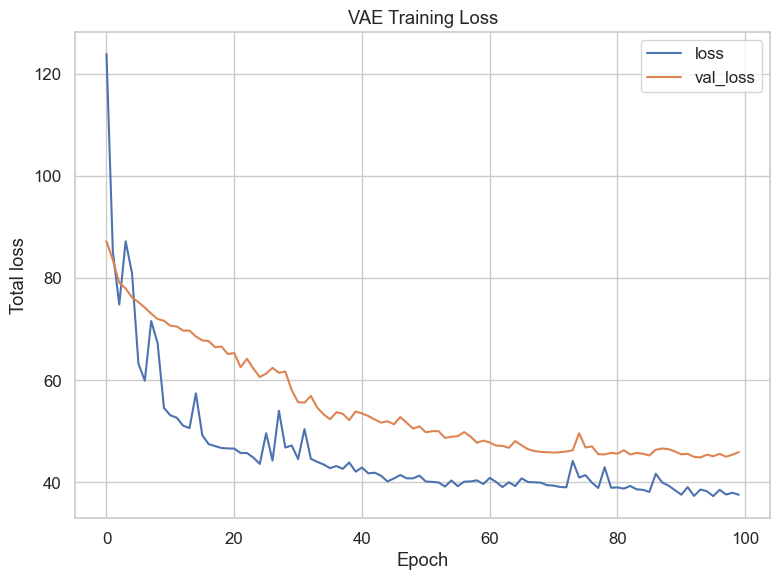

z_mean_all shape: (1186, 2)


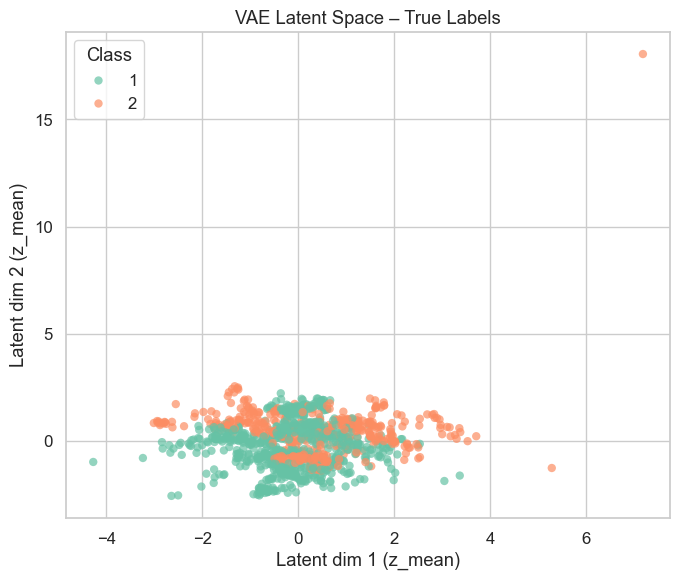

In [ ]:
# === CELL: VAE (2D latent) + latent visualization + optional KMeans ===

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    silhouette_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
)

import tensorflow as tf
from tensorflow.keras import layers, models as keras_models, callbacks
import tensorflow.keras.backend as K

import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 0. Prepare data
# ---------------------------------------------------------
X_all_raw = X_raw
y_true_bin = y_bin

inv_label_mapping = {v: k for k, v in label_mapping.items()}
y_true_orig = np.vectorize(inv_label_mapping.get)(y_true_bin)

classes = np.unique(y_true_orig)
n_classes = len(classes)
print("Classes:", classes)

# Scale
scaler_vae = StandardScaler().fit(X_all_raw)
X_scaled = scaler_vae.transform(X_all_raw)

X_train, X_val = train_test_split(
    X_scaled,
    test_size=0.2,
    random_state=42,
    shuffle=True,
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

input_dim = X_scaled.shape[1]
latent_dim = 2  # 2D latent for visualization

# ---------------------------------------------------------
# 1. Sampling layer for VAE
# ---------------------------------------------------------
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# ---------------------------------------------------------
# 2. Build encoder and decoder
# ---------------------------------------------------------
tf.keras.backend.clear_session()

# Encoder
encoder_inputs = layers.Input(shape=(input_dim,), name="encoder_input")

x = layers.Dense(256)(encoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation(tf.nn.gelu)(x)

x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation(tf.nn.gelu)(x)

x = layers.Dense(64)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation(tf.nn.gelu)(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling(name="z")([z_mean, z_log_var])

encoder = keras_models.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

# Decoder
latent_inputs = layers.Input(shape=(latent_dim,), name="z_sampling")

xd = layers.Dense(64)(latent_inputs)
xd = layers.BatchNormalization()(xd)
xd = layers.Activation(tf.nn.gelu)(xd)

xd = layers.Dense(128)(xd)
xd = layers.BatchNormalization()(xd)
xd = layers.Activation(tf.nn.gelu)(xd)

xd = layers.Dense(256)(xd)
xd = layers.BatchNormalization()(xd)
xd = layers.Activation(tf.nn.gelu)(xd)

decoder_outputs = layers.Dense(input_dim, activation="linear")(xd)

decoder = keras_models.Model(latent_inputs, decoder_outputs, name="decoder")
decoder.summary()

# ---------------------------------------------------------
# 3. Custom VAE model with train_step
# ---------------------------------------------------------
class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, beta_kl=1.0, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta_kl = beta_kl
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.recon_loss_tracker = tf.keras.metrics.Mean(name="recon_loss")
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        if isinstance(data, tuple):
            x = data[0]
        else:
            x = data

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(x, training=True)
            x_recon = self.decoder(z, training=True)

            # Reconstruction loss (MSE per sample, then mean)
            recon_loss = tf.reduce_sum(tf.square(x - x_recon), axis=1)
            recon_loss = tf.reduce_mean(recon_loss)

            # KL divergence loss
            kl_loss = -0.5 * tf.reduce_sum(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1
            )
            kl_loss = tf.reduce_mean(kl_loss)

            total_loss = recon_loss + self.beta_kl * kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        if isinstance(data, tuple):
            x = data[0]
        else:
            x = data

        z_mean, z_log_var, z = self.encoder(x, training=False)
        x_recon = self.decoder(z, training=False)

        recon_loss = tf.reduce_sum(tf.square(x - x_recon), axis=1)
        recon_loss = tf.reduce_mean(recon_loss)

        kl_loss = -0.5 * tf.reduce_sum(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1
        )
        kl_loss = tf.reduce_mean(kl_loss)

        total_loss = recon_loss + self.beta_kl * kl_loss

        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

vae = VAE(encoder, decoder, beta_kl=1.0)
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3))
vae.summary()

# ---------------------------------------------------------
# 4. Train VAE
# ---------------------------------------------------------
es_vae = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)

history = vae.fit(
    X_train,
    X_train,    # dummy; train_step ignores y
    validation_data=(X_val, X_val),
    epochs=100,
    batch_size=128,
    callbacks=[es_vae],
    verbose=1,
)

# Plot training curves
plt.figure()
plt.plot(history.history["loss"], label="loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.title("VAE Training Loss")
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. Latent means for all samples
# ---------------------------------------------------------
z_mean_all, z_log_var_all, z_all = encoder.predict(X_scaled, verbose=0)
print("z_mean_all shape:", z_mean_all.shape)   # (N, 2)

Z_2d = z_mean_all

# ---------------------------------------------------------
# 6. Visualize VAE latent space (true labels)
# ---------------------------------------------------------
palette_set2 = sns.color_palette("Set2", n_classes)

plt.figure(figsize=(7, 6))
sns.scatterplot(
    x=Z_2d[:, 0],
    y=Z_2d[:, 1],
    hue=y_true_orig,
    palette=palette_set2,
    alpha=0.7,
    edgecolor="none",
)
plt.xlabel("Latent dim 1 (z_mean)")
plt.ylabel("Latent dim 2 (z_mean)")
plt.title("VAE Latent Space – True Labels")
plt.legend(title="Class")
plt.tight_layout()
plt.show()


Classes: [1 2]
Unique subjects: [ 2  3  4  5  6  7  8  9 10 11 13 14 15 16 17]
Train subjects: [16  7 10  4  3 17  6  9 13 15  5  8]
Test subjects: [11 14  2]
Train samples: 951  Test samples: 235
X_tr shape: (760, 102) X_val shape: (191, 102)


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 102)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │     26,368 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256)       │      1,024 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64)        │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 6)         │        390 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 6)         │        390 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 6)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 70,092 (273.80 KB)

 Trainable params: 69,196 (270.30 KB)

 Non-trainable params: 896 (3.50 KB)

... (7 outputs left out)

 Total params: 139,890 (546.45 KB)

 Trainable params: 138,098 (539.45 KB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - kl_loss: 3.9203 - loss: 143.5593 - recon_loss: 139.6390 - val_kl_loss: 0.9134 - val_loss: 77.8808 - val_recon_loss: 76.9674
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - kl_loss: 5.1585 - loss: 105.5974 - recon_loss: 100.4389 - val_kl_loss: 1.9482 - val_loss: 75.7591 - val_recon_loss: 73.8109
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - kl_loss: 6.0783 - loss: 87.9317 - recon_loss: 81.8534 - val_kl_loss: 2.7612 - val_loss: 71.6376 - val_recon_loss: 68.8764
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - kl_loss: 6.5216 - loss: 76.1556 - recon_loss: 69.6340 - val_kl_loss: 3.1692 - val_loss: 68.7021 - val_recon_loss: 65.5329
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - kl_loss: 6.7867 - loss: 70.3152 - recon_loss: 63.5285 - val_kl_loss: 3.5467 - val_loss: 65.3038 - val_recon_loss: 61.7571
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - kl_loss: 6.9265 - loss: 65.6425 - recon_loss: 58.7160 - val_kl_loss: 3.688

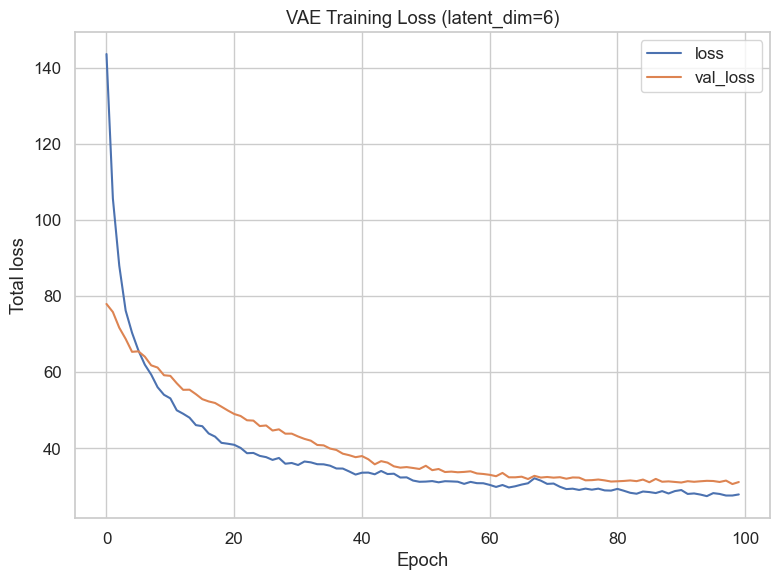

Train latent shape: (951, 6)
Test latent shape: (235, 6)


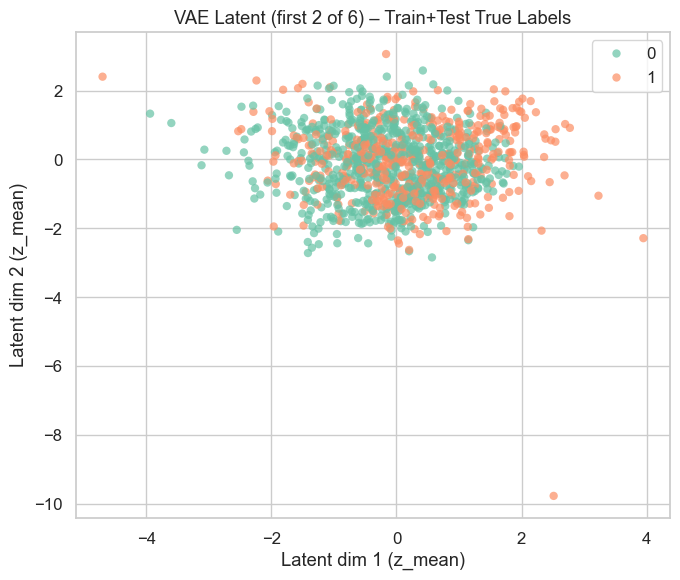

Latent train shape: (951, 6) Latent test shape: (235, 6)


Model: "latent_MLP_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,753 (10.75 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7382 - loss: 0.5544 - val_accuracy: 0.7382 - val_loss: 0.6481
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8711 - loss: 0.3934 - val_accuracy: 0.7853 - val_loss: 0.6070
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8882 - loss: 0.3339 - val_accuracy: 0.8115 - val_loss: 0.5749
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9079 - loss: 0.2877 - val_accuracy: 0.8115 - val_loss: 0.5510
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9079 - loss: 0.2597 - val_accuracy: 0.8063 - val_loss: 0.5329
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9197 - loss: 0.2406 - val_accuracy: 0.8220 - val_loss: 0.5161
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9171 - loss: 0.2269 - val_accuracy: 0.8429 - val_loss: 0.4979
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9237 - loss: 0.2163 - val_accuracy: 0.8639 - 

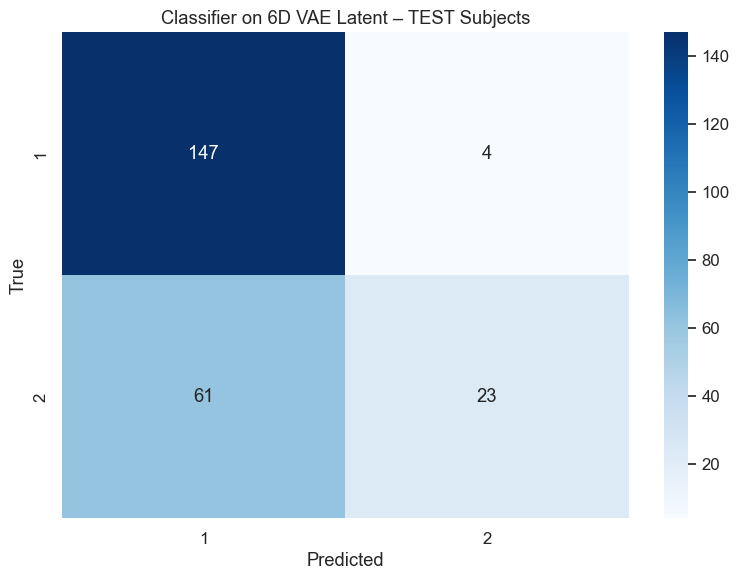

In [ ]:
# === SUBJECT-WISE VAE (latent_dim=6) + KMeans + MLP classifier ===

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    silhouette_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
)

import tensorflow as tf
from tensorflow.keras import layers, models as keras_models, callbacks
import tensorflow.keras.backend as K

import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 0. Prepare data (SUBJECT-WISE split)
# ---------------------------------------------------------
# X_raw: numeric features (DataFrame or ndarray)
# y_bin: labels in {0,1}
# subjects: array-like of subject IDs, length == len(X_raw)

# Ensure numpy arrays
X_all_raw = X_raw.values if isinstance(X_raw, pd.DataFrame) else X_raw
y_true_bin = np.asarray(y_bin)
subj_ids = np.asarray(subjects)

inv_label_mapping = {v: k for k, v in label_mapping.items()}
y_true_orig = np.vectorize(inv_label_mapping.get)(y_true_bin)

classes = np.unique(y_true_orig)
n_classes = len(classes)
print("Classes:", classes)

unique_subs = np.unique(subj_ids)
print("Unique subjects:", unique_subs)

# Example: 80% subjects train, 20% test
train_subs, test_subs = train_test_split(
    unique_subs,
    test_size=0.2,
    random_state=42,
)

print("Train subjects:", train_subs)
print("Test subjects:", test_subs)

train_mask = np.isin(subj_ids, train_subs)
test_mask  = np.isin(subj_ids, test_subs)

X_train_raw = X_all_raw[train_mask]
X_test_raw  = X_all_raw[test_mask]
y_train_bin = y_true_bin[train_mask]
y_test_bin  = y_true_bin[test_mask]

print("Train samples:", X_train_raw.shape[0], " Test samples:", X_test_raw.shape[0])

# ---- Scale based only on TRAIN subjects ----
scaler_vae = StandardScaler().fit(X_train_raw)
X_train_scaled = scaler_vae.transform(X_train_raw)
X_test_scaled  = scaler_vae.transform(X_test_raw)

# Internal val split for VAE (within train subjects)
X_tr, X_val = train_test_split(
    X_train_scaled,
    test_size=0.2,
    random_state=42,
    shuffle=True,
)

print("X_tr shape:", X_tr.shape, "X_val shape:", X_val.shape)

input_dim = X_train_scaled.shape[1]
latent_dim = 6   # 6D latent space

# ---------------------------------------------------------
# 1. Sampling layer
# ---------------------------------------------------------
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# ---------------------------------------------------------
# 2. Build encoder and decoder
# ---------------------------------------------------------
tf.keras.backend.clear_session()

# Encoder
encoder_inputs = layers.Input(shape=(input_dim,), name="encoder_input")

x = layers.Dense(256)(encoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation(tf.nn.gelu)(x)

x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation(tf.nn.gelu)(x)

x = layers.Dense(64)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation(tf.nn.gelu)(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling(name="z")([z_mean, z_log_var])

encoder = keras_models.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

# Decoder
latent_inputs = layers.Input(shape=(latent_dim,), name="z_sampling")

xd = layers.Dense(64)(latent_inputs)
xd = layers.BatchNormalization()(xd)
xd = layers.Activation(tf.nn.gelu)(xd)

xd = layers.Dense(128)(xd)
xd = layers.BatchNormalization()(xd)
xd = layers.Activation(tf.nn.gelu)(xd)

xd = layers.Dense(256)(xd)
xd = layers.BatchNormalization()(xd)
xd = layers.Activation(tf.nn.gelu)(xd)

decoder_outputs = layers.Dense(input_dim, activation="linear")(xd)

decoder = keras_models.Model(latent_inputs, decoder_outputs, name="decoder")
decoder.summary()

# ---------------------------------------------------------
# 3. Custom VAE model
# ---------------------------------------------------------
class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, beta_kl=1.0, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta_kl = beta_kl
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.recon_loss_tracker = tf.keras.metrics.Mean(name="recon_loss")
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker,
                self.recon_loss_tracker,
                self.kl_loss_tracker]

    def train_step(self, data):
        if isinstance(data, tuple):
            x = data[0]
        else:
            x = data

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(x, training=True)
            x_recon = self.decoder(z, training=True)

            recon_loss = tf.reduce_sum(tf.square(x - x_recon), axis=1)
            recon_loss = tf.reduce_mean(recon_loss)

            kl_loss = -0.5 * tf.reduce_sum(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                axis=1,
            )
            kl_loss = tf.reduce_mean(kl_loss)

            total_loss = recon_loss + self.beta_kl * kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        if isinstance(data, tuple):
            x = data[0]
        else:
            x = data

        z_mean, z_log_var, z = self.encoder(x, training=False)
        x_recon = self.decoder(z, training=False)

        recon_loss = tf.reduce_sum(tf.square(x - x_recon), axis=1)
        recon_loss = tf.reduce_mean(recon_loss)

        kl_loss = -0.5 * tf.reduce_sum(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
            axis=1,
        )
        kl_loss = tf.reduce_mean(kl_loss)

        total_loss = recon_loss + self.beta_kl * kl_loss

        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

vae = VAE(encoder, decoder, beta_kl=1.0)
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3))
vae.summary()

# ---------------------------------------------------------
# 4. Train VAE on TRAIN subjects only
# ---------------------------------------------------------
es_vae = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)

history = vae.fit(
    X_tr,
    X_tr,   # dummy target
    validation_data=(X_val, X_val),
    epochs=100,
    batch_size=128,
    callbacks=[es_vae],
    verbose=1,
)

plt.figure()
plt.plot(history.history["loss"], label="loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.title("VAE Training Loss (latent_dim=6)")
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. Latent means (6D) for TRAIN and TEST subjects
# ---------------------------------------------------------
z_mean_train, z_log_var_train, z_train = encoder.predict(X_train_scaled, verbose=0)
z_mean_test,  z_log_var_test,  z_test  = encoder.predict(X_test_scaled,  verbose=0)

print("Train latent shape:", z_mean_train.shape)
print("Test latent shape:", z_mean_test.shape)

Z_train = z_mean_train
Z_test  = z_mean_test

# Quick 2D view of first two dims (train+test together)
plt.figure(figsize=(7, 6))
palette_set2 = sns.color_palette("Set2", n_classes)
sns.scatterplot(
    x=np.concatenate([Z_train[:, 0], Z_test[:, 0]]),
    y=np.concatenate([Z_train[:, 1], Z_test[:, 1]]),
    hue=np.concatenate([y_train_bin, y_test_bin]),
    palette=palette_set2,
    alpha=0.7,
    edgecolor="none",
)
plt.xlabel("Latent dim 1 (z_mean)")
plt.ylabel("Latent dim 2 (z_mean)")
plt.title("VAE Latent (first 2 of 6) – Train+Test True Labels")
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 6. MLP classification on 6D latent space (train subj → test subj)
# ---------------------------------------------------------
X_tr_lat, y_tr_lat = Z_train, y_train_bin
X_te_lat, y_te_lat = Z_test,  y_test_bin

print("Latent train shape:", X_tr_lat.shape, "Latent test shape:", X_te_lat.shape)

tf.keras.backend.clear_session()

clf_inputs = layers.Input(shape=(latent_dim,))

h = layers.Dense(64)(clf_inputs)
h = layers.BatchNormalization()(h)
h = layers.Activation(tf.nn.gelu)(h)

h = layers.Dense(32)(h)
h = layers.BatchNormalization()(h)
h = layers.Activation(tf.nn.gelu)(h)

clf_outputs = layers.Dense(1, activation="sigmoid")(h)

clf_model = keras_models.Model(clf_inputs, clf_outputs, name="latent_MLP_classifier")
clf_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

clf_model.summary()

es_clf = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)

history_clf = clf_model.fit(
    X_tr_lat,
    y_tr_lat,
    validation_split=0.2,   # val from TRAIN subjects only
    epochs=100,
    batch_size=64,
    callbacks=[es_clf],
    verbose=1,
)

# Evaluate on TEST subjects
y_prob_te = clf_model.predict(X_te_lat, verbose=0).ravel()
y_pred_te = (y_prob_te >= 0.5).astype(int)

acc_test = accuracy_score(y_te_lat, y_pred_te)
print(f"\n=== MLP Classifier on 6D VAE latent – TEST subjects accuracy: {acc_test:.4f} ===")

y_te_orig = np.vectorize(inv_label_mapping.get)(y_te_lat)
y_pred_te_orig = np.vectorize(inv_label_mapping.get)(y_pred_te)

cm_clf = confusion_matrix(y_te_orig, y_pred_te_orig, labels=classes)
print("\nConfusion Matrix (Classifier on latent – TEST subjects):")
print(cm_clf)

print("\nClassification Report (Classifier on latent – TEST subjects):")
print(classification_report(y_te_orig, y_pred_te_orig, labels=classes, zero_division=0))

plt.figure()
sns.heatmap(
    cm_clf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Classifier on 6D VAE Latent – TEST Subjects")
plt.tight_layout()
plt.show()
